# 05. 변환·파생변수 — 전체 11단계 중 5단계

이 노트북은 작업하며 주고받은 답변(✍️ 칸과 클로드의 답변)을 빼고, 코드 · 결과 · 물음마다의 결론(📌)만 남긴 판이다. 단계마다 한 일과 정한 것은 README 「전체 흐름」에 있다.

In [922]:
# 5단계 파생변수 · 준비 ①
import os                                      # 폴더와 파일 경로를 다루는 기본 모듈
import numpy as np                             # 조건에 따라 값을 고르는 계산에 쓴다
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt                # 그림을 그리는 라이브러리
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
plt.rcParams["font.family"] = "AppleGothic"    # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False     # 그림의 마이너스 부호가 깨지지 않게
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
HOT = os.path.join(ROOT, "data", "hot")        # 3단계가 만들어 둔 정제된 표가 있는 폴더
RAW = os.path.join(ROOT, "data", "raw")        # 원자료 폴더 — 공휴일 파일과 3-라의 기상청 원자료를 읽는다

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [923]:
# 5단계 파생변수 · 준비 ②
tbl = pd.read_csv(os.path.join(HOT, "clean_2023_2024_2025.csv"), encoding="utf-8-sig")  # 3단계가 만든 표를 읽는다
tbl["ts"] = pd.to_datetime(tbl["ts"])            # 파일에 글자로 저장된 시각을 다시 시각 자료형으로

hol = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")   # 2단계에서 받아 둔 공휴일 78일
공휴일날짜 = set(pd.to_datetime(hol["date"]).dt.date)                             # 날짜만 뽑아 한 덩어리로 모은다
tbl["is_holiday"] = tbl["ts"].dt.date.isin(공휴일날짜).astype(int)                 # 그 시각의 날짜가 공휴일이면 1, 아니면 0

학습해 = [2023, 2024]                             # 학습에 쓸 해 — 2024년은 2월 29일과 8월 한 달이 빠져 334일이다
train = tbl[tbl["year"].isin(학습해)].copy()       # 학습 기간 — 재료는 여기서만 뽑는다
valid = tbl[tbl["year"] == 2025].copy()           # 채점 기간 — 2025년은 결정을 내리는 데 쓰지 않는다

print("표 모양 (행, 열):", tbl.shape, "· 빈 칸 합계:", int(tbl.isna().sum().sum()))
print("학습", 학습해, len(train), "행 / 채점 2025", len(valid), "행")
print("열 이름:", ", ".join(tbl.columns))
print()
요약 = tbl.groupby("year").agg(행수=("ts", "size"), 시작=("ts", "min"),
                              끝=("ts", "max"), 공휴일시각=("is_holiday", "sum"))
display(요약)

표 모양 (행, 열): (25536, 14) · 빈 칸 합계: 0
학습 [2023, 2024] 16776 행 / 채점 2025 8760 행
열 이름: ts, lng_mwh, nuke_mwh, solar_cap_mw, ta, hm, icsr, year, month, hour24, dow, is_weekend, solar_mwh, is_holiday



,행수,시작,끝,공휴일시각
year,,,,
2023,8760,2023-01-01,2023-12-31 23:00:00,432
2024,8016,2024-01-01,2024-12-31 23:00:00,432
2025,8760,2025-01-01,2025-12-31 23:00:00,456


# 물음 1 — 기온을 어떤 숫자로 바꿔 넣을까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 4단계 1-라에서 기온 그대로의 상관은 −0.06인데 16도 기준으로 바꾸면 0.359가 나왔다. 추울 때와 더울 때 둘 다 LNG가 올라 두 방향이 서로 지워진 것이라, 기온을 어떤 숫자로 넣을지 정한 물음이다.

### 결정 — 7단계로 넘길 기온 방식 넷: 기온 그대로(트리용) · 16·24도 · 10·16·24도(16~24도 평평) · 9·12·24도(구간마다 기울기)

**결정 근거** — 1-마에서 난방 16도·냉방 24도로 나누면 시간대·월을 고정한 R²가 0.501이었고, 냉방 기준 23~27도는 0.500~0.502로 같았다. 1-사·1-아·1-자에서 더 잘게 나누거나, 선을 끊거나, 16~24도에 기울기를 줘도 0.502 안쪽이었다(0.002 안쪽은 같다고 봤다). 16~24도에 기울기를 주는 방식은 09-24에 빠뜨렸다가 1-자에서 확인했다. 판단은 1-자 「✍️ 읽고 나서」 ②에 적었다 — 계산 시간 차이가 없으니 셋으로 가고, 그래프에서 보이는 9·12·24도도 넣는다. 클로드 제안은 기온 그대로와 16·24도 둘이었다.

**남은 것** — 선형회귀용 셋은 7단계에서 2024년 검증으로 비교하고, 16·24도보다 나아지지 않는 것은 거기서 뺀다. 16~24도 기울기가 음수로 나온 것은 물음 3의 3-다에서 햇빛 때문이었다고 확인했다. 물음 4에서 16·24도 × 시간대(48열)를 선형회귀용으로 하나 더 넘겨, 넘기는 지금 기온 방식은 모두 다섯이 됐다(물음 4 결론 칸).

→ **이어진 곳(10-05)** — 7단계까지 미루지 않고 6단계에서 줄였다. 10·16·24도와 9·12·24도는 2023년으로 배워 2024년을 맞힌 R²가 16·24도보다 나아지지 않아 뺐다(6단계 닫는 칸 ① 첫 줄, 09-30, 클로드 판단 · 4-가 [표 B]). 7단계에는 선형회귀에 16·24도, 기온 × 시간대 선형회귀에 16·24도 × 시간대, 트리 계열에 기온 그대로를 넘긴다(6단계 물음 4·6).

</div>

## 1-가

**무엇을 보는 셀인가.** 기준온도 후보 여섯(12·14·16·18·20·22도)마다 ⓑ와 ⓒ의 상관이 얼마인지 표로 냅니다. 「난방도>0 시각」과 「냉방도>0 시각」은 그 기준으로 갈랐을 때 각 쪽에 몇 시각이 들어가는지입니다 — 한쪽이 너무 적으면 그 열은 모델이 배울 재료가 모자랍니다. 학습 기간(2023+2024, 16,776시각)만 씁니다. 2025년은 채점용이라 여기서 보지 않습니다.

In [924]:
# 5단계 파생변수 · 1-가
표 = []                                                              # 기준온도마다 한 줄씩 담을 목록
for 기준 in (12, 14, 16, 18, 20, 22):                                 # 기준온도 후보 여섯
    난방도 = (기준 - train["ta"]).clip(lower=0)                        # 기준보다 추운 만큼. 더우면 0으로 깎는다
    냉방도 = (train["ta"] - 기준).clip(lower=0)                        # 기준보다 더운 만큼. 추우면 0으로 깎는다
    떨어진정도 = (train["ta"] - 기준).abs()                            # 부호를 떼고 떨어진 거리만 — ⓑ가 쓰는 값
    표.append({"기준온도": 기준,
               "ⓑ |기온-기준|": round(train["lng_mwh"].corr(떨어진정도), 3),   # LNG와의 상관
               "ⓒ 난방도": round(train["lng_mwh"].corr(난방도), 3),
               "ⓒ 냉방도": round(train["lng_mwh"].corr(냉방도), 3),
               "난방도>0 시각": int((난방도 > 0).sum()),                 # 그 기준보다 추웠던 시각 수
               "냉방도>0 시각": int((냉방도 > 0).sum())})                # 그 기준보다 더웠던 시각 수

print("ⓐ 기온을 그대로 넣을 때의 상관:", round(train["lng_mwh"].corr(train["ta"]), 3))
print("기준온도를 바꿔 가며 본 상관 — 학습 기간(2023+2024) 16,776시각")
display(pd.DataFrame(표).set_index("기준온도"))

ⓐ 기온을 그대로 넣을 때의 상관: -0.06
기준온도를 바꿔 가며 본 상관 — 학습 기간(2023+2024) 16,776시각


,ⓑ |기온-기준|,ⓒ 난방도,ⓒ 냉방도,난방도>0 시각,냉방도>0 시각
기준온도,,,,,
12,0.307,0.202,0.081,6952,9794
14,0.354,0.200,0.118,7865,8862
16,0.359,0.191,0.155,8824,7900
18,0.330,0.177,0.192,9812,6914
20,0.285,0.160,0.228,10918,5809
22,0.235,0.140,0.263,11908,4805


## 1-나

**무엇을 보는 셀인가.** 기온을 2도 폭으로 묶어 구간마다 LNG 평균을 냅니다. 평균이 가장 낮은 구간이 기준온도의 후보입니다. 시각 수를 같이 내는 것은 양 끝 구간의 표본이 적기 때문입니다 — 평균 하나가 열몇 시각으로 만들어진 것이라면 그 점은 흔들립니다. 표와 그림은 같은 값입니다.

기온 2도 구간별 LNG 발전량 평균 — 학습 기간만. 평균이 가장 낮은 구간이 바닥이다


,시각수,평균
구간,,
-18.0,15,19789.0
-16.0,15,22556.0
-14.0,42,20218.0
-12.0,78,20968.0
-10.0,103,23196.0
-8.0,152,21613.0
-6.0,253,20222.0
-4.0,494,19591.0
-2.0,838,19164.0


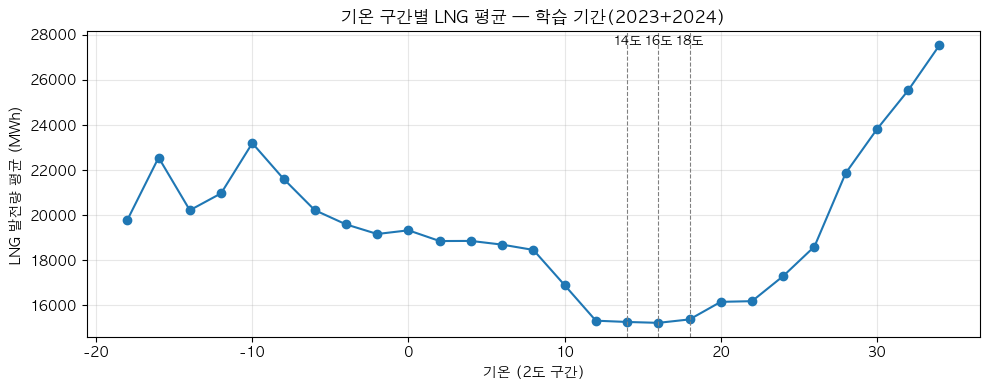

In [925]:
# 5단계 파생변수 · 1-나
구간 = (train.assign(구간=(train["ta"] // 2 * 2))                       # 기온을 2도 폭으로 내림해서 묶는다
        .groupby("구간")["lng_mwh"]
        .agg(시각수="size", 평균="mean").round(0))                       # 구간마다 시각 수와 LNG 평균

print("기온 2도 구간별 LNG 발전량 평균 — 학습 기간만. 평균이 가장 낮은 구간이 바닥이다")
display(구간)

plt.figure(figsize=(10, 4))
plt.plot(구간.index, 구간["평균"], marker="o")                           # 구간 평균을 선으로 잇는다
for 후보 in (14, 16, 18):                                              # 기준온도 후보를 세로선으로 표시
    plt.axvline(후보, ls="--", lw=.8, color="gray")
    plt.text(후보, 구간["평균"].max(), f"{후보}도", ha="center", fontsize=9)
plt.xlabel("기온 (2도 구간)"); plt.ylabel("LNG 발전량 평균 (MWh)")
plt.title("기온 구간별 LNG 평균 — 학습 기간(2023+2024)")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 1-다

**무엇을 보는 셀인가.** 4단계에서 상관이 가장 컸던 16도를 기준으로 삼아, 가로축에 「기준에서 몇 도 떨어졌나」를 두고 추운 쪽과 더운 쪽을 선 둘로 나란히 그립니다. 두 선이 겹쳐 가면 ⓑ, 갈라지면 ⓒ입니다. 기준온도를 바꿔 보시려면 셀 안 `기준 = 16`의 숫자만 고쳐서 다시 돌리시면 됩니다.

표에서 한쪽이 빈 칸(NaN)인 줄은 그 방향으로 그만큼 떨어진 시각이 학습 기간에 없었다는 뜻입니다.

기준 16도에서 떨어진 정도별 LNG 평균 — 두 선의 기울기가 같은가


쪽,더운 쪽,추운 쪽
구간,,
0.0,15221.0,15238.0
2.0,15373.0,15299.0
4.0,16153.0,16827.0
6.0,16183.0,18415.0
8.0,17298.0,18766.0
10.0,18609.0,18727.0
12.0,21866.0,18916.0
14.0,23813.0,19345.0
16.0,25538.0,19088.0


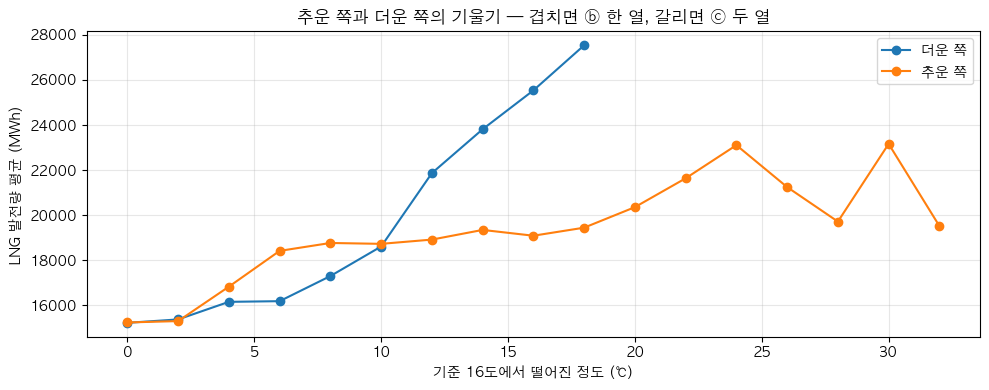

In [926]:
# 5단계 파생변수 · 1-다
기준 = 16                                                             # 4단계에서 상관이 가장 컸던 온도. 바꿔 보셔도 된다
d = train.assign(떨어진=(train["ta"] - 기준).abs(),                     # 기준에서 떨어진 거리
                 쪽=np.where(train["ta"] < 기준, "추운 쪽", "더운 쪽"))   # 기준보다 낮으면 추운 쪽
양쪽 = (d.assign(구간=(d["떨어진"] // 2 * 2))                            # 떨어진 거리를 2도 폭으로 묶는다
        .groupby(["구간", "쪽"])["lng_mwh"].mean()
        .unstack("쪽").round(0))                                       # 추운 쪽과 더운 쪽을 열 둘로 펼친다

print(f"기준 {기준}도에서 떨어진 정도별 LNG 평균 — 두 선의 기울기가 같은가")
display(양쪽)

plt.figure(figsize=(10, 4))
for 쪽 in 양쪽.columns:
    plt.plot(양쪽.index, 양쪽[쪽], marker="o", label=쪽)                # 쪽마다 선 하나
plt.xlabel(f"기준 {기준}도에서 떨어진 정도 (℃)"); plt.ylabel("LNG 발전량 평균 (MWh)")
plt.title("추운 쪽과 더운 쪽의 기울기 — 겹치면 ⓑ 한 열, 갈리면 ⓒ 두 열")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 1-라

**무엇을 보는 셀인가.** 기준온도를 10도부터 28도까지 1도씩 바꿔 가며, 그 기준으로 만든 ⓑ 한 열과 ⓒ 두 열로 LNG에 직선을 실제로 맞춰 봅니다. 그 직선이 LNG의 오르내림을 얼마나 설명하는지를 R²(결정계수)로 냅니다. R²는 0~1이고 1에 가까울수록 많이 설명합니다. **ⓑ와 ⓒ 각각에서 R²가 가장 큰 기준온도가 몇 도인지** 보시면 됩니다. 오른쪽 두 칸은 ⓒ로 맞춘 직선의 기울기로, 기준에서 1도 멀어질 때 LNG가 몇 MWh 느는지입니다.

**읽기 전에 알아 두실 것 셋.**

- 기온 열만 넣은 작은 회귀라서 R²가 작게 나옵니다. LNG를 가장 크게 움직이는 시간대·주말이 빠져 있기 때문입니다. 여기서 보는 것은 R²의 크기가 아니라 **기준온도에 따라 R²가 어떻게 바뀌는가**입니다.
- 같은 기준에서 ⓒ의 R²는 ⓑ보다 작아질 수 없습니다. 1-다 답변에 적은 대로 ⓒ는 ⓑ를 포함하는 모양이기 때문입니다. 그러니 같은 줄에서 ⓑ와 ⓒ 중 어느 쪽 R²가 크냐는 이 표에서 볼 것이 아닙니다.
- 이 회귀는 7단계(모델을 만들고 기준선과 비교하는 단계)의 모델이 아니라 기준온도를 고르는 재료입니다. 학습 기간(2023+2024)만 씁니다.

In [927]:
# 5단계 파생변수 · 1-라
from sklearn.linear_model import LinearRegression                      # 입력과 LNG 사이에 직선을 맞추는 선형회귀
y = train["lng_mwh"]                                                   # 맞힐 값 — 학습 기간의 LNG 발전량
표 = []                                                                # 기준온도마다 한 줄씩 담을 목록
for 기준 in range(10, 29):                                              # 기준온도 후보를 10도부터 28도까지 1도씩
    열_b = (train["ta"] - 기준).abs().to_frame("떨어진 정도")              # ⓑ 한 열 — 부호를 뗀 거리
    열_c = pd.DataFrame({"난방도": (기준 - train["ta"]).clip(lower=0),     # ⓒ 첫째 열 — 기준보다 추운 만큼
                         "냉방도": (train["ta"] - 기준).clip(lower=0)})    # ⓒ 둘째 열 — 기준보다 더운 만큼
    회귀_b = LinearRegression().fit(열_b, y)                             # ⓑ로 직선을 맞춘다(기울기 하나)
    회귀_c = LinearRegression().fit(열_c, y)                             # ⓒ로 직선을 맞춘다(열이 둘이라 기울기도 둘)
    표.append({"기준온도": 기준,
               "ⓑ R²": round(회귀_b.score(열_b, y), 3),                  # ⓑ가 LNG의 오르내림을 설명하는 정도
               "ⓒ R²": round(회귀_c.score(열_c, y), 3),                  # ⓒ가 설명하는 정도
               "ⓒ 난방도 기울기": round(회귀_c.coef_[0]),                   # 기준에서 1도 추워질 때 LNG가 느는 MWh
               "ⓒ 냉방도 기울기": round(회귀_c.coef_[1])})                  # 기준에서 1도 더워질 때 LNG가 느는 MWh

print("기준온도별로 ⓑ 한 열과 ⓒ 두 열이 LNG를 얼마나 설명하나 — 학습 기간(2023+2024)만")
print("R²는 0~1이고 1에 가까울수록 많이 설명한다 · 기울기는 기준에서 1도 멀어질 때 LNG가 느는 MWh")
display(pd.DataFrame(표).set_index("기준온도"))

기준온도별로 ⓑ 한 열과 ⓒ 두 열이 LNG를 얼마나 설명하나 — 학습 기간(2023+2024)만
R²는 0~1이고 1에 가까울수록 많이 설명한다 · 기울기는 기준에서 1도 멀어질 때 LNG가 느는 MWh


,ⓑ R²,ⓒ R²,ⓒ 난방도 기울기,ⓒ 냉방도 기울기
기준온도,,,,
10,0.052,0.081,380,194
11,0.073,0.092,374,229
12,0.094,0.104,365,266
13,0.113,0.115,355,306
14,0.126,0.126,343,350
15,0.131,0.135,329,398
16,0.129,0.143,314,451
17,0.121,0.151,298,510
18,0.109,0.157,282,577


## 1-마

- 1-나 「읽고 나서」에 「특정한 값들을 고정시키고 비교시켰던 거 같은데..? 너가 1-라에서 해당하는 방법으로 했는지, 아니면 다른 방식을 썼는지」라고 적으셨습니다. 1-라는 고정하지 않았습니다 — 기온에서 만든 열만 넣었습니다.
- 1-라 칸 ②에 「c 결정계수로 보면 가장 높은건 22도인데.. 이걸 정하라는건 아닌거 같고, b도 고려해야 하는건가?」라고 적으셨습니다. 1-라에서 ⓑ는 15도, ⓒ는 22도에서 R²가 가장 컸습니다. 난방 쪽이 맞는 기준과 냉방 쪽이 맞는 기준이 다르다는 뜻이라서, 두 기준을 따로 둬 봅니다.
- 1-다 「읽고 나서」에 「26도가 넘으면… 냉방도로 뭉뚱거리는 것보다 더 세밀하게 나눌 수도 있을 것 같은데」라고 적으신 것도 냉방 쪽 기준을 어디에 두느냐와 이어집니다.

**무엇을 보는 셀인가.** 난방도 기준은 16도로 두고(1-나의 바닥 근처이고 1-라에서 ⓑ가 가장 컸던 곳), 냉방도 기준만 16도부터 28도까지 1도씩 바꿔 가며 R²를 냅니다. 칸이 둘입니다.

- **R² 기온만** — 1-라처럼 기온에서 만든 두 열만 넣은 것입니다.
- **R² 시간대·월 고정** — 시간대(0~23시)와 월(1~12월)을 같이 넣은 것입니다. 이렇게 하면 모델이 같은 시간대·같은 달끼리 비교한 것과 같은 효과가 나서, 기온의 효과를 따로 떼어 볼 수 있습니다. 4단계 2-나에서 10~15시·기온 15~25도로 묶어 비교했던 것을 회귀로 하는 방법입니다.

맨 아래 한 줄은 **기온 열 없이 시간대·월만 넣었을 때의 R²**입니다. 오른쪽 칸과 비교하면, 시간대와 달을 알고 난 뒤에 기온이 얼마나 더 설명하는지가 보입니다.

**읽기 전에 알아 두실 것.** 냉방도 기준이 16도인 첫 줄의 왼쪽 칸은 1-라의 「기준 16도 ⓒ」와 같은 것입니다. 시간대와 월은 「몇 시인가」·「몇 월인가」를 0/1 열 여러 개로 바꿔 넣었습니다(더미 변수, 1-나 「읽고 나서」 답변의 📘). 난방도 기준을 바꿔 보시려면 셀 안 `난방기준 = 16`의 숫자만 고치시면 됩니다. 이 셀도 모델이 아니라 기준온도를 고르는 재료이고, 학습 기간만 씁니다.

In [928]:
# 5단계 파생변수 · 1-마
from sklearn.linear_model import LinearRegression                         # 1-라와 같은 선형회귀
y = train["lng_mwh"]                                                      # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),             # 시간대(0~23시)와 월(1~12월)을
                        drop_first=True).astype(float)                    # 「몇 시인가」「몇 월인가」 0/1 열로 바꾼다
난방기준 = 16                                                              # 난방도 기준 — 바꿔 보셔도 된다
표 = []                                                                   # 냉방도 기준마다 한 줄씩 담을 목록
for 냉방기준 in range(16, 29):                                             # 냉방도 기준을 16도부터 28도까지 1도씩
    두열 = pd.DataFrame({"난방도": (난방기준 - train["ta"]).clip(lower=0),    # 난방도 기준보다 추운 만큼
                         "냉방도": (train["ta"] - 냉방기준).clip(lower=0)})   # 냉방도 기준보다 더운 만큼
    같이 = pd.concat([고정열, 두열], axis=1)                                 # 시간대·월 열 옆에 기온 두 열을 붙인다
    표.append({"냉방도 기준": 냉방기준,
               "R² 기온만": round(LinearRegression().fit(두열, y).score(두열, y), 3),          # 1-라처럼 기온 두 열만
               "R² 시간대·월 고정": round(LinearRegression().fit(같이, y).score(같이, y), 3)})  # 시간대·월을 같이 넣었을 때

print(f"난방도 기준을 {난방기준}도로 두고 냉방도 기준만 바꿨을 때 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("냉방도 기준"))
기온없이 = LinearRegression().fit(고정열, y).score(고정열, y)                   # 기온 열 없이 시간대·월만 넣었을 때
print("기온 열 없이 시간대·월만 넣었을 때 R²:", round(기온없이, 3))

난방도 기준을 16도로 두고 냉방도 기준만 바꿨을 때 — 학습 기간(2023+2024)만


,R² 기온만,R² 시간대·월 고정
냉방도 기준,,
16,0.143,0.484
17,0.148,0.486
18,0.153,0.488
19,0.158,0.490
20,0.163,0.493
21,0.167,0.495
22,0.171,0.498
23,0.174,0.500
24,0.173,0.501


기온 열 없이 시간대·월만 넣었을 때 R²: 0.432


## 1-바

**무엇을 보는 셀인가.** 1-나의 기온 2도 구간별 LNG 평균(회색 점) 위에, 두 방식으로 맞춘 선을 겹쳐 그립니다.

- **① 기준 하나(16도)** — 1-라의 16도 줄과 같은 것입니다. 16도에서 난방도와 냉방도가 갈립니다.
- **② 기준 둘(난방도 16도·냉방도 24도)** — 1-마 답변에서 제안한 것입니다. 16도 아래는 난방도, 24도 위는 냉방도, 그 사이는 둘 다 0입니다.

점선 두 개가 16도와 24도입니다. 선이 점들과 어디서 가깝고 어디서 벌어지는지, 특히 16~24도 사이와 추운 쪽을 보시면 됩니다.

**읽기 전에 알아 두실 것.** 기온 열만 넣고 맞춘 선입니다. 시간대·월까지 넣으면 시각마다 선이 달라져서 선 하나로 그릴 수 없기 때문입니다. 그래서 선의 높이는 1-마의 「시간대·월 고정」과 다르지만, 기온에 따라 꺾이는 모양을 보기에는 이것으로 충분합니다. 학습 기간만 씁니다.

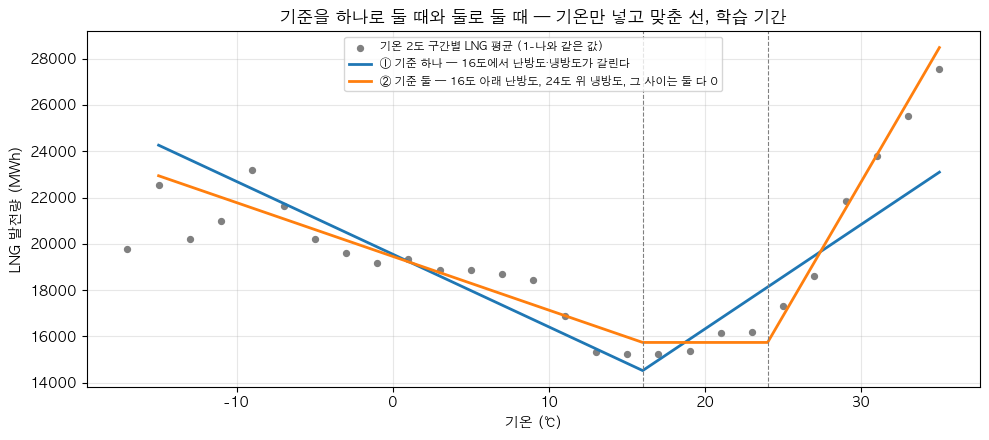

In [929]:
# 5단계 파생변수 · 1-바
from sklearn.linear_model import LinearRegression                          # 1-라·1-마와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량

def 두열(난방기준, 냉방기준, 기온):                                          # 기온으로 난방도·냉방도 두 열을 만든다
    return pd.DataFrame({"난방도": (난방기준 - 기온).clip(lower=0),          # 난방도 기준보다 추운 만큼
                         "냉방도": (기온 - 냉방기준).clip(lower=0)})         # 냉방도 기준보다 더운 만큼

격자 = pd.Series(np.arange(-15, 35.5, 0.5))                                 # 선을 그릴 기온 −15~35도, 0.5도 간격
선_하나 = LinearRegression().fit(두열(16, 16, train["ta"]), y).predict(두열(16, 16, 격자))   # ① 기준 하나(16도)
선_둘 = LinearRegression().fit(두열(16, 24, train["ta"]), y).predict(두열(16, 24, 격자))     # ② 기준 둘(16도·24도)
점 = train.assign(가운데=train["ta"] // 2 * 2 + 1).groupby("가운데")["lng_mwh"].mean()       # 2도 구간 평균을 구간 가운데에 찍는다

plt.figure(figsize=(10, 4.5))
plt.scatter(점.index, 점.values, color="gray", s=18, label="기온 2도 구간별 LNG 평균 (1-나와 같은 값)")
plt.plot(격자, 선_하나, lw=2, label="① 기준 하나 — 16도에서 난방도·냉방도가 갈린다")
plt.plot(격자, 선_둘, lw=2, label="② 기준 둘 — 16도 아래 난방도, 24도 위 냉방도, 그 사이는 둘 다 0")
for 선 in (16, 24):
    plt.axvline(선, ls="--", lw=.8, color="gray")                           # 16도와 24도에 세로선
plt.xlabel("기온 (℃)"); plt.ylabel("LNG 발전량 (MWh)")
plt.title("기준을 하나로 둘 때와 둘로 둘 때 — 기온만 넣고 맞춘 선, 학습 기간")
plt.legend(fontsize=8, loc="upper center"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 1-사

**무엇을 보는 셀인가.** 기온을 몇 구간으로 나누느냐에 따라 R²가 얼마나 달라지는지 봅니다. 구간은 「기온을 나누는 온도」로 정합니다. 두 가지를 기온별로 나란히 놓으면 이렇습니다.

| 기온 | 16·24도로 나눔 (3구간) | 10·16·24도로 나눔 (4구간) |
|---|---|---|
| 30도 | 24도 위 — 냉방 쪽 기울기 | 24도 위 — 냉방 쪽 기울기 |
| 20도 | 16~24도 — 기온이 LNG를 올리지 않음 | 16~24도 — 기온이 LNG를 올리지 않음 |
| 13도 | 16도 아래 — 난방 쪽 기울기 하나 | 10~16도 — 난방 쪽 기울기 ① |
| 0도 | 16도 아래 — 같은 난방 쪽 기울기 | 10도 아래 — 난방 쪽 기울기 ② |

- 3구간은 16도 아래를 기울기 하나로 봅니다. 4구간은 16도 아래를 10도에서 한 번 더 나눠서, 10~16도와 10도 아래에 기울기를 따로 줍니다. 1-바 칸에 적으신 「16~10, 10~-5」가 이런 모양입니다.
- 표의 첫 줄은 3구간(16·24도)입니다. 그 아래로 추운 쪽을 한 번 더 나눈 4구간(나누는 온도를 영하 6도부터 14도까지 2도씩), 10도와 영하 5도를 둘 다 둔 5구간, 더운 쪽을 26·28·30도에서 한 번 더 나눈 4구간이 이어집니다. 더운 쪽 세 줄은 1-다 「읽고 나서」에 적으신 「26도가 넘으면… 더 세밀하게 나눌 수도」를 같이 본 것입니다.
- R² 칸은 1-마처럼 둘입니다 — 기온만 넣었을 때와 시간대·월을 같이 넣었을 때입니다.

**읽는 법.** 첫 줄(3구간)의 오른쪽 R²와 아래 줄들의 오른쪽 R²를 비교합니다. 구간을 늘리면 R²는 줄지 않고 늘기만 하니, 늘었느냐가 아니라 **얼마나 늘었느냐**를 봅니다. 1-마 답변에서 0.002 안쪽은 우연으로도 생길 수 있는 차이라고 적었습니다. 판단은 오른쪽 칸(시간대·월 고정)으로 합니다. 첫 줄 오른쪽 칸은 1-마의 「냉방도 기준 24도」 줄과 같은 값이어야 맞습니다.

In [930]:
# 5단계 파생변수 · 1-사
from sklearn.linear_model import LinearRegression                          # 1-라~1-바와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 기온열(추운쪽, 더운쪽):                                                  # 나누는 온도로 기온 열을 만든다
    열 = pd.DataFrame(index=train.index)
    for 온도 in 추운쪽:                                                     # 추운 쪽 — 나누는 온도마다 「그보다 추운 만큼」 한 열
        열[f"{온도}도보다 추운 만큼"] = (온도 - train["ta"]).clip(lower=0)
    for 온도 in 더운쪽:                                                     # 더운 쪽 — 나누는 온도마다 「그보다 더운 만큼」 한 열
        열[f"{온도}도보다 더운 만큼"] = (train["ta"] - 온도).clip(lower=0)
    return 열

def 두R2(열):                                                              # 기온만 넣을 때와 시간대·월을 같이 넣을 때의 R²
    같이 = pd.concat([고정열, 열], axis=1)
    return (round(LinearRegression().fit(열, y).score(열, y), 3),
            round(LinearRegression().fit(같이, y).score(같이, y), 3))

후보 = [([16], [24], "–")]                                                  # 3구간 — 16도와 24도로 나눈다
후보 += [([16, k], [24], "추운 쪽") for k in range(-6, 15, 2)]              # 추운 쪽을 k도에서 한 번 더 나눈다 — 4구간
후보 += [([16, 10, -5], [24], "추운 쪽 두 번")]                              # 1-바 칸에 적으신 10도와 영하 5도 — 5구간
후보 += [([16], [24, k], "더운 쪽") for k in (26, 28, 30)]                  # 더운 쪽을 k도에서 한 번 더 나눈다 — 4구간

표 = []                                                                    # 나누는 방법마다 한 줄씩
for 추운쪽, 더운쪽, 쪽 in 후보:
    r1, r2 = 두R2(기온열(추운쪽, 더운쪽))
    온도들 = sorted(추운쪽 + 더운쪽)                                          # 나누는 온도를 작은 것부터 적는다
    표.append({"기온을 나누는 온도": "·".join(str(t) for t in 온도들) + "도",
               "구간 수": len(온도들) + 1, "더 나눈 쪽": 쪽,
               "R² 기온만": r1, "R² 시간대·월 고정": r2})

print("기온을 몇 구간으로 나누면 R²가 얼마나 느나 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("기온을 나누는 온도"))

기온을 몇 구간으로 나누면 R²가 얼마나 느나 — 학습 기간(2023+2024)만


,구간 수,더 나눈 쪽,R² 기온만,R² 시간대·월 고정
기온을 나누는 온도,,,,
16·24도,3,–,0.173,0.501
-6·16·24도,4,추운 쪽,0.174,0.502
-4·16·24도,4,추운 쪽,0.174,0.502
-2·16·24도,4,추운 쪽,0.174,0.501
0·16·24도,4,추운 쪽,0.174,0.501
2·16·24도,4,추운 쪽,0.174,0.501
4·16·24도,4,추운 쪽,0.175,0.501
6·16·24도,4,추운 쪽,0.175,0.502
8·16·24도,4,추운 쪽,0.175,0.502


## 1-아

**무엇을 보는 셀인가.** 두 가지를 한 표에 놓습니다.

- 난방 쪽 나누는 온도를 10도부터 20도까지 2도씩 바꿉니다. 냉방 쪽은 24도 그대로입니다. 1-마가 냉방 쪽 온도를 바꿔 본 것을 이번에는 난방 쪽으로 한 것입니다. 「난방 12도」 줄이 적으신 물음입니다.
- 마지막 줄은 16·24도로 나누되 선을 끊은 것입니다. 이어진 선과 끊긴 선은 이렇게 다릅니다.

| | 이어진 선 | 끊긴 선 |
|---|---|---|
| 구간마다 따로 주는 것 | 기울기 | 기울기와 시작 높이 |
| 15.9도와 16.1도의 예측 | 거의 같다 | 한 번에 크게 달라질 수 있다 |
| 기온 열 수 | 2 (난방도·냉방도) | 4 (난방도·냉방도 + 「16도보다 추운가」·「24도보다 더운가」 0/1 열) |

**읽는 법.** 오른쪽 칸(시간대·월 고정)으로 봅니다. 「난방 16도 · 냉방 24도, 이어진 선」 줄이 지금 제안이고, 1-사 첫 줄과 같은 값이어야 맞습니다. 다른 줄이 이 줄보다 0.002 넘게 크면 그쪽이 낫고, 0.002 안쪽이면 같은 것으로 봅니다. 열 수가 늘었는데 R²가 같다면 열이 적은 쪽을 고릅니다(1-마 답변의 효율성).

In [931]:
# 5단계 파생변수 · 1-아
from sklearn.linear_model import LinearRegression                          # 1-라~1-사와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 두R2(열):                                                              # 기온만 넣을 때와 시간대·월을 같이 넣을 때의 R²
    같이 = pd.concat([고정열, 열], axis=1)
    return (round(LinearRegression().fit(열, y).score(열, y), 3),
            round(LinearRegression().fit(같이, y).score(같이, y), 3))

표 = []                                                                    # 방법마다 한 줄씩
for 난방 in range(10, 21, 2):                                              # 난방 쪽 나누는 온도 10~20도(냉방 쪽은 24도)
    열 = pd.DataFrame({"난방도": (난방 - train["ta"]).clip(lower=0),          # 난방 온도보다 추운 만큼
                       "냉방도": (train["ta"] - 24).clip(lower=0)})           # 24도보다 더운 만큼
    r1, r2 = 두R2(열)
    표.append({"기온 열을 만드는 방법": f"난방 {난방}도 · 냉방 24도, 이어진 선",
               "기온 열 수": 2, "R² 기온만": r1, "R² 시간대·월 고정": r2})

끊긴 = pd.DataFrame({"난방도": (16 - train["ta"]).clip(lower=0),             # 이어진 선과 같은 두 열에
                     "냉방도": (train["ta"] - 24).clip(lower=0),
                     "16도보다 추운가": (train["ta"] < 16).astype(float),     # 구간마다 시작 높이를 따로 주는 0/1 열 둘을 더한다
                     "24도보다 더운가": (train["ta"] > 24).astype(float)})
r1, r2 = 두R2(끊긴)
표.append({"기온 열을 만드는 방법": "난방 16도 · 냉방 24도, 끊긴 선",
           "기온 열 수": 4, "R² 기온만": r1, "R² 시간대·월 고정": r2})

print("난방 쪽 나누는 온도를 바꿀 때, 그리고 선을 끊을 때 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("기온 열을 만드는 방법"))

난방 쪽 나누는 온도를 바꿀 때, 그리고 선을 끊을 때 — 학습 기간(2023+2024)만


,기온 열 수,R² 기온만,R² 시간대·월 고정
기온 열을 만드는 방법,,,
"난방 10도 · 냉방 24도, 이어진 선",2,0.162,0.493
"난방 12도 · 냉방 24도, 이어진 선",2,0.169,0.496
"난방 14도 · 냉방 24도, 이어진 선",2,0.173,0.499
"난방 16도 · 냉방 24도, 이어진 선",2,0.173,0.501
"난방 18도 · 냉방 24도, 이어진 선",2,0.171,0.502
"난방 20도 · 냉방 24도, 이어진 선",2,0.168,0.502
"난방 16도 · 냉방 24도, 끊긴 선",4,0.174,0.502


## 1-자

**무엇을 보는 셀인가.** 나누는 온도는 두 가지(16·24도 / 10·16·24도)이고, 각각 16~24도를 평평하게 두느냐 따로 기울기를 주느냐로 나눠서 네 줄을 봅니다.

| 나누는 온도 | 16~24도 평평 | 16~24도에 따로 기울기 |
|---|---|---|
| 16·24도 | ① 지금 제안 (기온 열 2) | ③ (기온 열 3) |
| 10·16·24도 | ② 1-사에서 본 것 (기온 열 3) | ④ 창주 님 4등분 (기온 열 4) |

- ①·②는 앞에서 이미 본 것이고, 새로 보는 것은 ③·④입니다.
- ④가 적으신 4등분입니다. 16도로 좌우를 가르고, 추운 쪽은 1-바 칸에 적으신 10도에서, 더운 쪽은 24도에서 한 번 더 나눕니다. 네 구간(10도 아래 · 10~16도 · 16~24도 · 24도 위)이 모두 기울기를 따로 가집니다.
- 표를 옆으로 보면(①과 ③, ②와 ④) 16~24도에 따로 기울기를 준 만큼이, 아래로 보면(①과 ②, ③과 ④) 10도에서 한 번 더 나눈 만큼이 보입니다.
- 네 가지 모두 선은 이어져 있습니다(1-아의 이어진 선).
- **⑤는 09-24에 더한 줄입니다.** 1-자 아래 칸에 적으신 「24도 이상, 12~24도, 12~10정도, 그리고 그 아래」를 옮긴 것으로, 나누는 온도가 10·12·24도이고 네 구간 모두 기울기가 따로 있습니다. 가운데 구간이 12~24도라서 2×2 표에는 들어가지 않습니다.
- **⑥도 09-24에 더한 줄입니다.** 그래프에서 보이는 점을 이어 9·12·24도로 나눈 것이고, 네 구간 모두 기울기가 따로 있습니다(1-자 아래 「읽고 나서」).
- 열로 보면 ②·③·④는 모두 ①(「16도보다 추운 만큼」 = 난방도, 「24도보다 더운 만큼」 = 냉방도)에 열을 더한 것입니다. ②는 「10도보다 추운 만큼」을, ③은 「16도보다 더운 만큼」을, ④는 둘 다를 더합니다. 16~24도에서는 「16도보다 더운 만큼」만 0이 아니라서, 이 열이 있어야 그 구간에 기울기가 생깁니다.

**읽는 법.**

- 판단은 「R² 시간대·월 고정」 칸으로 합니다. ① 줄이 지금 제안이고, 1-사 첫 줄과 셋째 자리까지 같아야 맞습니다(0.501).
- 이번 표는 R²를 넷째 자리까지 적습니다. 줄 사이 차이가 작을 때 셋째 자리에서 반올림하면 차이가 실제보다 커 보이거나 작아 보일 수 있어서입니다. 1-마 답변에서 0.002 안쪽은 같은 것으로 보기로 했습니다.
- 「가운데 구간 기울기」 칸은 시간대·월을 고정했을 때 가운데 구간(①~④는 16~24도, ⑤·⑥은 12~24도)에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지입니다. +면 늘고 −면 준다는 뜻입니다. ①·②는 이 구간을 평평하게 묶어 두었으니 0입니다.
- 「24도 위 기울기」 칸은 비교용입니다. 24도 위에서 기온이 1도 오를 때의 변화입니다.

In [932]:
# 5단계 파생변수 · 1-자
from sklearn.linear_model import LinearRegression                          # 1-라~1-아와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 추운(온도): return (온도 - train["ta"]).clip(lower=0)                      # 그 온도보다 추운 만큼 — 그 온도 아래에서만 0보다 크다
def 더운(온도): return (train["ta"] - 온도).clip(lower=0)                      # 그 온도보다 더운 만큼 — 그 온도 위에서만 0보다 크다

후보 = [                                                                    # (표에 적을 이름, 기온 열, 가운데 구간에 기울기를 주는 열)
    ("① 16·24도 · 16~24도 평평 (지금 제안)",
     {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}, None),
    ("② 10·16·24도 · 16~24도 평평 (1-사에서 본 것)",
     {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}, None),
    ("③ 16·24도 · 16~24도에 따로 기울기",
     {"16도보다 추운 만큼": 추운(16), "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)}, "16도보다 더운 만큼"),
    ("④ 10·16·24도 · 16~24도에 따로 기울기 (4등분)",
     {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16),
      "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)}, "16도보다 더운 만큼"),
    ("⑤ 10·12·24도 · 12~24도에 따로 기울기 (1-자 칸에 적으신 것)",
     {"10도보다 추운 만큼": 추운(10), "12도보다 추운 만큼": 추운(12),
      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}, "12도보다 더운 만큼"),
    ("⑥ 9·12·24도 · 네 구간 모두 기울기 (그래프에서 보이는 대로)",
     {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}, "12도보다 더운 만큼"),
]

표 = []                                                                    # 나누는 방법마다 한 줄씩
for 이름, 열들, 가운데열 in 후보:
    열 = pd.DataFrame(열들)                                                  # 이 줄에서 쓸 기온 열을 모은다
    같이 = pd.concat([고정열, 열], axis=1)                                   # 시간대·월 열과 합친다
    모델1 = LinearRegression().fit(열, y)                                    # 기온 열만 넣은 모델
    모델2 = LinearRegression().fit(같이, y)                                  # 시간대·월을 같이 넣은 모델
    기울기 = dict(zip(같이.columns, 모델2.coef_))                              # 열 이름 → 그 열의 기울기(시간대·월 고정)
    if 가운데열:                                                             # 가운데 구간에 따로 기울기를 준 줄이면
        가운데 = f"{기울기[가운데열]:+,.0f}"                                    # 가운데 구간에서 기온이 1도 오를 때 LNG 변화(MWh)
    else:                                                                  # 가운데 구간을 평평하게 둔 줄이면
        가운데 = "0 (평평하게 둠)"                                            # 이 구간 기울기는 0으로 정해 둔 것
    위쪽 = 기울기["24도보다 더운 만큼"] + (기울기[가운데열] if 가운데열 else 0)  # 24도 위에서 1도 오를 때 LNG 변화 — 두 열의 기울기를 더한 것
    표.append({"기온을 나누는 방법": 이름, "기온 열 수": len(열들),
               "R² 기온만": round(모델1.score(열, y), 4),                     # 이번 표는 넷째 자리까지 적는다
               "R² 시간대·월 고정": round(모델2.score(같이, y), 4),
               "가운데 구간 기울기": 가운데,
               "24도 위 기울기": f"{위쪽:+,.0f}"})

print("가운데 구간에 따로 기울기를 주면 R²가 늘까 — 학습 기간(2023+2024)만")
print("가운데 구간은 ①~④가 16~24도, ⑤·⑥이 12~24도 · 기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지")
display(pd.DataFrame(표).set_index("기온을 나누는 방법"))

가운데 구간에 따로 기울기를 주면 R²가 늘까 — 학습 기간(2023+2024)만
가운데 구간은 ①~④가 16~24도, ⑤·⑥이 12~24도 · 기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지


,기온 열 수,R² 기온만,R² 시간대·월 고정,가운데 구간 기울기,24도 위 기울기
기온을 나누는 방법,,,,,
① 16·24도 · 16~24도 평평 (지금 제안),2,0.1734,0.5011,0 (평평하게 둠),+661
② 10·16·24도 · 16~24도 평평 (1-사에서 본 것),3,0.1745,0.5021,0 (평평하게 둠),+658
③ 16·24도 · 16~24도에 따로 기울기,3,0.1750,0.5021,-120,+683
④ 10·16·24도 · 16~24도에 따로 기울기 (4등분),4,0.1793,0.5026,-89,+675
⑤ 10·12·24도 · 12~24도에 따로 기울기 (1-자 칸에 적으신 것),4,0.1809,0.5019,-163,+695
⑥ 9·12·24도 · 네 구간 모두 기울기 (그래프에서 보이는 대로),4,0.1807,0.5018,-168,+696


# 물음 2 — 지난 기온(시간 지연)을 열로 넣을까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 물음 1을 마치며 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물었고, 그 가운데 시간 지연을 물음으로 보기로 했다(09-24). 건물이 식거나 데워지는 데 시간이 걸려 난방·냉방 수요가 기온을 늦게 따라갈 수 있어서, 지난 기온을 열로 넣으면 설명이 느는지 본 물음이다.

### 결정 — 3시간 전 기온(난방도·냉방도 두 열)을 7단계 후보로 넘긴다

**결정 근거** — 2-가 ③ 줄(① + 3시간 전 기온)에서 R²가 +0.0090 올랐다. 물음 1에서 같다고 본 폭(0.002)의 4배가 넘고, 2023년으로 배워 2024년을 맞혀도 +0.0095였다. 1·6·12시간 전, 지난 24시간 평균, 전날 평균은 +0.0013~+0.0083으로 그보다 작았다. 판단은 2-가 「✍️ 읽고 나서」 ②에 적었다(「응 너의 의견대로 넘길께」).

**남은 것** — 원전은 그 시각 값만 넣는다(정비로 선 호기까지 그 숫자에 이미 들어 있다). 2026년 원전 값이 학습 범위를 벗어나는지는 6단계에서 세고, 범위 밖 시각의 차이는 9단계에서 갈라 본다. 5단계 4-다에서 지금 난방도와 3시간 전 난방도의 VIF가 35.5·35.8로 10을 넘었다(상관 0.972). 둘을 어떻게 넣을지는 6단계에서 정한다(09-28). 2-가는 선형회귀로만 비교했다 — 트리 계열에 3시간 전 기온을 넣을지도 6단계에서 정한다(09-28, 4-라 「다시 읽고 나서」 답변).

→ **이어진 곳(10-05)** — 원전은 6단계 물음 1에서 입력에서 뺐다(10-03). 3시간 전 기온은 6단계 물음 4에서 정했다 — 선형회귀에는 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값) 두 열로 바꿔 넣어 VIF가 모두 10 아래가 됐고, 트리 계열에는 2024년 결정계수가 0.002 넘게 오르지 않아 넣지 않는다(4-라·4-마).

</div>

## 2-가

**무엇을 보는 셀인가.** 물음 1에서 정한 16·24도(①)에, 지난 기온으로 만든 난방도·냉방도를 더하면 R²가 느는지 봅니다.

| 줄 | 더하는 것 | 무엇을 보려는 것인가 |
|---|---|---|
| ① | 없음 (지금 기온만) | 비교 기준 |
| ②~⑤ | 1·3·6·12시간 전 기온 | 건물이 식거나 데워지는 데 몇 시간이 걸리는지 |
| ⑥ | 지난 24시간 평균 기온 | 하루 동안 쌓인 추위·더위 |
| ⑦ | 전날 하루 평균 기온 | 전날 날씨 |

- 지난 기온도 16·24도로 나눠 난방도·냉방도 두 열로 만듭니다. 그래서 ②~⑦은 기온 열이 넷입니다.
- 지난 기온이 없는 시각은 일곱 줄 모두에서 빼고 같은 시각으로 비교합니다. 2023년 1월 1일, 2024년 3월 1일, 2024년 9월 1일 하루씩입니다(72시각). 앞날이 데이터에 없는 날들입니다.
- 그래서 ①의 R²가 물음 1의 0.501과 조금 다릅니다. 이 표 안에서만 비교합니다.

**읽는 법.** 「R² 시간대·월 고정」 칸으로 봅니다. ①보다 0.002 넘게 높으면 지난 기온이 설명을 더한다고 봅니다(물음 1과 같은 기준).

In [933]:
# 5단계 파생변수 · 2-가
from sklearn.linear_model import LinearRegression                          # 물음 1과 같은 선형회귀
기온 = tbl.set_index("ts")["ta"].sort_index()                               # 세 해 전체 기온을 시각 순서로 — 지난 기온은 해를 넘어가도 이어져야 한다
지연 = pd.DataFrame(index=기온.index)                                        # 지난 기온으로 만든 열을 모은다
for 시간 in (1, 3, 6, 12):                                                  # 1·3·6·12시간 전 기온
    지연[f"{시간}시간 전"] = 기온.shift(freq=f"{시간}h").reindex(기온.index)   # 그 시각이 빠졌으면 빈칸
지연["지난 24시간 평균"] = 기온.rolling("24h", min_periods=24).mean()          # 지금까지 24시간 평균 — 24시각이 다 있을 때만
하루 = 기온.groupby(기온.index.date).agg(["mean", "size"])                   # 날짜별 평균 기온과 시각 수
하루평균 = 하루.loc[하루["size"] == 24, "mean"]                               # 24시각이 다 있는 날만 쓴다
전날 = pd.Series((기온.index.normalize() - pd.Timedelta(days=1)).date, index=기온.index)  # 각 시각의 전날 날짜
지연["전날 하루 평균"] = 전날.map(하루평균)                                     # 전날 하루 평균 기온 — 전날이 빠졌으면 빈칸

학습 = train.set_index("ts").join(지연).dropna(subset=list(지연.columns))    # 학습 기간에 붙이고, 지난 기온이 빈 시각은 뺀다
y = 학습["lng_mwh"]                                                         # 맞힐 값
고정열 = pd.get_dummies(학습[["hour24", "month"]].astype(str),               # 물음 1과 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
지금 = 난냉(학습["ta"], "지금")                                               # 물음 1에서 정한 16·24도

후보 = [("① 지금 기온만 (물음 1의 16·24도)", None),                         # (표에 적을 이름, 더할 지난 기온 열)
        ("② ① + 1시간 전 기온", "1시간 전"), ("③ ① + 3시간 전 기온", "3시간 전"),
        ("④ ① + 6시간 전 기온", "6시간 전"), ("⑤ ① + 12시간 전 기온", "12시간 전"),
        ("⑥ ① + 지난 24시간 평균 기온", "지난 24시간 평균"), ("⑦ ① + 전날 하루 평균 기온", "전날 하루 평균")]

표 = []                                                                    # 줄마다 R²를 적는다
for 이름, 지난 in 후보:
    열 = 지금 if 지난 is None else pd.concat([지금, 난냉(학습[지난], 지난)], axis=1)  # ①에 지난 기온의 난방도·냉방도를 더한다
    같이 = pd.concat([고정열, 열], axis=1)                                   # 시간대·월 열과 합친다
    r2 = LinearRegression().fit(같이, y).score(같이, y)                      # 시간대·월을 고정했을 때의 R²
    표.append({"넣는 것": 이름, "기온 열 수": 열.shape[1], "R² 시간대·월 고정": round(r2, 4)})
표 = pd.DataFrame(표).set_index("넣는 것")
표["①과 차이"] = (표["R² 시간대·월 고정"] - 표["R² 시간대·월 고정"].iloc[0]).round(4)  # ①보다 얼마나 늘었나

print("지난 기온을 더하면 R²가 늘까 — 학습 기간(2023+2024)만")
print("비교에 쓴 시각", len(학습), "/ 학습 기간", len(train), "— 지난 기온이 없는 시각은 일곱 줄 모두에서 뺐다")
display(표)

지난 기온을 더하면 R²가 늘까 — 학습 기간(2023+2024)만
비교에 쓴 시각 16704 / 학습 기간 16776 — 지난 기온이 없는 시각은 일곱 줄 모두에서 뺐다


,기온 열 수,R² 시간대·월 고정,①과 차이
넣는 것,,,
① 지금 기온만 (물음 1의 16·24도),2,0.5058,0.0000
② ① + 1시간 전 기온,4,0.5117,0.0059
③ ① + 3시간 전 기온,4,0.5148,0.0090
④ ① + 6시간 전 기온,4,0.5141,0.0083
⑤ ① + 12시간 전 기온,4,0.5100,0.0042
⑥ ① + 지난 24시간 평균 기온,4,0.5084,0.0026
⑦ ① + 전날 하루 평균 기온,4,0.5071,0.0013


# 물음 3 — 태양광 열을 어떤 모양으로 만들까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 4단계를 닫으며 넘어온 물음이다. 태양광 발전량은 2023~2025년에만 시간별로 있고, 2026년은 API가 「신재생·기타」로 묶어 주며 설비용량 칸도 없다. 9단계에서 2026년을 예측하려면 2026년에도 있는 모양이어야 해서, 태양광을 어떤 열로 넘길지 정한 물음이다.

### 결정 — 태양광 대신 일사 한 열(`icsr`)을 7단계 후보로 넘긴다. 태양광을 따로 예측해 넣지 않는다

**같이 정한 것**

1. 지난 시각 일사(1·3시간 전)는 넣지 않는다. 3-가 ⑤·⑥ 줄에서 일사만 넣은 ④보다 R²가 ⑤ +0.0000, ⑥ +0.0003이었다. 지난 시각 값을 넣는 것은 기온이다(물음 2의 3시간 전 기온). 판단은 3-다 「✍️ 읽고 나서」에 적었다(「일사의 태양광일 경우 이게 무의미하다는건 앞에서 배운 것으로 이해하고 있는데」).

2. 넣는 것은 일조(`ss`, 그 한 시간 가운데 해가 직접 비친 시간)가 아니라 일사(`icsr`, 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지)다. 3-라에서 일조 0인 시각에도 일사가 0.56이었고, 일조가 모두 1.0인 시각끼리도 일사가 0.36~3.43으로 달랐다. 판단은 3-라 「✍️ 읽고 나서」에 적었다(「어쨌든 일조시간 0이라도 일사가 나오니까. 그리고 그 일사가 실제로 데이터 발전량과 관련되니까」).

3. 일사는 한 열로 넣고, 일사 크기·시간대·달마다 나눠 넣지 않는다. 3-마에서 달마다 따로가 2024년 R² +0.0025(평균 절대 오차 19 MWh, 0.75%)로 가장 나았지만, 3-바에서 2024년 11달 가운데 8달에서만 나아졌고(부호검정 p 0.113) 8월 기울기는 2023년 한 해로만 정해진다. 시간대마다 따로는 2024년 +0.0013으로 0.002 안쪽이고, 일사 크기에 따라는 F검정 p 0.1525로 기울기가 바뀌지 않았다. 달마다 차이 자체는 두 해 모두 봄에 크게 나와 실제로 있는 것 같다(3-마 답변 4). 판단은 09-29 채팅에 적으셨다(「최종적인 결론에 이르는 논리만 타당하면 너가 정해준 방향으로 가자」, 3-바 「✍️ 읽고 나서」 ①에 옮김) — 클로드 제안(한 열 그대로)을 받아들였다. 3-마는 물음 6(표준화)의 6-가를 보다가 나온 창주 님 아이디어다.

**결정 근거** — 3-가에서 태양광 열을 넣으면 R²가 +0.042~+0.049 올랐고, 일사(④ 0.5583)가 태양광 발전량(② 0.5517)보다 컸다. 3-나에서 2023년으로 배워 2024년을 맞혀도 ④가 가장 나았다(R² ④ 0.4791 · ③ 0.4606 · ② 0.4411, 낮 10~15시 평균 오차 ④ +728 · ③ +1,443 · ② +1,591 MWh). 태양광을 먼저 예측해 넣은 줄(3-나 ⑤)은 ④와 숫자가 똑같았다. 3-다에서 일사를 넣자 물음 1의 음수 기울기가 사라졌다(16~24도 −120 → +103). 일사를 빼면 햇빛의 효과가 기온 열의 기울기에 섞인다는 뜻이다. 판단은 3-다 「✍️ 읽고 나서」에 적었다(「그러면 최종적으로 여기에서 내릴 수 있는 결론은 일사량 컬럼이 반드시 추가되어야 한다」).

**남은 것** — 설비가 더 큰 2025년에도 ④가 통하는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 2025년 낮 오차를 2024년 검증 때 숫자(+728) 옆에 놓고 본다. 그 전에 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 2025·2026년 일사가 2023·2024년 범위 안인지 세고, ④를 계속 쓸지 판단 기준을 7단계 결과를 보기 전에 적는다. 역산(「신재생·기타」에서 밤 값을 빼 태양광을 뽑고, 일사로 나눠 설비 증가를 보는 방법)은 모델 입력이 아니다. 9단계(2026년 예측과 실제를 비교하는 단계)에서 낮 차이 가운데 태양광 설비가 늘어서 생긴 부분을 가를 때 쓰고, ④가 7단계에서 크게 틀려 ②·③으로 바꿀 때도 쓴다. 일사를 한 열로 넣었으므로, 7단계에서 달마다 잔차를 볼 때 봄(3~5월)에 햇빛이 많은 시각을 한쪽으로 틀리는지 본다(3-마에서 봄의 일사 기울기가 한 열보다 컸다, 3-마 답변 2·4).

→ **이어진 곳(10-05)** — 6단계 물음 3에서 셌다. 2025년은 30시각, 2026년 1~6월은 1시각만 배운 범위 밖이었고, 2024년에는 일사 한 열이 늘어난 패널을 못 따라간다는 흔적이 없어 그대로 간다. 7단계에서 볼 기준도 결과를 보기 전에 적었다 — 2025년에 날마다 「낮 − 밤」 잔차의 95% 구간 위 끝이 0보다 아래면 달마다 나눠 보고, 여러 달에 고르게 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험한다(6단계 물음 3 결론 칸).

</div>

## 3-가

**무엇을 보는 셀인가.** 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월을 넣은 것(①)에 태양광 열을 하나씩 더합니다.

| 줄 | 더하는 것 | 2026년에도 있나 |
|---|---|---|
| ① | 없음 | — |
| ② | 태양광 발전량 (전력거래소) | 없음 — API가 「신재생·기타」로 묶어서 준다 |
| ③ | 설비용량 × 일사 | 없음 — 2026년 설비용량은 API에 칸이 없다 |
| ④ | 일사 (기상청 서울 108) | 있음 — 2026년 1~8월을 받아 두었다 |
| ⑤ | ④ + 1시간 전 일사 | 있음 |
| ⑥ | ④ + 3시간 전 일사 | 있음 |

- ⑤·⑥은 물음 2 「읽고 나서」에 물으신 「원전이나 태양광도 지난 시각 값을 넣어야 하나」를 보는 줄입니다.
- 지난 값이 없는 시각(세 날의 첫 3시간씩, 9시각)은 여섯 줄 모두에서 빼고 비교합니다. 그래서 ①의 R²가 2-가와 조금 다릅니다.

**읽는 법.** 「①과 차이」가 클수록 태양광 열이 설명을 더한 것입니다. 「2026년에도 있나」가 「없음」인 모양은 9단계에서 2026년을 예측할 때 쓸 수 없습니다.

In [934]:
# 5단계 파생변수 · 3-가
from sklearn.linear_model import LinearRegression                          # 물음 1·2와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 지난 시각 값을 만들려고
지난 = pd.DataFrame(index=시각순.index)                                      # 지난 시각 값을 모은다
지난["3시간 전 기온"] = 시각순["ta"].shift(freq="3h").reindex(시각순.index)    # 물음 2에서 넘기기로 한 열
지난["1시간 전 일사"] = 시각순["icsr"].shift(freq="1h").reindex(시각순.index)  # ⑤에 쓴다
지난["3시간 전 일사"] = 시각순["icsr"].shift(freq="3h").reindex(시각순.index)  # ⑥에 쓴다

학습3 = train.set_index("ts").join(지난).dropna(subset=list(지난.columns))   # 학습 기간에 붙이고, 지난 값이 빈 시각은 여섯 줄 모두에서 뺀다
학습3["설비용량×일사"] = 학습3["solar_cap_mw"] * 학습3["icsr"]               # ③에 쓴다 — 설비가 클수록, 햇빛이 셀수록 커진다
y = 학습3["lng_mwh"]                                                        # 맞힐 값
고정열 = pd.get_dummies(학습3[["hour24", "month"]].astype(str),              # 물음 1·2와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
기온열 = pd.concat([난냉(학습3["ta"], "지금"), 난냉(학습3["3시간 전 기온"], "3시간 전")], axis=1)  # 물음 1·2에서 정한 기온 열

후보 = [("① 태양광 없음", [], "—"),                                          # (표에 적을 이름, 더할 열, 2026년에도 있나)
        ("② + 태양광 발전량", ["solar_mwh"], "없음"),
        ("③ + 설비용량 × 일사", ["설비용량×일사"], "없음"),
        ("④ + 일사", ["icsr"], "있음"),
        ("⑤ + 일사 + 1시간 전 일사", ["icsr", "1시간 전 일사"], "있음"),
        ("⑥ + 일사 + 3시간 전 일사", ["icsr", "3시간 전 일사"], "있음")]

표 = []                                                                    # 줄마다 R²를 적는다
for 이름, 열이름, 있나 in 후보:
    같이 = pd.concat([고정열, 기온열, 학습3[열이름]], axis=1)                 # 시간대·월 + 기온 열 + 태양광 열
    r2 = LinearRegression().fit(같이, y).score(같이, y)                      # 시간대·월을 고정했을 때의 R²
    표.append({"더하는 것": 이름, "2026년에도 있나": 있나, "R² 시간대·월 고정": round(r2, 4)})
표 = pd.DataFrame(표).set_index("더하는 것")
표["①과 차이"] = (표["R² 시간대·월 고정"] - 표["R² 시간대·월 고정"].iloc[0]).round(4)  # ①보다 얼마나 늘었나

print("태양광을 어떤 모양으로 넣으면 설명이 느나 — 학습 기간(2023+2024)만")
print("①은 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월 · 비교에 쓴 시각", len(학습3))
display(표)

태양광을 어떤 모양으로 넣으면 설명이 느나 — 학습 기간(2023+2024)만
①은 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월 · 비교에 쓴 시각 16767


,2026년에도 있나,R² 시간대·월 고정,①과 차이
더하는 것,,,
① 태양광 없음,—,0.5097,0.0000
② + 태양광 발전량,없음,0.5517,0.0420
③ + 설비용량 × 일사,없음,0.5534,0.0437
④ + 일사,있음,0.5583,0.0486
⑤ + 일사 + 1시간 전 일사,있음,0.5583,0.0486
⑥ + 일사 + 3시간 전 일사,있음,0.5586,0.0489


## 3-나

**무엇을 보는 셀인가.** 2023년으로만 배우고, 배우지 않은 2024년을 맞혀 봅니다. 태양광 설비가 2023년보다 2024년에 더 크므로, 설비가 늘어난 것을 아는 열과 모르는 열이 2024년에 어떻게 다르게 틀리는지 볼 수 있습니다.

| 줄 | 더하는 것 | 설비가 늘어난 것을 아나 | 2026년에도 있나 |
|---|---|---|---|
| ① | 없음 | — | — |
| ② | 태양광 발전량 | 안다 — 발전량에 들어 있다 | 없음 |
| ③ | 설비용량 × 일사 | 안다 | 2026년 설비용량을 추세로 늘려 써야 한다 |
| ④ | 일사 | 모른다 | 있음 |
| ⑤ | 일사로 먼저 예측한 태양광 — 4단계에서 정한 방향 ⓒ | 모른다 — 2023년 설비로 배운 예측이다 | 있음 |
| ⑥ | 일사 + 3시간 전 일사 | 모른다 | 있음 |

- ⑤는 2023년 태양광 발전량을 일사·시간대·월로 먼저 배우고(태양광 모델), 그 예측값을 ④의 일사 대신 LNG 모델에 넣습니다.
- 기온 열(16·24도 + 3시간 전 기온)과 시간대·월은 3-가와 같습니다. 3-가는 두 해를 모두 배운 R²였고 여기는 배우지 않은 해의 R²라서, 숫자가 3-가보다 낮게 나오는 것이 보통입니다.

**읽는 법.** 「R² 2024년」과 「①과 차이」는 배우지 않은 해를 얼마나 맞히는지입니다. 「낮 10~15시 평균 오차」는 2024년 낮 시각마다 「실제 − 예측」을 구해 평균한 것입니다. 0에 가까울수록 한쪽으로 쏠리지 않은 것이고, 양수면 낮 LNG를 적게, 음수면 많게 예측한 것입니다.

In [935]:
# 5단계 파생변수 · 3-나
from sklearn.linear_model import LinearRegression                          # 3-가와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 지난 시각 값을 만들려고
지난 = pd.DataFrame(index=시각순.index)                                      # 지난 시각 값을 모은다
지난["3시간 전 기온"] = 시각순["ta"].shift(freq="3h").reindex(시각순.index)    # 물음 2에서 넘기기로 한 열
지난["3시간 전 일사"] = 시각순["icsr"].shift(freq="3h").reindex(시각순.index)  # ⑥에 쓴다
자료 = train.set_index("ts").join(지난).dropna(subset=list(지난.columns))     # 2023+2024에 붙이고, 지난 값이 빈 시각은 뺀다
자료["설비용량×일사"] = 자료["solar_cap_mw"] * 자료["icsr"]                 # ③에 쓴다 — 설비가 클수록, 햇빛이 셀수록 커진다

배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 두 해를 같이 만들어 열 이름을 맞춘다
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
기온열 = pd.concat([난냉(자료["ta"], "지금"), 난냉(자료["3시간 전 기온"], "3시간 전")], axis=1)  # 물음 1·2에서 정한 기온 열

태양광입력 = pd.concat([고정열, 자료[["icsr"]]], axis=1)                     # ⑤의 태양광 모델에 넣는 것 — 일사·시간대·월
태양광모델 = LinearRegression().fit(태양광입력[배움], 자료.loc[배움, "solar_mwh"])  # 2023년 태양광 발전량을 일사·시간대·월로 배운다
자료["일사로 예측한 태양광"] = 태양광모델.predict(태양광입력)                    # 2023년은 배운 값, 2024년은 예측값 — ⑤에 쓴다

후보 = [("① 태양광 없음", [], "—"),                                          # (표에 적을 이름, 더할 열, 2026년에도 있나)
        ("② + 태양광 발전량", ["solar_mwh"], "없음"),
        ("③ + 설비용량 × 일사", ["설비용량×일사"], "설비용량을 늘려 써야"),
        ("④ + 일사", ["icsr"], "있음"),
        ("⑤ + 일사로 예측한 태양광", ["일사로 예측한 태양광"], "있음"),
        ("⑥ + 일사 + 3시간 전 일사", ["icsr", "3시간 전 일사"], "있음")]

y = 자료["lng_mwh"]                                                          # 맞힐 값
낮 = 맞힘 & 자료["hour24"].between(10, 15)                                    # 2024년 낮 10~15시
표 = []                                                                     # 줄마다 2024년 성적을 적는다
for 이름, 열이름, 있나 in 후보:
    X = pd.concat([고정열, 기온열, 자료[열이름]], axis=1)                       # 시간대·월 + 기온 열 + 태양광 열
    모델 = LinearRegression().fit(X[배움], y[배움])                           # 2023년으로만 배운다
    예측 = pd.Series(모델.predict(X), index=X.index)                          # 두 해 모두 예측한다
    표.append({"더하는 것": 이름, "2026년에도 있나": 있나,
               "R² 2024년": round(모델.score(X[맞힘], y[맞힘]), 4),          # 배우지 않은 2024년을 얼마나 맞히나
               "낮 10~15시 평균 오차": round((y[낮] - 예측[낮]).mean())})    # 2024년 낮 「실제 − 예측」의 평균(MWh)
표 = pd.DataFrame(표).set_index("더하는 것")
표.insert(2, "①과 차이", (표["R² 2024년"] - 표["R² 2024년"].iloc[0]).round(4))  # ①보다 얼마나 나은가

print("2023년으로 배워 2024년을 맞혀 보면 — 태양광 열의 모양별")
print("배운 시각", int(배움.sum()), "· 맞힌 시각", int(맞힘.sum()))
print("낮 평균 오차는 「실제 − 예측」(MWh) — 양수면 낮 LNG를 적게, 음수면 많게 예측한 것")
display(표)

2023년으로 배워 2024년을 맞혀 보면 — 태양광 열의 모양별
배운 시각 8757 · 맞힌 시각 8010
낮 평균 오차는 「실제 − 예측」(MWh) — 양수면 낮 LNG를 적게, 음수면 많게 예측한 것


,2026년에도 있나,R² 2024년,①과 차이,낮 10~15시 평균 오차
더하는 것,,,,
① 태양광 없음,—,0.4360,0.0000,704
② + 태양광 발전량,없음,0.4411,0.0051,1591
③ + 설비용량 × 일사,설비용량을 늘려 써야,0.4606,0.0246,1443
④ + 일사,있음,0.4791,0.0431,728
⑤ + 일사로 예측한 태양광,있음,0.4791,0.0431,728
⑥ + 일사 + 3시간 전 일사,있음,0.4795,0.0435,728


## 3-다

**무엇을 보는 셀인가.** 1-자와 같은 모델(시간대·월 고정, 기온 열만)에 일사 한 열을 더했을 때 가운데 구간 기울기와 R²가 어떻게 바뀌는지 봅니다. 물음 1에서 넘긴 두 방법(16·24도 평평, 9·12·24도)과, 가운데 구간에 기울기를 따로 준 1-자 ③을 같이 놓습니다.

**읽는 법.** 「일사 없음」 줄은 1-자와 같은 숫자입니다. 일사를 넣은 뒤 가운데 구간 기울기가 0에 가까워지거나 부호가 바뀌면, 그 음수는 기온 때문이 아니라 햇빛 때문이었다는 뜻입니다. 「R² 시간대·월 고정」은 방법끼리 0.002 안쪽이면 같은 것으로 봅니다.

In [936]:
# 5단계 파생변수 · 3-다
from sklearn.linear_model import LinearRegression                          # 1-자와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-자와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 추운(온도): return (온도 - train["ta"]).clip(lower=0)                      # 그 온도보다 추운 만큼
def 더운(온도): return (train["ta"] - 온도).clip(lower=0)                      # 그 온도보다 더운 만큼

방법 = [("16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)",                        # (표에 적을 이름, 기온 열, 가운데 구간 기울기 열)
         {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},
         None),
        ("16·24도 · 16~24도에 따로 기울기 (1-자 ③)",
         {"16도보다 추운 만큼": 추운(16), "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)},
         "16도보다 더운 만큼"),
        ("9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것)",
         {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
          "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)},
         "12도보다 더운 만큼")]

표 = []                                                                     # 방법마다 일사를 뺀 줄과 넣은 줄
for 이름, 열들, 가운데열 in 방법:
    for 일사 in ("없음 (1-자와 같다)", "넣음"):
        더할 = [train[["icsr"]]] if 일사 == "넣음" else []                    # 일사를 넣는 줄이면 일사 열을 더한다
        X = pd.concat([고정열, pd.DataFrame(열들)] + 더할, axis=1)             # 시간대·월 + 기온 열 (+ 일사)
        모델 = LinearRegression().fit(X, y)                                  # 학습 기간 전체로 배운다
        기울기 = dict(zip(X.columns, 모델.coef_))                              # 열 이름 → 그 열의 기울기
        표.append({"기온을 나누는 방법": 이름, "일사": 일사,
                   "가운데 구간 기울기": f"{기울기[가운데열]:+,.0f}" if 가운데열 else "0 (평평하게 둠)",  # 가운데 구간에서 기온이 1도 오를 때 LNG 변화(MWh)
                   "R² 시간대·월 고정": round(모델.score(X, y), 4)})

print("가운데 구간의 음수 기울기가 태양광 때문이었나 — 학습 기간(2023+2024)만")
print("가운데 구간은 위 두 방법이 16~24도, 셋째가 12~24도")
print("기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지")
display(pd.DataFrame(표).set_index(["기온을 나누는 방법", "일사"]))

가운데 구간의 음수 기울기가 태양광 때문이었나 — 학습 기간(2023+2024)만
가운데 구간은 위 두 방법이 16~24도, 셋째가 12~24도
기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지


가운데 구간 기울기  \
기온을 나누는 방법                                  일사                         
16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)            없음 (1-자와 같다)  0 (평평하게 둠)   
                                            넣음            0 (평평하게 둠)   
16·24도 · 16~24도에 따로 기울기 (1-자 ③)             없음 (1-자와 같다)        -120   
                                            넣음                  +103   
9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것) 없음 (1-자와 같다)        -168   
                                            넣음                   -13   

                                                          R² 시간대·월 고정  
기온을 나누는 방법                                  일사                         
16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)            없음 (1-자와 같다)       0.5011  
                                            넣음                 0.5572  
16·24도 · 16~24도에 따로 기울기 (1-자 ③)             없음 (1-자와 같다)       0.5021  
                                            넣음                 0.5580  
9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것) 없음 (1-자와 같다)       0.5018  
                                            넣음                 0.5561

## 3-라

**무엇을 보는 셀인가** — 기상청 서울 108 원자료에는 햇빛에 관한 열이 둘 있습니다. `ss`는 「일조」로, 그 한 시간 가운데 해가 비친 시간(0~1시간)입니다. 4단계 1-라 상관표에 「일조시간」으로 나왔던 열입니다. `icsr`은 「일사」로 단위가 MJ/m²이고, 3단계부터 표에 넣어 온 열입니다. 이 셀은 원자료에서 두 열을 같이 읽어 표 둘을 뽑습니다. [표 1]은 한 시간 내내 해가 비친 시각(일조 1.0시간)만 골라, 시각과 달마다 일사 평균을 놓은 표입니다. [표 2]는 낮 12시만 골라, 그 한 시간 가운데 해가 비친 시간(일조)이 0부터 1.0까지 다를 때 일사 평균을 놓은 표입니다. 학습에 쓰는 두 해(2023·2024년)만 읽습니다.

In [937]:
# 5단계 파생변수 · 3-라
import glob                                                                      # 이름 규칙으로 여러 파일을 한 번에 찾는다
파일들 = sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_202[34]*.csv")))      # 기상청 서울 108 원자료 중 학습 두 해(2023·2024) 파일만
기상 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ss", "icsr"])  # 시각 · 일조(ss) · 일사(icsr) 세 열만 읽는다
                for f in 파일들])
기상["tm"] = pd.to_datetime(기상["tm"])                                            # 글자로 된 시각을 시각 자료형으로
기상["시"] = 기상["tm"].dt.hour                                                   # 몇 시인지
기상["월"] = 기상["tm"].dt.month                                                  # 몇 월인지

내내 = 기상[기상["ss"] == 1.0]                                                     # 그 한 시간 내내 해가 비친 시각만 (일조 1.0시간)
표1 = 내내.pivot_table(index="시", columns="월", values="icsr", aggfunc="mean")      # 시각 × 달마다 일사 평균
표1 = 표1.reindex(index=range(8, 18), columns=[1, 3, 6, 9, 12]).round(2)          # 8~17시, 다섯 달만 골라 보기 쉽게
표1.index = [f"{h}시" for h in 표1.index]                                          # 행 이름: 8시, 9시, …
표1.columns = [f"{m}월" for m in 표1.columns]                                      # 열 이름: 1월, 3월, …
표1 = 표1.apply(lambda 열: 열.map(lambda v: f"{v:.2f}" if pd.notna(v) else "—"))   # 소수 둘째 자리까지 적고, 빈 칸은 「—」로 (그 달 그 시각에 한 시간 내내 해가 비친 적이 없다)

낮12 = 기상[기상["시"] == 12].copy()                                                # 낮 12시만
낮12["일조"] = pd.cut(낮12["ss"], [-0.01, 0.05, 0.35, 0.75, 0.95, 1.0],             # 그 한 시간 가운데 해가 비친 시간을 다섯 구간으로
                    labels=["0 (안 비침)", "0.1~0.3", "0.4~0.7", "0.8~0.9", "1.0 (내내 비침)"])
표2 = 낮12.groupby("일조", observed=True)["icsr"].agg(["size", "mean"]).round(2)    # 구간마다 시각 수와 일사 평균
표2.columns = ["시각 수", "일사 평균 (MJ/m²)"]                                      # 열 이름을 결과를 가리키는 말로
표2.index.name = "일조 (시간)"                                                     # 행 이름의 뜻

print("[표 1] 그 한 시간 내내 해가 비친 시각(일조 1.0시간)만 — 일사 평균 (MJ/m²), 서울 2023·2024년")
print("「—」는 그 달 그 시각에 한 시간 내내 해가 비친 적이 없다는 뜻")
display(표1)
print("[표 2] 낮 12시만 — 그 한 시간 가운데 해가 비친 시간(일조)별 일사 평균 (MJ/m²)")
display(표2)

[표 1] 그 한 시간 내내 해가 비친 시각(일조 1.0시간)만 — 일사 평균 (MJ/m²), 서울 2023·2024년
「—」는 그 달 그 시각에 한 시간 내내 해가 비친 적이 없다는 뜻


,1월,3월,6월,9월,12월
8시,—,0.47,1.20,0.65,—
9시,0.36,1.01,1.90,1.36,0.38
10시,0.93,1.74,2.52,2.02,0.92
11시,1.51,2.33,3.08,2.60,1.45
12시,1.89,2.74,3.37,2.96,1.80
13시,2.06,2.90,3.43,3.09,1.90
14시,1.97,2.86,3.35,2.95,1.79
15시,1.71,2.53,3.08,2.62,1.47
16시,1.20,2.02,2.60,2.07,0.91
17시,0.60,1.35,2.02,1.39,0.40


[표 2] 낮 12시만 — 그 한 시간 가운데 해가 비친 시간(일조)별 일사 평균 (MJ/m²)


,시각 수,일사 평균 (MJ/m²)
일조 (시간),,
0 (안 비침),169,0.56
0.1~0.3,74,1.45
0.4~0.7,108,2.04
0.8~0.9,73,2.51
1.0 (내내 비침),303,2.60


## 3-마

| 순서 | 6-가의 칸 | 적으신 것 | 그 칸 아래 클로드 답변 |
|---|---|---|---|
| 1 | 「✍️ 내 답변」 | 「어차피 온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다고 생각했거든??」 | 열마다 따로 배워 합치는 것이 아니라 한 번에 같이 배운다(답변 3) |
| 2 | 「✍️ 읽고 나서」 | 「온도 부분은 조금 어려운데, 결국 각각 모델링해서 합친다는 의미겠지..?」 | 일사의 기울기가 일사 하나만 넣으면 +555, 시간대를 같이 넣으면 −1,882로 바뀐다(답변 1) |
| 3 | 「✍️ 다시 읽고 나서」 | 「일사는 사실 정확히 어떻게 들어가는지 이해하진 못했어」 | 같은 4월 수요일 12시, 기온이 거의 같은 두 시각에서 일사 줄이 예측을 8,042 MWh 낮췄다(답변 1) |
| 4 | 채팅 → 「✍️ 다시 읽고 나서 (2)」 1번 | 「너가 적은 것처럼 일사가 하나면 이게 오차가 커지니까 몇 단계로 나누어서 예컨대 뭐 특정 상황에 따라 일사가 크거나 작게 적용될 수 있게 구성한다는 의미인가??」 | 「일사 하나만」은 일사 열만 넣은 모델을 말한 것이었다(답변 2). 상황마다 기울기를 다르게 주는 생각은 지금 방식에 없어서 이 셀로 본다(답변 3) |

- **왜 물음 6이 아니라 물음 3에 넣었나.** 물음 6은 단위가 있는 열을 표준화할지 정하는 물음이고, 3-마는 일사를 몇 개의 열로 넣을지 보는 셀입니다. 일사를 어떤 열로 넣을지는 물음 3(태양광을 어떤 열로 넣을까)에서 「일사 한 열」로 정했으니, 그 결정을 다시 보는 셀로 물음 3의 다음 글자(3-라 다음)에 이어 붙였습니다. 물음 6의 결정(원래 단위 그대로 넘긴다)은 3-마와 관계없이 그대로입니다.

**무엇을 보는 셀인가** — 일사를 넣는 방식 넷을 나란히 놓습니다. 나머지 열은 6-가와 같습니다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 0/1 다섯).

| 방식 | 일사를 어떻게 넣나 | 일사 열 수 |
|---|---|---|
| 일사 한 열 (지금 넘기는 것) | 기울기 하나를 모든 시각에 씁니다 | 1 |
| 일사 크기에 따라 | 일사, 「일사가 1보다 많은 만큼」, 「일사가 2보다 많은 만큼」 세 열 — 1·2 MJ/m²를 넘으면 기울기가 바뀝니다 | 3 |
| 시간대마다 따로 | 그 시각일 때만 일사, 아니면 0인 열을 시각마다 — 일사가 0보다 큰 적이 있는 시각만 | 15 |
| 달마다 따로 | 그 달일 때만 일사, 아니면 0인 열을 달마다 | 12 |

- [표 1]은 네 방식의 R²입니다. 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 것이고, 「한 열과 차이」 두 칸은 지금 넘기는 일사 한 열보다 얼마나 큰지입니다.
- [표 2]·[표 3]은 「시간대마다 따로」·「달마다 따로」에서 시각마다·달마다 일사의 기울기가 얼마인지입니다(두 해를 배운 모델). 「특정 상황에 따라 일사가 크거나 작게」가 실제로 어떤 모습인지 봅니다. 「평균적으로 예측을 바꾸는 양」은 기울기 × 일사 평균입니다. 기울기가 커 보여도 그 시각의 일사가 거의 0이면 이 양은 작습니다.

**읽는 법.** 물음 1·4와 같이 봅니다. [표 1]에서 「한 열과 차이 (2024년)」가 0.002를 넘는지, 그리고 「한 열과 차이 (두 해)」에서 느는 폭이 2024년에서도 이어지는지를 봅니다.

In [938]:
# 5단계 파생변수 · 3-마
from sklearn.linear_model import LinearRegression                          # 물음 5·6과 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 6-가와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3, 일사 = 자료["ta"], 자료["3시간 전 기온"], 자료["icsr"]               # 지금 기온 · 3시간 전 기온 · 일사
시, 달 = 자료["hour24"], 자료["month"]                                       # 몇 시인지 · 몇 월인지
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯
낮시각 = sorted(시[일사 > 0].unique())                                        # 일사가 0보다 큰 적이 있는 시각만
방식 = {"일사 한 열 (지금 넘기는 것)": 일사.to_frame("일사"),
        "일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜": pd.DataFrame({"일사": 일사,
                                  "일사가 1보다 많은 만큼": (일사 - 1).clip(lower=0),     # 1 MJ/m²를 넘는 만큼
                                  "일사가 2보다 많은 만큼": (일사 - 2).clip(lower=0)}),   # 2 MJ/m²를 넘는 만큼
        "시간대마다 따로": pd.DataFrame({f"일사×{h}시": 일사 * (시 == h) for h in 낮시각}),  # 그 시각일 때만 일사, 아니면 0
        "달마다 따로": pd.DataFrame({f"일사×{m}월": 일사 * (달 == m) for m in range(1, 13)})}  # 그 달일 때만 일사, 아니면 0
표1 = []
for 이름, 일사열 in 방식.items():
    X = pd.concat([기본, 일사열], axis=1)                                    # 나머지 열은 네 줄 모두 같다
    두해모델 = LinearRegression().fit(X, y)                                   # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                          # 2023년으로만 배운다
    표1.append({"방식": 이름, "일사 열 수": 일사열.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4),
                "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표1 = pd.DataFrame(표1).set_index("방식")
표1.insert(2, "한 열과 차이 (두 해)", (표1["R² 두 해를 배움"] - 표1.iloc[0]["R² 두 해를 배움"]).round(4))  # 두 해를 배운 R²가 일사 한 열보다 얼마나 큰가
표1["한 열과 차이 (2024년)"] = (표1["R² 2024년 맞히기"] - 표1.iloc[0]["R² 2024년 맞히기"]).round(4)  # 2024년 R²가 일사 한 열보다 얼마나 큰가
def 기울기표(일사열, 이름들, 뜻):                                          # 그 방식의 기울기와, 기울기 × 일사 평균을 한 표로
    X = pd.concat([기본, 일사열], axis=1)
    기울기 = pd.Series(LinearRegression().fit(X, y).coef_, index=X.columns)[일사열.columns]  # 두 해를 배운 모델의 기울기
    평균 = pd.Series([일사[뜻(k)].mean() for k in 이름들], index=일사열.columns)   # 그 시각(그 달)의 일사 평균
    return pd.DataFrame([[f"{v:,.0f}" for v in 기울기], [f"{v:.2f}" for v in 평균], [f"{v:,.0f}" for v in 기울기 * 평균]],  # 글자로 — 줄마다 소수 자리가 달라서
                        index=["일사 1 MJ/m²마다 LNG (MWh)", "일사 평균 (MJ/m²)", "평균적으로 예측을 바꾸는 양 (MWh)"],
                        columns=[f"{k}시" if len(이름들) != 12 else f"{k}월" for k in 이름들])
표2 = 기울기표(방식["시간대마다 따로"], 낮시각, lambda h: 시 == h)          # 시각마다
표3 = 기울기표(방식["달마다 따로"], list(range(1, 13)), lambda m: 달 == m)   # 달마다 — 일사 평균은 그 달 모든 시각(밤 포함)

print("[표 1] 일사를 넣는 방식 넷 — 나머지 열은 6-가와 같다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 다섯)")
print("「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²")
display(표1)
print("[표 2] 시간대마다 따로 — 시각마다 일사의 기울기 (두 해를 배운 모델)")
display(표2)
print("[표 3] 달마다 따로 — 달마다 일사의 기울기 (두 해를 배운 모델) · 일사 평균은 그 달 모든 시각의 평균")
display(표3)

[표 1] 일사를 넣는 방식 넷 — 나머지 열은 6-가와 같다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 다섯)
「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²


,일사 열 수,R² 두 해를 배움,한 열과 차이 (두 해),R² 2024년 맞히기,한 열과 차이 (2024년)
방식,,,,,
일사 한 열 (지금 넘기는 것),1,0.7140,0.0000,0.6515,0.0000
일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜,3,0.7140,0.0000,0.6515,0.0000
시간대마다 따로,15,0.7168,0.0028,0.6528,0.0013
달마다 따로,12,0.7213,0.0073,0.6540,0.0025


[표 2] 시간대마다 따로 — 시각마다 일사의 기울기 (두 해를 배운 모델)


,6시,7시,8시,9시,10시,11시,12시,13시,14시,15시,16시,17시,18시,19시,20시
일사 1 MJ/m²마다 LNG (MWh),"-23,458","-6,394","-4,597","-3,322","-2,858","-2,583","-2,438","-2,633","-2,632","-2,621","-2,474","-2,200","-1,406",620,"10,822"
일사 평균 (MJ/m²),0.01,0.10,0.34,0.76,1.23,1.65,1.91,1.99,1.90,1.65,1.28,0.83,0.41,0.13,0.02
평균적으로 예측을 바꾸는 양 (MWh),-159,-620,"-1,559","-2,536","-3,517","-4,252","-4,646","-5,253","-4,995","-4,324","-3,159","-1,824",-571,81,198


[표 3] 달마다 따로 — 달마다 일사의 기울기 (두 해를 배운 모델) · 일사 평균은 그 달 모든 시각의 평균


,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
일사 1 MJ/m²마다 LNG (MWh),"-1,761","-2,406","-3,309","-2,947","-2,521","-2,233","-1,377","-1,167","-2,193","-2,652","-2,440","-1,416"
일사 평균 (MJ/m²),0.38,0.46,0.65,0.73,0.90,0.89,0.59,0.63,0.60,0.53,0.40,0.34
평균적으로 예측을 바꾸는 양 (MWh),-677,"-1,104","-2,162","-2,161","-2,262","-1,996",-815,-737,"-1,320","-1,397",-982,-481


## 3-바

**무엇을 보는 셀인가** — 적으신 두 가지를 표 넷으로 봅니다. 나머지 열은 3-마와 같습니다.

| 표 | 무엇을 보나 | 적으신 말 가운데 어느 것 |
|---|---|---|
| [표 1] | 두 해를 배운 모델에서, 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 | 「수학적인 차이가 어느정도 유의미한지」 |
| [표 2] | 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 몇 MWh 틀렸나 | 〃 |
| [표 3] | [표 2]에서 한 열보다 덜 틀린 달과 날이 몇인가 — 부호검정 | 〃 |
| [표 4] | 달마다 따로를 넣을 때 일사×달 열이 다른 열과 겹치는지(VIF), 달마다 기울기를 몇 시각으로 정하는지 | 「그것을 모델에 넣을 때 다른 문제가 없는지」 |

- **F검정([표 1])** — 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 가정하고, 그래도 열을 더한 것만으로 오차가 이만큼 줄어들 확률을 p값으로 냅니다. p값이 0.05보다 작으면 「모두 같다」고 보기 어렵습니다. 5-가의 분산분석과 같은 F분포를 씁니다.
- **F검정을 읽을 때 조심할 것** — F검정은 시각마다 오차가 따로따로 생긴다고 가정합니다. 실제로는 어느 날 아침을 많이 틀리면 그날 낮도 많이 틀리는 식으로 오차가 이어져 있어서, p값이 실제보다 작게 나옵니다. 그래서 [표 3]에서 달 단위로 한 번 더 봅니다.
- **부호검정([표 3])** — 한 열과 나눠 넣은 방식이 사실은 같다면, 2024년 11달 가운데 덜 틀린 달이 반반쯤 나올 것입니다. 실제로 나온 달 수 이상이 나올 확률을 p값으로 냅니다. 달 단위로 세면 이어진 오차의 영향이 줄어듭니다. 날 수는 참고로 세었습니다.
- **VIF([표 4])** — 4-다와 같습니다. 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 봅니다.
- **시각 수([표 4])** — 달마다 기울기는 그 달의 햇빛 있는 시각(일사가 0보다 큰 시각)만으로 정합니다.
- 「시간대마다 따로」도 [표 1]~[표 3]에 비교하려고 넣었습니다. 2024년 +0.0013으로 0.002 안쪽이라 고르는 대상은 아닙니다.

**읽는 법.** [표 1]은 p값 칸을, [표 3]은 덜 틀린 달 칸과 p값 칸을 봅니다. [표 4]는 VIF 줄에 10을 넘는 달이 있는지와, 시각 수 줄에서 다른 달보다 적은 달이 있는지를 봅니다.

In [939]:
# 5단계 파생변수 · 3-바
from scipy import stats                                                    # F분포로 p값을 구한다(5-가와 같은 scipy)
from math import comb                                                      # 부호검정 — 반반이라면 이만큼 이상 나올 경우의 수
from sklearn.linear_model import LinearRegression                          # 3-마와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 6-가와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3, 일사 = 자료["ta"], 자료["3시간 전 기온"], 자료["icsr"]               # 지금 기온 · 3시간 전 기온 · 일사
시, 달 = 자료["hour24"], 자료["month"]                                       # 몇 시인지 · 몇 월인지
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯
낮시각 = sorted(시[일사 > 0].unique())                                        # 일사가 0보다 큰 적이 있는 시각만
방식 = {"일사 한 열 (지금 넘기는 것)": 일사.to_frame("일사"),
        "일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜": pd.DataFrame({"일사": 일사,
                                  "일사가 1보다 많은 만큼": (일사 - 1).clip(lower=0),     # 1 MJ/m²를 넘는 만큼
                                  "일사가 2보다 많은 만큼": (일사 - 2).clip(lower=0)}),   # 2 MJ/m²를 넘는 만큼
        "시간대마다 따로": pd.DataFrame({f"일사×{h}시": 일사 * (시 == h) for h in 낮시각}),  # 그 시각일 때만 일사, 아니면 0
        "달마다 따로": pd.DataFrame({f"일사×{m}월": 일사 * (달 == m) for m in range(1, 13)})}  # 그 달일 때만 일사, 아니면 0
def p글(p): return "0.0001 미만" if p < 0.0001 else f"{p:.4f}"              # 5-가와 같다 — 아주 작으면 「0.0001 미만」
전체변동 = float(((y - y.mean()) ** 2).sum())                                # 두 해 LNG가 평균에서 벗어난 양 — R²의 분모
def 두해오차(X):                                                              # 두 해를 배운 모델이 두 해에서 틀린 양(오차 제곱의 합)
    return float(((y - LinearRegression().fit(X, y).predict(X)) ** 2).sum())
X한열 = pd.concat([기본, 방식["일사 한 열 (지금 넘기는 것)"]], axis=1)          # 기준 — 지금 넘기는 일사 한 열
오차한열 = 두해오차(X한열)
표1 = []
for 이름, 일사열 in 방식.items():                                              # 3-마 [표 1]과 같은 네 줄, 같은 순서
    X = pd.concat([기본, 일사열], axis=1)                                     # 나머지 열은 네 줄 모두 같다
    오차 = 두해오차(X)
    더한열 = X.shape[1] - X한열.shape[1]                                       # 한 열보다 더 넣은 열 수
    남은자유도 = len(y) - X.shape[1] - 1                                       # 시각 수 − 열 수 − 1(절편)
    F = ((오차한열 - 오차) / 더한열) / (오차 / 남은자유도) if 더한열 else None   # 더한 열 하나가 줄인 오차 ÷ 남은 오차 한 칸
    표1.append({"방식": 이름, "더한 열 수": 더한열,
                "한 열과 차이 (두 해)": f"{round(1 - 오차 / 전체변동, 4) - round(1 - 오차한열 / 전체변동, 4):+.4f}".replace("+0.0000", "0.0000"),  # 3-마 [표 1]과 같게 — R²를 넷째 자리로 줄인 뒤 뺀다
                "F": f"{F:.1f}" if 더한열 else "—",
                "p값": p글(stats.f.sf(F, 더한열, 남은자유도)) if 더한열 else "—"})   # 기울기가 모두 같다면 F가 이만큼 이상 나올 확률
표1 = pd.DataFrame(표1).set_index("방식")
오차2024 = {}                                                                # 2023년으로 배워 2024년을 맞혔을 때 시각마다 틀린 크기
for 이름 in ["일사 한 열 (지금 넘기는 것)", "시간대마다 따로", "달마다 따로"]:
    X = pd.concat([기본, 방식[이름]], axis=1)
    모델 = LinearRegression().fit(X[배움], y[배움])                             # 2023년으로만 배운다
    오차2024[이름] = (y[맞힘] - 모델.predict(X[맞힘])).abs()                      # 2024년 시각마다 실제와 몇 MWh 다른가
월 = 달[맞힘]                                                                  # 2024년 시각의 달 — 8월은 자료가 없다
달별 = pd.DataFrame({k: v.groupby(월).mean() for k, v in 오차2024.items()}).T   # 줄은 방식, 칸은 달 — 그 달 평균 절대 오차
달별["2024년 전체"] = [v.mean() for v in 오차2024.values()]                     # 2024년 모든 시각의 평균 절대 오차
한열 = 달별.loc["일사 한 열 (지금 넘기는 것)"]
차이 = (달별.loc[["시간대마다 따로", "달마다 따로"]] - 한열).rename(index=lambda k: k + " − 한 열")  # 음수면 한 열보다 덜 틀렸다
표2 = pd.concat([달별, 차이])
표2 = pd.DataFrame([[f"{v:+,.0f}" if "− 한 열" in 줄 else f"{v:,.0f}" for v in 값] for 줄, 값 in 표2.iterrows()],  # 글자로 — 차이 줄만 부호를 붙인다
                   index=표2.index, columns=[c if c == "2024년 전체" else f"{c}월" for c in 표2.columns])
날 = pd.Series(자료.index.date, index=자료.index)[맞힘]                          # 2024년 시각의 날짜
표3 = []
for 이름 in ["시간대마다 따로", "달마다 따로"]:
    달수 = len(한열) - 1                                                         # 2024년 달 수 — 8월 빼고 11
    덜틀린달 = int((달별.loc[이름].drop("2024년 전체") < 한열.drop("2024년 전체")).sum())   # 한 열보다 덜 틀린 달 수
    p = sum(comb(달수, i) for i in range(덜틀린달, 달수 + 1)) / 2 ** 달수          # 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률
    하루 = 오차2024[이름].groupby(날).mean() < 오차2024["일사 한 열 (지금 넘기는 것)"].groupby(날).mean()  # 그날 평균으로 덜 틀렸나
    표3.append({"방식": 이름, "한 열보다 덜 틀린 달": f"{덜틀린달} / {달수}", "부호검정 p값": f"{p:.3f}",
                "한 열보다 덜 틀린 날": f"{int(하루.sum())} / {len(하루)}"})
표3 = pd.DataFrame(표3).set_index("방식")
X달 = pd.concat([기본, 방식["달마다 따로"]], axis=1)                            # 달마다 따로를 넣은 모델의 열 전부
def VIF(X, 열):                                                              # 4-다와 같다 — 그 열을 나머지 열로 회귀한 R²가 r이면 1 / (1 − r)
    나머지 = X.drop(columns=[열])
    r = LinearRegression().fit(나머지, X[열]).score(나머지, X[열])
    return 1 / (1 - r)
표4 = pd.DataFrame([[f"{VIF(X달, c):.1f}" for c in 방식["달마다 따로"].columns],   # 일사×달 열마다 VIF
                    [f"{int(((달 == m) & (일사 > 0)).sum()):,}" for m in range(1, 13)]],  # 그 달 기울기를 정하는 시각 — 햇빛이 있는 시각
                   index=["VIF (달마다 따로 모델)", "일사가 0보다 큰 시각 수 (두 해)"],
                   columns=[f"{m}월" for m in range(1, 13)])

print("[표 1] 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 · 두 해(2023+2024)를 배운 모델을 한 열과 비교")
print("p값이 0.05보다 작으면 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 보기 어렵다")
display(표1)
print("[표 2] 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 절대 오차 (MWh) · 「− 한 열」 줄이 음수면 한 열보다 덜 틀렸다 · 8월은 자료 없음")
display(표2)
print("[표 3] 2024년에 한 열보다 덜 틀린 달과 날 · 부호검정 p값은 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률")
display(표3)
print(f"[표 4] 달마다 따로를 넣을 때 — 일사×달 열의 VIF(10을 넘으면 흔히 문제로 본다)와 달마다 기울기를 정하는 시각 수 · 한 열 모델의 일사 VIF는 {VIF(X한열, '일사'):.1f}")
display(표4)

[표 1] 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 · 두 해(2023+2024)를 배운 모델을 한 열과 비교
p값이 0.05보다 작으면 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 보기 어렵다


,더한 열 수,한 열과 차이 (두 해),F,p값
방식,,,,
일사 한 열 (지금 넘기는 것),0,0.0000,—,—
일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜,2,0.0000,1.9,0.1525
시간대마다 따로,14,+0.0028,12.1,0.0001 미만
달마다 따로,11,+0.0073,39.8,0.0001 미만


[표 2] 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 절대 오차 (MWh) · 「− 한 열」 줄이 음수면 한 열보다 덜 틀렸다 · 8월은 자료 없음


,1월,2월,3월,4월,5월,6월,7월,9월,10월,11월,12월,2024년 전체
일사 한 열 (지금 넘기는 것),"2,731","2,697","2,436","2,260","2,242","2,265","2,869","2,704","2,468","2,866","2,723","2,569"
시간대마다 따로,"2,692","2,660","2,413","2,228","2,229","2,350","2,853","2,760","2,472","2,847","2,704","2,564"
달마다 따로,"2,686","2,722","2,388","2,197","2,177","2,231","2,842","2,767","2,508","2,831","2,704","2,549"
시간대마다 따로 − 한 열,-39,-36,-23,-32,-14,+85,-16,+55,+4,-19,-19,-5
달마다 따로 − 한 열,-45,+25,-48,-63,-66,-34,-28,+63,+40,-35,-18,-19


[표 3] 2024년에 한 열보다 덜 틀린 달과 날 · 부호검정 p값은 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률


,한 열보다 덜 틀린 달,부호검정 p값,한 열보다 덜 틀린 날
방식,,,
시간대마다 따로,8 / 11,0.113,194 / 334
달마다 따로,8 / 11,0.113,184 / 334


[표 4] 달마다 따로를 넣을 때 — 일사×달 열의 VIF(10을 넘으면 흔히 문제로 본다)와 달마다 기울기를 정하는 시각 수 · 한 열 모델의 일사 VIF는 4.1


,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
VIF (달마다 따로 모델),1.9,1.9,2.1,1.8,1.9,2.6,2.4,2.1,2.3,1.8,1.9,1.9
일사가 0보다 큰 시각 수 (두 해),637,637,748,798,914,897,910,433,772,723,647,635


# 물음 4 — 기온과 시간대를 묶은 열을 만들까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가** — 4단계를 하던 09-13에 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가??」라고 물었고, 4단계를 닫으며 5단계에서 셀로 보기로 했다. 기온 1도의 효과가 시간대마다 다른지, 다르면 기온과 시간대를 묶은 열을 만들지 정한 물음이다.

### 결정 — 기온 1도의 효과는 시간대마다 다르다(냉방도 새벽 5시 −665 ~ 오전 10시 +1,184). 난방도·냉방도를 둘 다 시간대마다 따로 주는 열(④)을 선형회귀용 7단계 후보로 넘긴다

**같이 정한 것**

1. 물음 1에서 같이 넘긴 10·16·24도와 9·12·24도에는 시간대마다 나눈 열을 만들지 않는다. 두 방식은 모든 시간대에 기울기 하나로 7단계 후보에 남는다. 4-라에서 16·24도 × 시간대(④)보다 두 해를 배운 R²는 +0.0029·+0.0093 늘었지만, 2023년으로 배워 2024년을 맞힌 R²는 +0.0010·+0.0025만 늘었다. 늘어난 것의 대부분이 배운 해에만 있었다. 판단은 4-라 「✍️ 읽고 나서」에 적었다(「다른 방식으로 세분화해도 결정계수가 높아지지도 않았고, 더 좋아보이진 않네」).

2. 트리 계열에 넘길 지금 기온은 물음 1대로 기온 그대로 한 열이다. 4-마에서 16·24도 난방도·냉방도(②)는 두 모델 모두 기온 그대로와 0.002 안쪽이었고, 16·24도 × 시간대(③)는 그래디언트 부스팅에서만 +0.0082 올랐다(랜덤포레스트 +0.0005). 판단은 4-마 「✍️ 내 답변」 ③에 적었다(「딱히?? 뭐 내가 손보거나 할건 없는것 같아」).

**결정 근거** — 4-가에서 시간대마다 따로 배운 냉방도 1도당이 −665~+1,184, 난방도가 +326~+576이었다. 4-나에서 ④를 넣으면 두 해를 배운 R²가 +0.0177, 2023년으로 배워 2024년을 맞힌 R²가 +0.0174 늘었다. 배우지 않은 해에서도 거의 같은 만큼 늘었다. 판단은 4-나 「✍️ 읽고 나서」에 적었다(「일단 0.01이 너의 의견에 따라 적합하다고 판단했으니 쓰는 것으로 하고」).

**남은 것** — 넘긴 지금 기온 방식 다섯(기온 그대로 · 16·24도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대) 가운데 무엇을 7단계 비교에 올릴지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정한다. 4-다에서 시간대마다 나눈 열의 VIF는 1.3~5.9로 낮았지만, 3시간 전 난방도는 44.2(①에서도 35.8), 3시간 전 냉방도는 10.4였다. 물음 2에서 넣은 3시간 전 기온과 지금 기온이 같이 움직이는 것이고, 6단계에서 입력 목록을 정할 때 다룬다. 새벽 냉방도 기울기가 음수인 것과, 시간대마다 나눈 기울기를 하나씩 떼어 읽을 수 있는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 요일·공휴일·원전을 같이 넣은 모델과 VIF로 다시 본다. 트리 계열에 넘길 기온은 **같이 정한 것** 2에 적었다. 그래디언트 부스팅에 ③을 넣어 기온 그대로와 비교할지는 6단계에서 7단계 후보를 정할 때 같이 정한다(4-마 「✍️ 내 답변」 ③의 제안).

→ **이어진 곳(10-05)** — 6단계에서 정했다. 16·24도 × 시간대는 「기온 × 시간대 선형회귀」라는 모델 하나로 7단계 비교에 올렸다(물음 6). 3시간 전 기온이 지금 기온과 같이 움직이는 문제는 선형회귀에 「3시간 동안 바뀐 만큼」 두 열로 바꿔 넣어 풀었다(물음 4 — VIF가 모두 10 아래).

</div>

## 4-가

**무엇을 보는 셀인가.** 학습 기간(2023+2024)의 선형회귀에서 지금 기온의 난방도·냉방도를 시간대마다 따로 배우게 했습니다. 표의 한 줄이 한 시간대입니다.

| 열 | 뜻 |
|---|---|
| 난방도 1도당 (MWh) | 그 시간대에 16도보다 1도 더 추우면 LNG가 몇 MWh 바뀌나 |
| 16도보다 추운 시각 수 | 학습 기간에 그 시간대가 16도보다 추웠던 시각이 몇 개인가. 적을수록 그 줄의 기울기는 적은 시각으로 배운 것이다 |
| 냉방도 1도당 (MWh) | 그 시간대에 24도보다 1도 더 더우면 LNG가 몇 MWh 바뀌나 |
| 24도보다 더운 시각 수 | 학습 기간에 그 시간대가 24도보다 더웠던 시각이 몇 개인가 |

- 표 위 「비교」 줄은 지금처럼 모든 시간대에 기울기 하나로 배웠을 때의 값입니다.
- 3시간 전 기온의 난방도·냉방도는 모든 시간대에 기울기 하나로 그대로 둡니다.

In [940]:
# 5단계 파생변수 · 4-가
from sklearn.linear_model import LinearRegression                          # 물음 1~3과 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 학습 기간(2023+2024)에 붙이고, 3시간 전 값이 빈 시각은 뺀다
y = 자료["lng_mwh"]                                                        # 맞힐 값
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 물음 1~3과 같다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도 —
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})  # 물음 2에서 정한 두 열
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사 (물음 2·3에서 정한 것)
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지

X1 = pd.concat([기본, 난방.rename("난방도"), 냉방.rename("냉방도")], axis=1)   # 지금처럼 모든 시간대에 기울기 하나
하나 = dict(zip(X1.columns, LinearRegression().fit(X1, y).coef_))            # 열 이름 → 기울기

따로 = pd.concat([pd.DataFrame({f"난방도×{h}시": 난방 * (시 == h) for h in range(24)}),   # 그 시간대일 때만 난방도, 아니면 0
                 pd.DataFrame({f"냉방도×{h}시": 냉방 * (시 == h) for h in range(24)})], axis=1)  # 그 시간대일 때만 냉방도, 아니면 0
X2 = pd.concat([기본, 따로], axis=1)                                         # 시간대마다 기울기를 따로 배우게 한다
기울기 = dict(zip(X2.columns, LinearRegression().fit(X2, y).coef_))          # 열 이름 → 기울기

표 = pd.DataFrame({"난방도 1도당 (MWh)": [f"{기울기[f'난방도×{h}시']:+,.0f}" for h in range(24)],
                   "16도보다 추운 시각 수": [int(((시 == h) & (난방 > 0)).sum()) for h in range(24)],
                   "냉방도 1도당 (MWh)": [f"{기울기[f'냉방도×{h}시']:+,.0f}" for h in range(24)],
                   "24도보다 더운 시각 수": [int(((시 == h) & (냉방 > 0)).sum()) for h in range(24)]},
                  index=[f"{h}시" for h in range(24)])              # 한 줄이 한 시간대

print("시간대마다 기온 1도의 효과가 다른가 — 학습 기간(2023+2024)만, 시간대·월 · 3시간 전 기온 · 일사는 그대로 둠")
print(f"비교 — 모든 시간대에 기울기 하나로 배우면: 난방도 1도당 {하나['난방도']:+,.0f} · 냉방도 1도당 {하나['냉방도']:+,.0f} MWh")
display(표)

시간대마다 기온 1도의 효과가 다른가 — 학습 기간(2023+2024)만, 시간대·월 · 3시간 전 기온 · 일사는 그대로 둠
비교 — 모든 시간대에 기울기 하나로 배우면: 난방도 1도당 +408 · 냉방도 1도당 +975 MWh


,난방도 1도당 (MWh),16도보다 추운 시각 수,냉방도 1도당 (MWh),24도보다 더운 시각 수
0시,+441,405,-132,115
1시,+432,418,-303,108
2시,+431,427,-475,97
3시,+432,433,-540,95
4시,+444,440,-624,88
5시,+474,448,-665,82
6시,+514,455,-555,78
7시,+560,445,+19,84
8시,+576,429,+733,101
9시,+528,393,"+1,107",128


## 4-나

**무엇을 보는 셀인가.** 네 줄을 비교합니다.

| 줄 | 시간대마다 기울기를 따로 주는 열 | 지금 기온 열 수 |
|---|---|---|
| ① | 없음 (물음 1~3에서 정한 열 그대로) | 2 |
| ② | 냉방도만 | 25 |
| ③ | 난방도만 | 25 |
| ④ | 난방도와 냉방도 둘 다 | 48 |

- 「지금 기온 열 수」는 지금 기온에서 만든 열의 수입니다. ①은 난방도·냉방도 두 열이고, ②는 냉방도를 시간대 24개로 나눈 24열에 난방도 1열입니다. 시간대·월, 3시간 전 기온, 일사 열은 네 줄 모두 같습니다.
- 「R² 두 해를 배움」은 2023+2024년을 다 배운 뒤 같은 두 해를 얼마나 설명하나이고, 「R² 2024년 맞히기」는 2023년으로만 배우고 배우지 않은 2024년을 얼마나 맞히나입니다.
- 열이 늘면 배운 해는 조금이라도 더 설명하게 됩니다. 그래서 배우지 않은 2024년에서도 느는지를 같이 봅니다.
- 시간대를 몇 묶음으로 묶어 열을 줄이는 방법은, 4-가를 보시고 묶음을 정하시면 셀로 봅니다.

In [941]:
# 5단계 파생변수 · 4-나
from sklearn.linear_model import LinearRegression                          # 4-가와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 2023+2024에 붙이고, 3시간 전 값이 빈 시각은 뺀다
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 3-나처럼 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 두 해를 같이 만들어 열 이름을 맞춘다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사 (물음 2·3에서 정한 것)
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 한 열을 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})

후보 = [("① 모든 시간대에 기울기 하나 (물음 1~3에서 정한 열)", [난방.rename("난방도"), 냉방.rename("냉방도")]),
        ("② 냉방도만 시간대마다 따로", [난방.rename("난방도"), 시간대마다(냉방, "냉방도")]),
        ("③ 난방도만 시간대마다 따로", [시간대마다(난방, "난방도"), 냉방.rename("냉방도")]),
        ("④ 둘 다 시간대마다 따로", [시간대마다(난방, "난방도"), 시간대마다(냉방, "냉방도")])]

표 = []                                                                     # 줄마다 두 가지 R²를 적는다
for 이름, 기온열 in 후보:
    X = pd.concat([기본] + 기온열, axis=1)                                     # 기본 열 + 기온 열
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 3-가처럼 두 해를 다 배운 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 3-나처럼 2023년으로만 배운다
    표.append({"기온 기울기를 주는 방법": 이름, "지금 기온 열 수": X.shape[1] - 기본.shape[1],
               "R² 두 해를 배움": round(두해, 4),
               "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})  # 배우지 않은 2024년을 얼마나 맞히나
표 = pd.DataFrame(표).set_index("기온 기울기를 주는 방법")
표.insert(2, "①과 차이 (두 해)", (표["R² 두 해를 배움"] - 표["R² 두 해를 배움"].iloc[0]).round(4))
표["①과 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 표["R² 2024년 맞히기"].iloc[0]).round(4)

print("시간대마다 기온 기울기를 따로 주면 설명이 느나 — 두 해를 배운 R²와, 2023년으로 배워 2024년을 맞힌 R²")
print("배운 시각: 두 해", len(자료), "· 2023년", int(배움.sum()), "· 맞힌 2024년", int(맞힘.sum()))
display(표)

시간대마다 기온 기울기를 따로 주면 설명이 느나 — 두 해를 배운 R²와, 2023년으로 배워 2024년을 맞힌 R²
배운 시각: 두 해 16767 · 2023년 8757 · 맞힌 2024년 8010


,지금 기온 열 수,R² 두 해를 배움,①과 차이 (두 해),R² 2024년 맞히기,①과 차이 (2024년)
기온 기울기를 주는 방법,,,,,
① 모든 시간대에 기울기 하나 (물음 1~3에서 정한 열),2,0.5583,0.0000,0.4791,0.0000
② 냉방도만 시간대마다 따로,25,0.5691,0.0108,0.4889,0.0098
③ 난방도만 시간대마다 따로,25,0.5675,0.0092,0.4892,0.0101
④ 둘 다 시간대마다 따로,48,0.5760,0.0177,0.4965,0.0174


## 4-다

**무엇을 보는 셀인가.** VIF(분산팽창계수)는 한 열이 나머지 열들과 얼마나 겹치는지를 나타내는 값입니다. 그 열을 나머지 열로 회귀했을 때의 R²가 r이면 VIF = 1 / (1 − r)입니다. 나머지 열로 전혀 설명되지 않으면 1이고, r이 0.9면 10입니다. 10을 넘으면 흔히 문제로 봅니다(지침의 7단계 기준도 10입니다).

- 4-나의 두 줄을 나란히 놓습니다. ①은 모든 시간대에 기울기 하나, ④는 난방도·냉방도 둘 다 시간대마다 따로입니다.
- 시간대마다 나눈 24열은 한 줄로 묶어 가장 작은 VIF ~ 가장 큰 VIF로 적었습니다.
- 시간대·월 0/1 열은 계산에는 넣고 표에는 적지 않았습니다.
- 표 위에 지금 기온과 3시간 전 기온의 상관을 같이 적었습니다.

In [942]:
# 5단계 파생변수 · 4-다
import numpy as np                                                          # 상관을 계산한다
from sklearn.linear_model import LinearRegression                          # VIF는 한 열을 나머지 열로 회귀한 R²에서 나온다
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-가·4-나와 같은 학습 기간(2023+2024) 자료
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 계산에는 넣고 표에는 안 적는다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도 (3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도
                      "냉방도 (3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]].rename(columns={"icsr": "일사"})], axis=1)  # 물음 2·3에서 정한 열
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 한 열을 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
X1 = pd.concat([기본, 난방.rename("난방도 (지금)"), 냉방.rename("냉방도 (지금)")], axis=1)  # ① 모든 시간대에 기울기 하나
X4 = pd.concat([기본, 시간대마다(난방, "난방도"), 시간대마다(냉방, "냉방도")], axis=1)      # ④ 둘 다 시간대마다 따로

def VIF(X, 열):                                                              # 그 열을 나머지 열로 회귀한 R²가 r이면 VIF = 1 / (1 − r)
    나머지 = X.drop(columns=[열])                                            # 그 열을 뺀 나머지 열
    r = LinearRegression().fit(나머지, X[열]).score(나머지, X[열])           # 나머지 열이 그 열을 얼마나 설명하나
    return 1 / (1 - r)

v1 = {열: VIF(X1, 열) for 열 in ["난방도 (지금)", "냉방도 (지금)", "난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"]}
v4 = {열: VIF(X4, 열) for 열 in X4.columns if "×" in 열 or 열 in ["난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"]}
def 범위(이름):                                                              # 시간대 24열의 VIF를 「가장 작은 값 ~ 가장 큰 값」 한 칸으로
    값 = [v for k, v in v4.items() if k.startswith(이름 + "×")]
    return f"{min(값):.1f} ~ {max(값):.1f}"
표 = pd.DataFrame({"① 모든 시간대에 기울기 하나": [f"{v1['난방도 (지금)']:.1f}", f"{v1['냉방도 (지금)']:.1f}", "—", "—",
                                                   f"{v1['난방도 (3시간 전)']:.1f}", f"{v1['냉방도 (3시간 전)']:.1f}", f"{v1['일사']:.1f}"],
                   "④ 둘 다 시간대마다 따로": ["—", "—", 범위("난방도"), 범위("냉방도"),
                                             f"{v4['난방도 (3시간 전)']:.1f}", f"{v4['냉방도 (3시간 전)']:.1f}", f"{v4['일사']:.1f}"]},
                  index=["난방도 (지금)", "냉방도 (지금)", "난방도×시간대 24열", "냉방도×시간대 24열",
                         "난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"])    # 한 줄이 한 열(시간대 24열은 한 줄로 묶었다)

print("기온·일사 열의 VIF — 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 본다 · 학습 기간(2023+2024)")
print(f"상관 — 지금 난방도와 3시간 전 난방도 {np.corrcoef(난방, 전3열['난방도 (3시간 전)'])[0, 1]:.3f}"
      f" · 지금 냉방도와 3시간 전 냉방도 {np.corrcoef(냉방, 전3열['냉방도 (3시간 전)'])[0, 1]:.3f}")
display(표)

기온·일사 열의 VIF — 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 본다 · 학습 기간(2023+2024)
상관 — 지금 난방도와 3시간 전 난방도 0.972 · 지금 냉방도와 3시간 전 냉방도 0.853


,① 모든 시간대에 기울기 하나,④ 둘 다 시간대마다 따로
난방도 (지금),35.5,—
냉방도 (지금),6.4,—
난방도×시간대 24열,—,3.5 ~ 5.9
냉방도×시간대 24열,—,1.3 ~ 2.7
난방도 (3시간 전),35.8,44.2
냉방도 (3시간 전),5.6,10.4
일사,4.1,4.3


## 4-라

**무엇을 보는 셀인가.** 물음 1에서 선형회귀용으로 넘긴 기온 방식 셋을 각각 「모든 시간대에 기울기 하나」와 「시간대마다 따로」로 넣고, 4-나와 같은 두 R²를 나란히 놓습니다.

| 기온을 나누는 방법 | 지금 기온 열 | 시간대마다 따로 줄 때 열 수 |
|---|---|---|
| 16·24도 (3구간) | 16도보다 추운 만큼 · 24도보다 더운 만큼 | 48 |
| 10·16·24도 | 10도보다 추운 만큼 · 16도보다 추운 만큼 · 24도보다 더운 만큼 | 72 |
| 9·12·24도 | 9도보다 추운 만큼 · 12도보다 추운 만큼 · 12도보다 더운 만큼 · 24도보다 더운 만큼 | 96 |

- 3시간 전 기온(16·24도의 난방도·냉방도), 일사, 시간대·월 0/1 열은 여섯 줄 모두 같습니다.
- 첫 줄은 4-나의 ①과 같습니다. 「첫 줄과 차이 (2024년)」는 2023년으로 배워 2024년을 맞힌 R²가 첫 줄보다 얼마나 큰지입니다.

In [943]:
# 5단계 파생변수 · 4-라
from sklearn.linear_model import LinearRegression                          # 4-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-가·4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온은 세 방식 모두 16·24도로 같게 둔다
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사
ta = 자료["ta"]                                                            # 지금 기온
def 추운(온도): return (온도 - ta).clip(lower=0)                               # 그 온도보다 추운 만큼
def 더운(온도): return (ta - 온도).clip(lower=0)                               # 그 온도보다 더운 만큼
방식 = {"16·24도 (3구간)": {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},          # 물음 1에서 넘긴 선형회귀용 셋
        "10·16·24도": {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},
        "9·12·24도": {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
                      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}}
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열들):                                                          # 기온 열마다 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for 이름, 열 in 열들.items() for h in range(24)})

표 = []                                                                     # 방식마다 두 줄 — 기울기 하나 / 시간대마다
for 이름, 열들 in 방식.items():
    for 나눔 in ("모든 시간대에 기울기 하나", "시간대마다 따로"):
        기온열 = pd.DataFrame(열들) if 나눔.startswith("모든") else 시간대마다(열들)
        X = pd.concat([기본, 기온열], axis=1)                                  # 기본 열 + 지금 기온 열
        두해 = LinearRegression().fit(X, y).score(X, y)                        # 두 해를 다 배운 R²
        모델 = LinearRegression().fit(X[배움], y[배움])                        # 2023년으로만 배운다
        표.append({"기온을 나누는 방법": 이름, "기울기": 나눔, "지금 기온 열 수": 기온열.shape[1],
                   "R² 두 해를 배움": round(두해, 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표 = pd.DataFrame(표).set_index(["기온을 나누는 방법", "기울기"])
기준 = 표.iloc[0]                                                            # 첫 줄 — 16·24도, 기울기 하나 (4-나의 ①)
표["첫 줄과 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 기준["R² 2024년 맞히기"]).round(4)

print("물음 1에서 넘긴 선형회귀용 기온 방식 셋에 시간대마다 기울기를 따로 주면 — 4-나와 같은 방식")
print("첫 줄은 4-나의 ①과 같다 · 3시간 전 기온과 일사는 여섯 줄 모두 같다")
display(표)

물음 1에서 넘긴 선형회귀용 기온 방식 셋에 시간대마다 기울기를 따로 주면 — 4-나와 같은 방식
첫 줄은 4-나의 ①과 같다 · 3시간 전 기온과 일사는 여섯 줄 모두 같다


지금 기온 열 수  R² 두 해를 배움  R² 2024년 맞히기  \
기온을 나누는 방법   기울기                                                   
16·24도 (3구간) 모든 시간대에 기울기 하나          2      0.5583        0.4791   
             시간대마다 따로               48      0.5760        0.4965   
10·16·24도    모든 시간대에 기울기 하나          3      0.5583        0.4790   
             시간대마다 따로               72      0.5789        0.4975   
9·12·24도     모든 시간대에 기울기 하나          4      0.5565        0.4768   
             시간대마다 따로               96      0.5853        0.4990   

                             첫 줄과 차이 (2024년)  
기온을 나누는 방법   기울기                              
16·24도 (3구간) 모든 시간대에 기울기 하나           0.0000  
             시간대마다 따로                 0.0174  
10·16·24도    모든 시간대에 기울기 하나          -0.0001  
             시간대마다 따로                 0.0184  
9·12·24도     모든 시간대에 기울기 하나          -0.0023  
             시간대마다 따로                 0.0199

## 4-마

**무엇을 보는 셀인가.** 트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²를 나란히 놓습니다.

| 줄 | 기온을 넣는 모양 | 기온 열 수 |
|---|---|---|
| ① | 기온 그대로 — 물음 1에서 트리 계열용으로 넘긴 것 | 1 |
| ② | 16·24도 난방도·냉방도 — 선형회귀용으로 만든 두 열 | 2 |
| ③ | 16·24도 × 시간대 — 물음 4에서 선형회귀용으로 넘긴 48열 | 48 |
| ④ | 기온 그대로 + 3시간 전 기온 그대로 | 2 |

- 모델 두 가지는 랜덤포레스트와 그래디언트 부스팅입니다. 랜덤포레스트는 나무 여러 그루를 따로 키워 평균을 내고, 그래디언트 부스팅은 앞 나무가 틀린 만큼을 다음 나무가 배우도록 나무를 차례로 더합니다(XGBoost가 이 방식입니다). 설정(나무 수·깊이)은 기본값에 가깝게 두었고, 설정을 정하는 것은 7단계(모델을 만들고 기준선과 비교하는 단계)입니다.
- 시간대·월은 0/1 열로 바꾸지 않고 숫자 그대로 넣었습니다. 트리는 「이 값보다 큰가」로 나누므로 숫자 크기에 뜻이 없어도 됩니다. 일사도 네 줄 모두 같이 넣었습니다.
- 두 해를 배운 R²는 싣지 않았습니다. 트리 계열은 배운 해에 맞추는 힘이 커서, 배운 해의 R²가 배우지 않은 해보다 훨씬 높게 나옵니다. 그래서 모양끼리 비교는 2024년 R²로만 합니다.

**읽는 법.** 모델마다 「①과 차이」를 봅니다. 물음 1부터 써 온 대로 0.002 안쪽이면 같은 것으로 봅니다. 두 모델에서 같은 방향으로 나오는지도 봅니다 — 한 모델에서만 오르면 그 모양 때문이 아니라 그 모델의 설정 때문일 수 있습니다. 이 표의 R²를 4-라의 선형회귀 R²와 바로 비교하지는 않습니다. 들어간 열이 다르고, 선형회귀와 트리 가운데 무엇이 나은지는 7단계에서 같은 입력으로 비교합니다.

In [944]:
# 5단계 파생변수 · 4-마
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor  # 트리 계열 모델 두 가지
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 4-라와 같은 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-라와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
기본 = 자료[["hour24", "month", "icsr"]]                                    # 시간대·월은 숫자 그대로(트리는 0/1 열로 바꾸지 않아도 된다) + 일사
ta = 자료["ta"]                                                            # 지금 기온
난냉 = pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),          # 16·24도 난방도
                     "24도보다 더운 만큼": (ta - 24).clip(lower=0)})          # 16·24도 냉방도
시 = 자료["hour24"]                                                         # 몇 시인지
시간대마다 = pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h)                     # 4-라와 같은 48열 — 그 시간대일 때만 값, 아니면 0
                           for 이름, 열 in 난냉.items() for h in range(24)})
모양 = {"① 기온 그대로": 자료[["ta"]],                                        # 물음 1에서 트리 계열용으로 넘긴 것
        "② 16·24도 난방도·냉방도": 난냉,                                      # 선형회귀용으로 만든 두 열
        "③ 16·24도 × 시간대": 시간대마다,                                     # 물음 4에서 선형회귀용으로 넘긴 48열
        "④ 기온 그대로 + 3시간 전 기온 그대로": 자료[["ta", "3시간 전 기온"]]}  # 다른 시각의 기온을 열로 더한 것
모델들 = {"랜덤포레스트": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,  # 나무 300그루의 평균
                                                      n_jobs=-1, random_state=0),
          "그래디언트 부스팅": lambda: HistGradientBoostingRegressor(early_stopping=False,  # 나무를 차례로 더한다 — 설정은 기본값
                                                                   random_state=0)}

표 = {}                                                                     # (모양, 모델)마다 2024년 R²
for 이름, 기온열 in 모양.items():
    X = pd.concat([기본, 기온열], axis=1)                                      # 기본 열 + 기온 열
    for 모델이름, 만들기 in 모델들.items():
        모델 = 만들기().fit(X[배움], y[배움])                                   # 2023년으로만 배운다
        표[(이름, 모델이름)] = 모델.score(X[맞힘], y[맞힘])                     # 배우지 않은 2024년을 맞힌 R²
표 = pd.Series(표).unstack()[list(모델들)]                                     # 줄은 모양, 칸은 모델
결과 = pd.concat({"R² 2024년 맞히기": 표.round(4),                             # 모델마다 R²와 「①과 차이」를 나란히
                  "①과 차이": (표 - 표.iloc[0]).round(4)}, axis=1).swaplevel(axis=1)[list(모델들)]
결과.insert(0, ("", "기온 열 수"), [모양[i].shape[1] for i in 결과.index])     # 기온 열이 몇 개인지

print("트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²")
print("시간대·월(숫자 그대로)과 일사는 네 줄 모두 같다")
display(결과)

트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²
시간대·월(숫자 그대로)과 일사는 네 줄 모두 같다


랜덤포레스트            그래디언트 부스팅        
                        기온 열 수 R² 2024년 맞히기   ①과 차이 R² 2024년 맞히기   ①과 차이
① 기온 그대로                     1       0.4627  0.0000       0.4672  0.0000
② 16·24도 난방도·냉방도             2       0.4635  0.0008       0.4690  0.0018
③ 16·24도 × 시간대              48       0.4633  0.0005       0.4754  0.0082
④ 기온 그대로 + 3시간 전 기온 그대로      2       0.4663  0.0035       0.4631 -0.0041

# 물음 5 — 공휴일을 따로 넣을까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 5 결론

**왜 생긴 물음인가** — 4단계 1-라 상관표에서 주말 여부가 −0.33으로 시간대 다음으로 컸고, 시간별 LNG 평균이 평일 19,303 · 주말 14,882 · 공휴일 15,597 MWh였다. 4단계를 닫으며 5단계에서 보기로 넘겼다. 요일만 알려 주면 모델은 평일에 든 공휴일을 평일로 보기 때문에, 공휴일을 따로 알려 줄지와 어떤 방식으로 알려 줄지를 정한 물음이다.

### 결정 — 따로 넣는다. 공휴일과 명절을 요일 대신 날 종류로 넣고(ⓔ), 선형회귀의 요일 열은 화~금을 하나로 합친다(⑩)

**같이 정한 것**

1. 선형회귀에 넣는 요일·공휴일 열은 화~금 · 토요일 · 일요일 · 공휴일(명절 아님) · 명절의 0/1 다섯이다. 월요일은 다섯 열이 모두 0인 날이다. 명절인 날은 요일과 상관없이 명절 열만 1이고, 주말에 든 명절 아닌 공휴일은 토요일·일요일 그대로 둔다.

2. 트리 계열에는 요일(0~6) · 공휴일(0/1) · 명절(0/1)을 숫자 그대로 넘긴다. 명절과 명절 아닌 공휴일이 3,268 다른 것(5-마 [표 1])을 트리가 나눌 수 있게 명절 열을 더했다.

3. 주말에 든 명절 아닌 공휴일(두 해 3일)에는 값을 따로 주지 않는다. 날짜마다 값을 주는 것도 하지 않는다 — 그 날을 외울 뿐이라 다른 해에 쓸 수 없다(5-마 「✍️ 다시 읽고 나서」 답변). 칸을 따로 준 ⓖ도 그 값이 세 날의 평균에 맞춰져 하루씩은 +2,073 · −3,068 · +1,254로 틀렸고(두 해를 배운 모델, 셀 밖), 2023년으로 배워 2024년을 맞힐 때 그 칸에 든 2024년의 날은 어린이날 하루뿐이었다(5-바 「✍️ 다시 읽고 나서」 답변 4·5).

4. 2023·2024년의 5월 1일은 공휴일 표 그대로(보통 평일) 두고 한계로 적는다. 2026년 표에는 노동절로 있어 2026년에는 공휴일로 계산된다.

**결정 근거** — 5-가에서 공휴일의 하루 평균(15,597)은 토요일(15,623)과 26 차이였고 일요일(14,156)과는 달랐다(p 0.0004). 5-나에서 공휴일을 알려 주면 2024년 R²가 +0.024~+0.026 늘었다. 5-마 [표 1]에서 ⓔ가 배운 값(월요일 대비)은 명절 아닌 공휴일 −2,226, 명절 −5,494, 토요일 −2,991, 일요일 −4,492로, 명절과 명절 아닌 공휴일이 3,268 달랐다. 5-마 [표 2]에서 2024년 R²는 ⓔ 0.6516 · ⓕ 0.6519 · ⓒ 0.6498로 ⓔ와 ⓕ가 같았지만, 토요일·일요일 값을 그대로 쓰는 ⓕ는 공휴일인 날을 −611 · +841 · +1,210으로 한쪽으로 틀렸다. 5-바 [표 1]에서 명절은 평일 +33 · 주말 −59로 나눌 까닭이 없었고, [표 2]에서 네 칸으로 나눈 ⓖ는 +0.0004(한 시간 평균 오차 2,569 가운데 2 MWh, 셀 밖), 화~금을 합친 ⑩은 −0.0001, 월~금을 합친 ⑪은 −0.0019(두 해 −0.0023)였다. 0.002 안쪽은 같다고 보고 열이 적은 쪽을 골랐다. 판단은 5-마 「✍️ 내 답변」 ①(「현재까지 내가 위에서 본 것을 기준으로 하면 e가 가장 적합한 수리학적인 통계값을 보이는 것 같은데」), 5-마 「✍️ 읽고 나서」(「너가 말한 것처럼 e가 더 적합할 수 있겠다」), 5-바 「✍️ 내 답변」 ②(「이거 사실 값으로 보면 10번이 11보다는 더 적합해보인다.」)에 적었다. 5-바 ①에는 「모르겠어.. 어떤 것을 골라야 하는지..」라고 적은 뒤, 5-바 답변의 클로드 제안(① ⓔ, ② ⑩)을 5-바 「✍️ 읽고 나서」에서 받아들였다(「너의 의견에 따르는게 가장 적합해 보이긴 해」). 09-29에 ⓖ의 R²가 가장 높은데 왜 고르지 않는지 다시 물었고(5-바 「✍️ 다시 읽고 나서」 1~3), 세 날을 하루씩 본 숫자를 보고 「내가 봐도 너의 의견대로 가는게 가장 그래도 모델링이라는 측면에서 적합해보이네」라고 확인했다(채팅, 같은 칸 4에 옮김).

**남은 것**

- 주말에 든 명절 아닌 공휴일을 ⓔ는 한 시간에 약 2,000 높게 예측한다(5-바 [표 1] +1,997, 두 해 3일의 평균이다. 하루씩은 신정 약 +3,600 · 부처님오신날 약 −100 · 어린이날 약 +2,700으로 방향이 같지 않다 — 5-바 「✍️ 다시 읽고 나서」 답변 4). 2025년 채점에서는 3월 1일(토), 2026년 1~6월에는 3월 1일(일) · 5월 24일(일) · 6월 6일(토)이 이 경우다. 7단계(모델을 만들고 기준선과 비교하는 단계) 잔차와 9단계(2026년 예측과 실제를 비교하는 단계)의 3·5·6월 차이에서 이 날들을 따로 본다.
- 명절 값은 두 해의 설·추석 네 번(14일)으로 배운 값이다. 2026년 설(2월 16~18일)이 9단계 2월에 걸린다.
- 2023·2024년의 5월 1일은 실제가 예측보다 3,584 · 1,594 낮았다(셀 밖, 5-바 「읽고 나서」 답변 3). 9단계에서 2026년 5월 1일을 따로 본다.
- 셋 다 README 한계에 적는다(닫는 칸 ③). 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정한다.

→ **이어진 곳(10-05)** — 6단계 물음 4에서 날 종류(공휴일·명절)를 넣는 것으로 확정했다(4-가 [표 A]).

</div>

## 5-가

**무엇을 보는 셀인가.** 하루를 한 줄로 묶어(그날 24시각 LNG의 평균) 네 무리로 나눕니다.

| 무리 | 무엇이 들어가나 |
|---|---|
| 평일 | 월~금 가운데 공휴일이 아닌 날 |
| 토요일 · 일요일 | 그 요일인 날. 주말에 든 공휴일도 여기에 넣습니다 |
| 공휴일 | 월~금에 든 공휴일 |

- 하루로 묶는 이유는 둘입니다. 같은 날의 시각들은 서로 이어져 있어서 따로 뽑은 표본으로 보기 어렵고, 하루 평균으로 하면 시간대의 차이도 빠집니다.
- [표 1]은 무리마다 날 수·하루 평균·표준편차입니다. [표 2]는 검정 둘입니다. 네 무리를 한꺼번에 비교하는 분산분석과, 공휴일과 일요일 둘만 비교하는 t검정입니다. t검정은 두 무리의 날 수와 흩어진 정도가 달라도 쓸 수 있는 웰치 t검정을 씁니다.
- 학습 기간(2023+2024, 2024년 8월 뺌)만 씁니다.

**읽기 전에 알아 두실 것.** p값이 0.05보다 작으면 평균이 같다고 보기 어렵다고 읽습니다. 공휴일은 설·추석이 있는 1·2·9·10월과 5월에 몰려 있어서, 달마다 LNG 수준이 다른 것이 이 평균에 섞여 있습니다. 달·기온·시간대를 고정하고 보는 것은 5-나입니다.

In [945]:
# 5단계 파생변수 · 5-가
from scipy import stats                                                    # 분산분석·t검정
하루 = (train.assign(날짜=train["ts"].dt.date)                              # 학습 기간(2023+2024, 2024년 8월 뺌)
        .groupby("날짜").agg(LNG=("lng_mwh", "mean"),                      # 그날 24시각 LNG의 평균
                             요일=("dow", "first"),                          # 0=월요일 … 6=일요일
                             공휴일=("is_holiday", "max")))                   # 그날이 공휴일이면 1
하루["무리"] = np.select([하루["요일"] == 5, 하루["요일"] == 6, 하루["공휴일"] == 1],   # 토요일 · 일요일 — 주말에 든 공휴일도 여기에 넣는다
                         ["토요일", "일요일", "공휴일"], default="평일")      # 월~금에 든 공휴일 / 그 밖의 월~금
순서 = ["평일", "토요일", "일요일", "공휴일"]                                 # 표에 놓을 순서
표1 = 하루.groupby("무리")["LNG"].agg(날수="size", 하루평균="mean", 표준편차="std").loc[순서].round(0)  # 무리마다 날 수·평균·표준편차
표1["평일과 차이(%)"] = ((표1["하루평균"] / 표1.loc["평일", "하루평균"] - 1) * 100).round(1)       # 평일보다 몇 % 낮은가
무리별 = [하루.loc[하루["무리"] == k, "LNG"] for k in 순서]                      # 무리마다 하루 평균들
아노바 = stats.f_oneway(*무리별)                                              # 네 무리의 평균이 모두 같은가
웰치 = stats.ttest_ind(무리별[3], 무리별[2], equal_var=False)                  # 공휴일과 일요일의 평균이 같은가 — 두 무리의 분산이 달라도 되는 t검정
def p글(p): return "0.0001 미만" if p < 0.0001 else f"{p:.4f}"                 # p값을 읽기 쉽게 — 아주 작으면 「0.0001 미만」
표2 = pd.DataFrame({"비교": ["평일·토요일·일요일·공휴일 넷", "공휴일과 일요일 둘"],
                    "검정": ["분산분석 (F)", "웰치 t검정 (t)"],
                    "통계량": [round(float(아노바.statistic), 2), round(float(웰치.statistic), 2)],
                    "p값": [p글(아노바.pvalue), p글(웰치.pvalue)]}).set_index("비교")

print("[표 1] 하루 평균 LNG (MWh/시) — 학습 기간 2023+2024, 하루를 한 줄로")
display(표1)
print("[표 2] 평균이 같은가 — p값이 0.05보다 작으면 「평균이 같다」고 보기 어렵다")
display(표2)

[표 1] 하루 평균 LNG (MWh/시) — 학습 기간 2023+2024, 하루를 한 줄로


,날수,하루평균,표준편차,평일과 차이(%)
무리,,,,
평일,471,19303.0,2624.0,0.0
토요일,99,15623.0,2113.0,-19.1
일요일,101,14156.0,1938.0,-26.7
공휴일,28,15597.0,1716.0,-19.2


[표 2] 평균이 같은가 — p값이 0.05보다 작으면 「평균이 같다」고 보기 어렵다


,검정,통계량,p값
비교,,,
평일·토요일·일요일·공휴일 넷,분산분석 (F),168.56,0.0001 미만
공휴일과 일요일 둘,웰치 t검정 (t),3.82,0.0004


## 5-나

**무엇을 보는 셀인가.** 4-나의 ①(16·24도 난방도·냉방도, 3시간 전 기온, 일사, 시간대·월 0/1 열)에 요일과 공휴일을 차례로 더한 선형회귀입니다. R²는 4-나와 같이 두 해를 배운 것과 2023년으로 배워 2024년을 맞힌 것 둘입니다.

| 줄 | 더하는 것 | 요일·공휴일 열 수 |
|---|---|---|
| ① | 없음 (4-나의 ①) | 0 |
| ② | 요일 0/1 열 | 6 |
| ③ | ② + 공휴일 열 (ⓐ) | 7 |
| ④ | ②에서 공휴일인 날을 일요일로 (ⓑ) | 6 |
| ⑤ | ③ + 명절 열 (ⓒ) | 8 |

- 요일 0/1 열은 월요일을 뺀 여섯입니다(시간대·월과 같이 첫 칸 하나를 뺍니다).
- 공휴일 열은 주말에 든 공휴일도 1입니다. 명절 열은 공휴일 이름에 `설날`·`추석`이 든 날(설·추석 연휴와 그 대체 휴일)이 1입니다.

**읽는 법.** ②와 ①을 비교하면 요일이 얼마나 더하는지, ③·④·⑤를 ②와 비교하면 공휴일을 알려 주는 모양마다 얼마나 더하는지가 보입니다. 물음 4와 같이 두 해에서 는 만큼 2024년에서도 늘면 넣을 만하고, 줄끼리 0.002 안쪽이면 같은 것으로 봅니다.

In [946]:
# 5단계 파생변수 · 5-나
from sklearn.linear_model import LinearRegression                          # 4-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # 공휴일인 날은 요일을 일요일(6)로 바꾼다
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 줄마다 기본 열에 더할 것
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절]}

표 = []                                                                     # 줄마다 두 R²
for 이름, 더할것 in 줄들.items():
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 두 해를 다 배운 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표.append({"더하는 것": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
               "R² 두 해를 배움": round(두해, 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표 = pd.DataFrame(표).set_index("더하는 것")
표["②와 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 표.loc["② 요일", "R² 2024년 맞히기"]).round(4)  # 요일만 넣은 ②보다 얼마나 큰가

print("선형회귀에 요일과 공휴일을 더했을 때 — 4-나의 ①에서 시작")
print("「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가")
display(표)

선형회귀에 요일과 공휴일을 더했을 때 — 4-나의 ①에서 시작
「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,②와 차이 (2024년)
더하는 것,,,,
① 없음 (4-나의 ①),0,0.5583,0.4791,-0.1446
② 요일,6,0.6927,0.6237,0.0000
③ 요일 + 공휴일 (ⓐ),7,0.7112,0.6495,0.0258
④ 공휴일을 일요일로 (ⓑ),6,0.7092,0.6481,0.0244
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.7126,0.6498,0.0261


## 5-다

**무엇을 보는 셀인가.** 5-나의 ③·④·⑤ 모델(ⓐ·ⓑ·ⓒ)을 두 해(2023+2024)로 배우고, 요일·공휴일·명절 열의 기울기를 나란히 놓습니다.

- 기울기는 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가입니다. 월요일 열이 없어서(물음 5 머리 칸의 0/1 열 설명) 모든 요일이 월요일과의 차이로 나옵니다.
- 기온·달·시간대·일사가 같은 모델에 들어 있어서, 이 기울기는 같은 달·같은 기온·같은 시각끼리 비교한 차이입니다.
- 맨 아래 두 줄은 기울기를 더해 만든 줄입니다. 수요일에 든 공휴일(명절 아님)과 수요일에 든 명절을 모델마다 어떻게 계산하는지 보입니다. 「—」은 그 모양에는 그 열이 없다는 뜻입니다.
- [표 2]는 ⓒ 모델에서 공휴일·명절·토요일·일요일 열의 VIF입니다. 4-다와 같은 방법이고, 10을 넘으면 다중공선성을 의심합니다.
- 셀 안에서 5-나의 준비 줄을 다시 돌려서, 5-나를 먼저 돌리지 않아도 됩니다.

**읽는 법.** [표 1]에서 ⓐ의 공휴일 줄과 일요일 줄, 맨 아래 두 줄을 모델끼리 비교해 봅니다. ⓑ는 공휴일을 일요일로 넣는 모양이라, 그 값이 ⓐ가 데이터에서 배운 값과 얼마나 다른지가 보입니다.

In [947]:
# 5단계 파생변수 · 5-다
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # 공휴일인 날은 요일을 일요일(6)로 바꾼다
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 줄마다 기본 열에 더할 것
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절]}

모양 = {"ⓐ 공휴일 열": "③ 요일 + 공휴일 (ⓐ)",                                  # 칸 이름: 5-나의 줄 이름
        "ⓑ 공휴일을 일요일로": "④ 공휴일을 일요일로 (ⓑ)",
        "ⓒ 명절 열까지": "⑤ 요일 + 공휴일 + 명절 (ⓒ)"}
이름표 = {"요일_1": "화요일", "요일_2": "수요일", "요일_3": "목요일", "요일_4": "금요일",   # 열 이름 → 표에 적을 이름
          "요일_5": "토요일", "요일_6": "일요일", "공휴일": "공휴일", "명절": "명절"}
기울기 = {}                                                                  # 모양마다 열별 기울기
for 모양이름, 줄이름 in 모양.items():
    X = pd.concat([기본] + 줄들[줄이름], axis=1)                                # 5-나와 같은 열
    계수 = pd.Series(LinearRegression().fit(X, y).coef_, index=X.columns)       # 두 해(2023+2024)를 다 배운 기울기
    기울기[모양이름] = {이름표[k]: 계수[k] for k in 이름표 if k in 계수.index}
표1 = pd.DataFrame(기울기).reindex(list(이름표.values()))                      # 줄은 요일·공휴일·명절, 칸은 모양
def 합(칸, *줄): return sum(표1.loc[k, 칸] for k in 줄 if pd.notna(표1.loc[k, 칸]))  # 기울기 더하기 — 없는 열은 건너뛴다
표1.loc["수요일에 든 공휴일 (명절 아님)"] = [합("ⓐ 공휴일 열", "수요일", "공휴일"),   # 모델마다 그날을 어떻게 계산하나
                                          합("ⓑ 공휴일을 일요일로", "일요일"),
                                          합("ⓒ 명절 열까지", "수요일", "공휴일")]
표1.loc["수요일에 든 명절"] = [합("ⓐ 공휴일 열", "수요일", "공휴일"),
                               합("ⓑ 공휴일을 일요일로", "일요일"),
                               합("ⓒ 명절 열까지", "수요일", "공휴일", "명절")]
표1 = 표1.apply(lambda 칸: 칸.map(lambda v: "—" if pd.isna(v) else f"{v:,.0f}"))  # 그 모양에 없는 열은 「—」
X = pd.concat([기본] + 줄들["⑤ 요일 + 공휴일 + 명절 (ⓒ)"], axis=1)             # ⓒ 모델의 열로 VIF를 본다
def VIF(열):                                                                 # 그 열을 나머지 열로 맞힌 R²로 계산 — 4-다와 같은 방법
    나머지 = X.drop(columns=[열])
    return 1 / (1 - LinearRegression().fit(나머지, X[열]).score(나머지, X[열]))
표2 = pd.DataFrame({"VIF": [round(VIF(k), 2) for k in ["공휴일", "명절", "요일_5", "요일_6"]]},
                   index=["공휴일", "명절", "토요일", "일요일"])

print("[표 1] 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가 — 두 해를 배운 선형회귀의 기울기")
print("기온·달·시간대·일사가 같은 모델에 들어 있다 · 맨 아래 두 줄은 기울기를 더해 만든 줄")
display(표1)
print("[표 2] ⓒ 모델에서 공휴일·명절·토·일 열의 VIF — 10을 넘으면 다중공선성을 의심한다")
display(표2)

[표 1] 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가 — 두 해를 배운 선형회귀의 기울기
기온·달·시간대·일사가 같은 모델에 들어 있다 · 맨 아래 두 줄은 기울기를 더해 만든 줄


,ⓐ 공휴일 열,ⓑ 공휴일을 일요일로,ⓒ 명절 열까지
화요일,840,794,845
수요일,777,669,764
목요일,"1,019",902,"1,028"
금요일,618,611,637
토요일,"-2,851","-2,996","-2,814"
일요일,"-4,304","-4,269","-4,284"
공휴일,"-3,371",—,"-2,642"
명절,—,—,"-1,876"
수요일에 든 공휴일 (명절 아님),"-2,594","-4,269","-1,878"
수요일에 든 명절,"-2,594","-4,269","-3,754"


[표 2] ⓒ 모델에서 공휴일·명절·토·일 열의 VIF — 10을 넘으면 다중공선성을 의심한다


,VIF
공휴일,1.70
명절,1.75
토요일,1.71
일요일,1.72


## 5-라

**무엇을 보는 셀인가.** 모양 ⓓ를 더해 5-나 표를 다시 뽑고, 모양마다 공휴일인 날을 실제와 얼마나 다르게 계산했는지 봅니다.

| 모양 | 무엇을 하나 | 더하는 열 |
|---|---|---|
| ⓓ 평일 공휴일을 토요일로 | 월~금에 든 공휴일은 요일 열에서 토요일로 바꾼다. 주말에 든 공휴일은 그 요일 그대로 둔다 | 0 |

- 주말에 든 공휴일을 그대로 두는 것은, 5-가에서 토요일과 비교한 「공휴일」 무리가 월~금에 든 공휴일이었기 때문입니다.
- [표 1]은 5-나 표에 ⑥ 줄을 더한 것입니다. ①~⑤는 5-나와 같은 숫자입니다.
- [표 2]는 공휴일인 날만 떼어, 모델이 그날을 실제보다 한 시간에 몇 MWh 높게(+) 또는 낮게(−) 계산했는지의 평균입니다. 공휴일은 두 해 699일 가운데 36일이라, 공휴일에서 크게 틀려도 R²에는 거의 나타나지 않습니다.
- [표 2]의 칸은 공휴일인 날을 셋으로 나눈 것입니다 — 평일에 든 공휴일 가운데 명절이 아닌 날, 평일에 든 명절, 주말에 든 공휴일. 괄호 안은 두 해에 그런 날이 며칠인지입니다.
- [표 2]의 ② 줄은 공휴일을 알려 주지 않은 모델이라, 공휴일인 날을 보통 날처럼 계산하면 얼마나 다른지 보여 줍니다. ①은 요일 열도 없어서 뺐습니다.
- [표 2]는 5-다와 같이 두 해를 다 배운 모델로 계산합니다. 여기서 보는 것은 과적합이 아니라 모양마다 공휴일을 계산하는 방식이 실제와 맞는지이고, 과적합은 [표 1]의 2024년 맞히기로 봅니다.

**읽는 법.** [표 1]에서 ⑥이 ③(ⓐ)과 0.002 안쪽이면, 공휴일을 토요일로 넣어도 공휴일 열을 따로 둔 것만큼 맞힌다는 뜻입니다. [표 2]는 0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것입니다. ⑥ 줄의 앞 두 칸이 0에 가까우면 그 종류의 공휴일은 토요일과 같다고 봐도 되고, 세 번째 칸은 주말에 든 공휴일을 보통 주말처럼 계산해도 되는지입니다. ③(ⓐ)·⑤(ⓒ)는 공휴일 열의 기울기를 바로 이 날들로 배워서, 공휴일 전체로 보면 평균이 0이 됩니다. 그래서 이 두 줄은 칸마다 어느 쪽으로 쏠렸는지를 봅니다.

In [948]:
# 5단계 파생변수 · 5-라
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 5-나의 다섯 줄에 ⑥을 더한다
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절],
        "⑥ 평일 공휴일을 토요일로 (ⓓ)": [요일열(공휴일은토요일)]}
날종류 = {"평일에 든 공휴일 — 명절 아님": 평일공휴일 & (명절 == 0),           # [표 2]의 칸 — 공휴일인 날을 셋으로 나눈다
          "평일에 든 명절": 평일공휴일 & (명절 == 1),
          "주말에 든 공휴일": (공휴일 == 1) & (요일 >= 5)}
날수 = {k: len(set(v[v].index.date)) for k, v in 날종류.items()}                # 두 해에 그런 날이 며칠인가

표1, 표2 = [], {}
for 이름, 더할것 in 줄들.items():
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델 — [표 2]에 쓴다
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표1.append({"더하는 것": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
    if 이름 == "① 없음 (4-나의 ①)": continue                                 # ①은 요일 열도 없어서 [표 2]에서 뺀다
    계산 = pd.Series(두해모델.predict(X), index=X.index) - y                    # 시각마다 모델이 계산한 값 − 실제 값
    표2[이름] = {f"{k} ({날수[k]}일)": f"{계산[v].mean():+,.0f}" for k, v in 날종류.items()}  # 그런 날의 시각들로 평균
표1 = pd.DataFrame(표1).set_index("더하는 것")
표1["②와 차이 (2024년)"] = (표1["R² 2024년 맞히기"] - 표1.loc["② 요일", "R² 2024년 맞히기"]).round(4)  # 요일만 넣은 ②보다 얼마나 큰가
표2 = pd.DataFrame.from_dict(표2, orient="index")                            # 줄은 모양, 칸은 공휴일인 날의 종류

print("[표 1] 5-나 표에 ⑥ 줄을 더했다 — 「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가")
display(표1)
print("[표 2] 공휴일인 날에 모델이 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 계산했나 — 두 해를 배운 모델")
print("0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것 · 괄호 안은 두 해에 그런 날이 며칠인가")
display(표2)

[표 1] 5-나 표에 ⑥ 줄을 더했다 — 「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,②와 차이 (2024년)
더하는 것,,,,
① 없음 (4-나의 ①),0,0.5583,0.4791,-0.1446
② 요일,6,0.6927,0.6237,0.0000
③ 요일 + 공휴일 (ⓐ),7,0.7112,0.6495,0.0258
④ 공휴일을 일요일로 (ⓑ),6,0.7092,0.6481,0.0244
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.7126,0.6498,0.0261
⑥ 평일 공휴일을 토요일로 (ⓓ),6,0.7102,0.6478,0.0241


[표 2] 공휴일인 날에 모델이 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 계산했나 — 두 해를 배운 모델
0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것 · 괄호 안은 두 해에 그런 날이 며칠인가


,평일에 든 공휴일 — 명절 아님 (19일),평일에 든 명절 (9일),주말에 든 공휴일 (8일)
② 요일,"+2,478","+5,476","+1,727"
③ 요일 + 공휴일 (ⓐ),-609,"+2,463","-1,356"
④ 공휴일을 일요일로 (ⓑ),"-1,948","+1,127","+1,328"
⑤ 요일 + 공휴일 + 명절 (ⓒ),+65,"+1,410","-1,767"
⑥ 평일 공휴일을 토요일로 (ⓓ),-820,"+2,232","+1,755"


## 5-마

**무엇을 보는 셀인가.**

| 방식 | 무엇을 하나 | 더하는 열 |
|---|---|---|
| ⓔ 날 종류로 넣는다 | 요일 열 대신 날 종류 열을 만든다. 명절인 날은 요일과 상관없이 「명절」, 명절이 아닌 평일 공휴일은 「공휴일」, 나머지 날은 요일 그대로 둔다. 공휴일·명절의 값은 모델이 데이터에서 배운다 | 2 |
| ⓕ 공휴일은 토요일로, 명절은 일요일로 넣는다 | ⓓ에 더해, 명절인 날은 요일과 상관없이 일요일로 바꾼다. 값을 따로 배우지 않고 토요일·일요일 값을 그대로 쓴다 | 0 |

- ⓔ는 5-가에서 하루를 평일·토요일·일요일·공휴일로 나눠 평균을 본 것과 같은 나눔을 모델 안에 넣은 것입니다. 5-가와 다른 점은 명절을 따로 두고(주말에 든 명절도 「명절」), 평일을 요일별로 둔 것입니다.
- [표 1]은 ⓔ로 넣은 모델이 날 종류마다 배운 값입니다. 5-다 [표 1]처럼 월요일보다 몇 MWh 많거나 적은가이고, 기온·달·시간대·일사를 고정한 값입니다. 더하는 방식과 달리 날 종류마다 숫자가 하나입니다.
- [표 2]는 5-라 [표 2]의 줄에 ⑦(ⓔ)·⑧(ⓕ)을 더하고, 5-라 [표 1]의 「요일·공휴일 열 수」·「R² 2024년 맞히기」 칸을 앞에 붙인 것입니다. ②~⑥은 5-라와 같은 숫자입니다.
- ③(ⓐ)·⑤(ⓒ)·⑦(ⓔ)은 공휴일·명절의 값을 바로 이 날들로 배워서, [표 2]의 오른쪽 세 칸이 0에 가깝게 나오기 쉽습니다. 배우지 않은 해에서도 맞히는지는 「R² 2024년 맞히기」로 봅니다.

**읽는 법.** [표 1]의 공휴일·명절 줄을 토요일·일요일 줄과 비교하면, 기온·달을 고정했을 때 공휴일인 날이 어떤 날과 비슷한지가 보입니다. [표 2]의 오른쪽 세 칸은 0에 가까울수록 그 방식이 그날을 실제에 가깝게 예측한 것입니다.

In [949]:
# 5단계 파생변수 · 5-마
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
명절여부 = 명절 == 1                                                          # 설·추석 연휴인 날 (평일·주말 모두)
하루종류 = (요일.astype(str)                                                 # ⓔ 요일 대신 날 종류 — 나머지 날은 요일 그대로
            .where(~(평일공휴일 & ~명절여부), "공휴일")                         #   명절이 아닌 평일 공휴일은 「공휴일」
            .where(~명절여부, "명절"))                                       #   명절인 날은 요일과 상관없이 「명절」
def 하루종류열(종류):                                                        # 날 종류 0/1 열 여덟 — 월요일(0)을 뺀다
    return pd.get_dummies(종류, prefix="날").astype(float).drop(columns="날_0")
공휴일은토명절은일 = 공휴일은토요일.where(~명절여부, 6)                            # ⓕ ⓓ에 더해 명절인 날은 요일과 상관없이 일요일(6)로
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 5-라의 여섯 줄에 ⑦·⑧을 더한다
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절],
        "⑥ 평일 공휴일을 토요일로 (ⓓ)": [요일열(공휴일은토요일)],
        "⑦ 날 종류로 (ⓔ)": [하루종류열(하루종류)],
        "⑧ 공휴일은 토요일로, 명절은 일요일로 (ⓕ)": [요일열(공휴일은토명절은일)]}
날종류 = {"평일에 든 공휴일 — 명절 아님": 평일공휴일 & (명절 == 0),           # [표 2]의 칸 — 공휴일인 날을 셋으로 나눈다
          "평일에 든 명절": 평일공휴일 & (명절 == 1),
          "주말에 든 공휴일": (공휴일 == 1) & (요일 >= 5)}
날수 = {k: len(set(v[v].index.date)) for k, v in 날종류.items()}                # 두 해에 그런 날이 며칠인가

표1, 표2 = None, {}
for 이름, 더할것 in 줄들.items():
    if 이름 == "① 없음 (4-나의 ①)": continue                                 # ①은 요일 열도 없어서 뺀다 (5-라 [표 2]와 같은 줄)
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    계산 = pd.Series(두해모델.predict(X), index=X.index) - y                    # 시각마다 예측값 − 실제 값
    표2[이름] = ({"요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                  "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)}
                 | {f"{k} ({날수[k]}일)": f"{계산[v].mean():+,.0f}" for k, v in 날종류.items()})  # 그런 날의 시각들로 평균
    if 이름 == "⑦ 날 종류로 (ⓔ)":                                            # [표 1] — ⓔ가 배운 날 종류별 값
        계수 = pd.Series(두해모델.coef_, index=X.columns)
        종류이름 = {"날_1": "화요일", "날_2": "수요일", "날_3": "목요일", "날_4": "금요일", "날_5": "토요일",
                    "날_6": "일요일", "날_공휴일": "공휴일 (평일, 명절 아님)", "날_명절": "명절 (평일·주말)"}
        날짜 = pd.Series(자료.index.date, index=자료.index)                       # 날 수를 세려고
        표1 = pd.DataFrame({"두 해의 날 수": [날짜[하루종류 == "0"].nunique()] + [날짜[하루종류 == k[2:]].nunique() for k in 종류이름],
                            "월요일보다 몇 MWh": ["0 (기준)"] + [f"{계수[k]:+,.0f}" for k in 종류이름]},
                           index=["월요일"] + list(종류이름.values()))
표2 = pd.DataFrame.from_dict(표2, orient="index")                            # 줄은 방식, 칸은 R²와 공휴일인 날의 종류

print("[표 1] ⓔ로 넣은 모델이 배운 값 — 날 종류마다 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가")
print("기온·달·시간대·일사가 같은 모델에 들어 있다 · 두 해(2023+2024)를 배운 모델")
display(표1)
print("[표 2] 5-라 [표 2]에 ⑦·⑧ 줄을 더하고, 5-라 [표 1]의 열 수와 2024년 R²를 앞에 붙였다")
print("오른쪽 세 칸: 공휴일인 날에 예측값이 실제보다 한 시간에 몇 MWh 높은가(+)·낮은가(−) — 두 해를 배운 모델")
display(표2)

[표 1] ⓔ로 넣은 모델이 배운 값 — 날 종류마다 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가
기온·달·시간대·일사가 같은 모델에 들어 있다 · 두 해(2023+2024)를 배운 모델


,두 해의 날 수,월요일보다 몇 MWh
월요일,92,0 (기준)
화요일,95,+800
수요일,94,+674
목요일,95,+909
금요일,95,+614
토요일,96,"-2,991"
일요일,99,"-4,492"
"공휴일 (평일, 명절 아님)",19,"-2,226"
명절 (평일·주말),14,"-5,494"


[표 2] 5-라 [표 2]에 ⑦·⑧ 줄을 더하고, 5-라 [표 1]의 열 수와 2024년 R²를 앞에 붙였다
오른쪽 세 칸: 공휴일인 날에 예측값이 실제보다 한 시간에 몇 MWh 높은가(+)·낮은가(−) — 두 해를 배운 모델


,요일·공휴일 열 수,R² 2024년 맞히기,평일에 든 공휴일 — 명절 아님 (19일),평일에 든 명절 (9일),주말에 든 공휴일 (8일)
② 요일,6,0.6237,"+2,478","+5,476","+1,727"
③ 요일 + 공휴일 (ⓐ),7,0.6495,-609,"+2,463","-1,356"
④ 공휴일을 일요일로 (ⓑ),6,0.6481,"-1,948","+1,127","+1,328"
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.6498,+65,"+1,410","-1,767"
⑥ 평일 공휴일을 토요일로 (ⓓ),6,0.6478,-820,"+2,232","+1,755"
⑦ 날 종류로 (ⓔ),8,0.6516,+0,+33,+692
"⑧ 공휴일은 토요일로, 명절은 일요일로 (ⓕ)",6,0.6519,-611,+841,"+1,210"


## 5-바

**무엇을 보는 셀인가.**

- [표 1]은 공휴일인 날 36일을 네 칸으로 나눈 것입니다. 줄은 명절인지, 칸은 평일에 들었는지 주말에 들었는지입니다(5-마 답변 1의 표와 같은 네 칸). 칸마다 날 수와, ⓔ로 넣은 모델(5-마와 같은 모델, 두 해를 배움)이 그날을 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 예측했는지의 평균을 적었습니다. 날 수가 적은 두 칸은 표 아래에 날짜를 적었습니다.
- 평일에 든 명절 아닌 공휴일(19일)은 ⓔ의 「공휴일」 값을 바로 이 날들로 배워서 0이 됩니다. 명절 14일도 ⓔ의 「명절」 값을 이 날들로 배워서 둘을 합치면 0이 되지만, 평일 9일과 주말 5일로 나누면 각각 0이 아닐 수 있습니다.
- [표 2]는 ⓔ를 바꾼 셋의 R²입니다. 첫 줄은 비교할 ⓔ(5-마 ⑦과 같은 숫자)입니다.

| 줄 | 무엇을 바꾸나 | 요일·공휴일 열 수 |
|---|---|---|
| ⑦ ⓔ | 5-마와 같다 | 8 |
| ⑨ 네 가지로 (ⓖ) | ⓔ의 「공휴일」·「명절」을 평일·주말로 한 번 더 나눠, [표 1]의 네 칸마다 값을 따로 배운다 | 10 |
| ⑩ ⓔ에서 화~금을 하나로 | 화·수·목·금을 한 열로 합친다. 월요일은 기준으로 둔다 | 5 |
| ⑪ ⓔ에서 월~금을 하나로 | 월~금을 모두 기준으로 합친다 | 4 |

- ⓖ의 「주말에 든 명절 아닌 공휴일」 값은 두 해 3일로 배웁니다.

**읽는 법.** [표 1]에서 명절의 두 칸이 모두 0에 가까우면 명절을 평일·주말로 나눌 까닭이 없습니다. 어느 한 칸만 크면 그 칸의 날들이 ⓔ로 잘 안 맞는 것입니다. [표 2]에서 ⑨·⑩·⑪이 ⑦과 2024년 R² 0.002 안쪽이면 같다고 보고, 같으면 열이 적은 쪽을 고릅니다.

In [950]:
# 5단계 파생변수 · 5-바
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
명절여부 = 명절 == 1                                                          # 설·추석 연휴인 날 (평일·주말 모두)
하루종류 = (요일.astype(str)                                                 # ⓔ 요일 대신 날 종류 — 나머지 날은 요일 그대로
            .where(~(평일공휴일 & ~명절여부), "공휴일")                         #   명절이 아닌 평일 공휴일은 「공휴일」
            .where(~명절여부, "명절"))                                       #   명절인 날은 요일과 상관없이 「명절」
def 하루종류열(종류):                                                        # 날 종류 0/1 열 여덟 — 월요일(0)을 뺀다
    return pd.get_dummies(종류, prefix="날").astype(float).drop(columns="날_0")
공휴일은토명절은일 = 공휴일은토요일.where(~명절여부, 6)                            # ⓕ ⓓ에 더해 명절인 날은 요일과 상관없이 일요일(6)로
주말 = 요일 >= 5                                                            # 토·일
네칸 = {("명절이 아닌 공휴일", "평일(월~금)에 든 날"): (공휴일 == 1) & ~명절여부 & ~주말,   # [표 1]의 네 칸
        ("명절이 아닌 공휴일", "주말(토·일)에 든 날"): (공휴일 == 1) & ~명절여부 & 주말,
        ("명절", "평일(월~금)에 든 날"): 명절여부 & ~주말,
        ("명절", "주말(토·일)에 든 날"): 명절여부 & 주말}
날짜 = pd.Series(자료.index.date, index=자료.index)                           # 날 수를 세려고
X = pd.concat([기본, 하루종류열(하루종류)], axis=1)                            # ⓔ — 5-마 ⑦과 같은 열
계산 = pd.Series(LinearRegression().fit(X, y).predict(X), index=X.index) - y   # 시각마다 예측값 − 실제 (두 해를 배운 모델)
표1 = pd.DataFrame(index=["명절이 아닌 공휴일", "명절"], columns=["평일(월~금)에 든 날", "주말(토·일)에 든 날"])
for (줄, 칸), 뜻 in 네칸.items():
    표1.loc[줄, 칸] = f"{날짜[뜻].nunique()}일 · {계산[뜻].mean():+,.0f}"      # 날 수 · 예측값 − 실제의 평균
공휴일이름 = dict(zip(pd.to_datetime(hol["date"]).dt.date, hol["name"]))       # 날짜 → 공휴일 이름
요일이름 = "월화수목금토일"

네가지 = (요일.astype(str)                                                   # ⓖ ⓔ의 공휴일·명절을 평일·주말로 한 번 더 나눈다
          .where(~네칸[("명절이 아닌 공휴일", "평일(월~금)에 든 날")], "공휴일·평일")
          .where(~네칸[("명절이 아닌 공휴일", "주말(토·일)에 든 날")], "공휴일·주말")
          .where(~네칸[("명절", "평일(월~금)에 든 날")], "명절·평일")
          .where(~네칸[("명절", "주말(토·일)에 든 날")], "명절·주말"))
화금합침 = 하루종류.replace({"2": "1", "3": "1", "4": "1"})                      # 수·목·금을 화요일 칸("1")으로 합친다
월금합침 = 하루종류.replace({"1": "0", "2": "0", "3": "0", "4": "0"})            # 화~금을 월요일 칸("0")으로 합친다 — 월~금이 기준
바꾼것 = {"⑦ ⓔ (5-마와 같다)": 하루종류, "⑨ 네 가지로 (ⓖ)": 네가지,
          "⑩ ⓔ에서 화~금을 하나로": 화금합침, "⑪ ⓔ에서 월~금을 하나로": 월금합침}
표2 = []
for 이름, 종류 in 바꾼것.items():
    X = pd.concat([기본, 하루종류열(종류)], axis=1)                            # 기본 열 + 날 종류 0/1 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표2.append({"줄": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표2 = pd.DataFrame(표2).set_index("줄")
표2["⑦과 차이 (2024년)"] = (표2["R² 2024년 맞히기"] - 표2.loc["⑦ ⓔ (5-마와 같다)", "R² 2024년 맞히기"]).round(4)  # ⓔ보다 얼마나 큰가

print("[표 1] 공휴일인 날 36일을 네 칸으로 — 칸마다 「날 수 · ⓔ의 예측값 − 실제」, 한 시간에 몇 MWh (두 해를 배운 모델)")
print("평일에 든 명절 아닌 공휴일은 ⓔ의 「공휴일」 값을 이 날들로 배워서 0이 된다")
display(표1)
for (줄, 칸), 뜻 in 네칸.items():                                             # 날 수가 적은 칸은 날짜를 적는다
    if 날짜[뜻].nunique() <= 5:
        날들 = sorted(set(날짜[뜻]))
        print(f"{줄} · {칸}: " + " / ".join(f"{d:%Y-%m-%d}({요일이름[d.weekday()]}) {공휴일이름.get(d, '')}" for d in 날들))
print("[표 2] ⓔ를 바꾼 셋의 R² — 「⑦과 차이」는 2024년 R²가 ⓔ보다 얼마나 큰가")
display(표2)

[표 1] 공휴일인 날 36일을 네 칸으로 — 칸마다 「날 수 · ⓔ의 예측값 − 실제」, 한 시간에 몇 MWh (두 해를 배운 모델)
평일에 든 명절 아닌 공휴일은 ⓔ의 「공휴일」 값을 이 날들로 배워서 0이 된다


,평일(월~금)에 든 날,주말(토·일)에 든 날
명절이 아닌 공휴일,19일 · +0,"3일 · +1,997"
명절,9일 · +33,5일 · -59


명절이 아닌 공휴일 · 주말(토·일)에 든 날: 2023-01-01(일) 신정연휴 / 2023-05-27(토) 부처님오신날 / 2024-05-05(일) 어린이날
명절 · 주말(토·일)에 든 날: 2023-01-21(토) 설날 전날 / 2023-01-22(일) 설날 / 2023-09-30(토) 추석 다음날 / 2024-02-10(토) 설날 / 2024-02-11(일) 설날 다음날
[표 2] ⓔ를 바꾼 셋의 R² — 「⑦과 차이」는 2024년 R²가 ⓔ보다 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,⑦과 차이 (2024년)
줄,,,,
⑦ ⓔ (5-마와 같다),8,0.7142,0.6516,0.0000
⑨ 네 가지로 (ⓖ),10,0.7144,0.6520,0.0004
⑩ ⓔ에서 화~금을 하나로,5,0.7140,0.6515,-0.0001
⑪ ⓔ에서 월~금을 하나로,4,0.7119,0.6497,-0.0019


# 물음 6 — 단위가 다른 열을 표준화해서 넘길까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 6 결론

**왜 생긴 물음인가** — 지침 5단계 칸에 「스케일링이 필요한지」가 적혀 있었는데 5단계에서 한 번도 보지 않았다. 09-29에 5단계를 닫기 전 노트북 전체를 세다가 클로드가 찾아 꺼낸 물음이다(클로드 제안 — 창주 님이 생각하지 않았던 것). 넘기는 열의 단위가 도·MJ/m²·0/1로 제각각이라, 단위가 있는 열을 표준화해서 넘길지 정한 물음이다.

### 결정 — 필요 없다. 표준화해도 7단계 후보 모델의 예측이 똑같아서, 단위가 있는 열 다섯(난방도·냉방도 넷, 일사)을 원래 단위 그대로 넘긴다

**같이 정한 것**

1. 열끼리 기울기 크기를 비교할 때(8단계)는 표준화 기울기(원래 기울기 × 학습 기간의 표준편차)를 계산해서 쓴다. 기울기는 다른 열이 같을 때의 값이라, 지금·3시간 전 기온처럼 같이 움직이는 열은 따로 읽지 않는다.

2. 6단계에서 규제를 거는 선형회귀(릿지·라쏘)를 후보로 올리면 그 모델에만 표준화한다. 평균·표준편차는 학습 기간에서만 구한다.

3. 지침 5단계 칸의 「트리는 불필요, 선형회귀는 영향」을 「트리 계열과 최소제곱 선형회귀는 예측이 같고, 규제를 거는 선형회귀와 거리를 계산하는 모델은 영향」으로 고쳤다(v45, 6-가 답변 5).

**결정 근거** — 6-가 [표 1]에서 2023년으로 배워 2024년을 맞힌 R²가 선형회귀 0.6515 · 0.6515, 랜덤포레스트 0.7484 · 0.7484로 「차이」 칸이 0.0이었고, 선형회귀는 2024년 시각마다 예측값이 같았다(가장 큰 차이 0.0000000002 MWh, 셀 밖). [표 2]에서 원래 단위 기울기는 16도보다 추운 만큼 383 · 일사 −2,699, 표준화 기울기는 2,844 · −2,433이었다. 표준화가 예측이 아니라 기울기 크기를 비교할 때 쓰인다는 것을 여기서 봤다. 판단은 6-가 「✍️ 다시 읽고 나서」 ①에 적었다(「제안대로 진행하자.」) — 클로드 제안(원래 단위 그대로)을 받아들였다. 앞서 「✍️ 읽고 나서」 ①에는 「아직 어려워서 결정하지 못했다」라고 적었고, 기준을 「나중에 쓰기 편한 쪽」 하나로 줄여 다시 물었다.

**남은 것**

- 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 표준화 기울기를 계산해 트리 계열의 변수 중요도와 나란히 놓는다.
- 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 규제를 거는 선형회귀를 후보로 올릴지 정한다. 지금·3시간 전 난방도가 겹치는 문제(4-다 VIF 35~44)와 같이 본다.
- 6-가를 보다가 일사의 효과를 상황마다 다르게 줄지가 나왔다 — 6-가 「✍️ 다시 읽고 나서 (2)」 1번의 「특정 상황에 따라 일사가 크거나 작게」(창주 님 아이디어). 일사를 몇 개의 열로 넣을지는 물음 3에서 정하므로 물음 3에 3-마로 넣었다. 물음 6의 결정은 바뀌지 않는다.

→ **이어진 곳(10-05)** — 6단계 물음 6에서 릿지·라쏘를 시험했지만 2024년 결정계수가 0.002 넘게 오르지 않아 7단계에 올리지 않았다(6-나). 지금·3시간 전 난방도가 겹치는 문제는 물음 4에서 「3시간 동안 바뀐 만큼」 두 열로 바꿔 풀었다.

</div>

## 6-가

**무엇을 보는 셀인가.** 물음 5의 ⑩ 모델과 같은 열을 두 방식으로 넣습니다. 원래 단위 그대로 넣은 것과, 단위가 있는 열 다섯만 표준화해서 넣은 것입니다.

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 선형회귀와 랜덤포레스트를 두 방식으로 2023년에 배워 2024년을 맞힌 R² |
| [표 2] | 선형회귀의 기울기 — 단위가 있는 열 다섯을 두 방식으로 |

- 표준화에 쓰는 평균과 표준편차는 배우는 해(2023년)에서만 구합니다. 맞혀 볼 2024년의 값으로 구하면 그 해의 정보가 배우는 쪽으로 들어갑니다(4단계 개념 표의 데이터 누수).
- 랜덤포레스트 설정은 4-마와 같습니다. 다만 트리 계열용 열(기온 그대로)이 아니라 선형회귀용 열을 그대로 받습니다. 그래서 이 셀에서는 선형회귀와 랜덤포레스트의 R²를 서로 비교하지 않습니다. 모델끼리는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 비교합니다.

**읽는 법.** [표 1]은 줄마다 두 방식의 R²가 같은지를 「차이」 칸으로 봅니다. [표 2]는 기울기 크기를 열끼리 비교할 수 있는지를 두 기울기 칸으로 봅니다.

In [951]:
# 5단계 파생변수 · 6-가
from sklearn.linear_model import LinearRegression                          # 5-나~5-바와 같은 선형회귀
from sklearn.ensemble import RandomForestRegressor                         # 4-마와 같은 랜덤포레스트
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 5-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
단위열 = pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),          # 단위가 있는 열 다섯 — 넷은 도(℃)
                       "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                       "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                       "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                       "일사": 자료["icsr"]})                                  # 일사만 MJ/m²
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"]                                                   # 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
영일열 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                    pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯 — 월요일이 기준
평균, 표준편차 = 단위열[배움].mean(), 단위열[배움].std()                       # 배우는 해(2023년)에서만 구한다
표준화열 = (단위열 - 평균) / 표준편차                                         # 표준화 — 평균을 빼고 표준편차로 나눈다
두방식 = {"원래 단위 그대로": pd.concat([단위열, 영일열], axis=1),              # 0/1 열은 두 방식 모두 그대로 둔다
          "표준화": pd.concat([표준화열, 영일열], axis=1)}
모델들 = {"선형회귀": lambda: LinearRegression(),
          "랜덤포레스트": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,  # 4-마와 같은 설정
                                                      n_jobs=-1, random_state=0)}
표1 = pd.DataFrame(index=list(모델들), columns=list(두방식), dtype=float)       # 줄은 모델, 칸은 넣는 방식
기울기 = {}                                                                 # 방식마다 선형회귀의 기울기
for 방식, X in 두방식.items():
    for 모델이름, 만들기 in 모델들.items():
        모델 = 만들기().fit(X[배움], y[배움])                                   # 2023년으로만 배운다
        표1.loc[모델이름, 방식] = round(모델.score(X[맞힘], y[맞힘]), 4)         # 배우지 않은 2024년을 맞힌 R²
        if 모델이름 == "선형회귀":
            기울기[방식] = pd.Series(모델.coef_, index=X.columns)[단위열.columns]  # 단위가 있는 열 다섯의 기울기만
표1["차이 (표준화 − 원래 단위)"] = (표1["표준화"] - 표1["원래 단위 그대로"]).round(4)
표2 = pd.DataFrame({"열의 단위": ["도", "도", "도", "도", "MJ/m²"],
                    "원래 단위 기울기 (1단위마다 MWh)": 기울기["원래 단위 그대로"].round(0),
                    "2023년 표준편차": 표준편차.round(2),
                    "표준화 기울기 (표준편차 1만큼마다 MWh)": 기울기["표준화"].round(0)})

print("[표 1] 같은 열을 원래 단위 그대로 넣은 것과 표준화해서 넣은 것 — 2023년으로 배워 2024년을 맞힌 R²")
print("열은 물음 5의 ⑩ 모델과 같다 · 표준화는 단위가 있는 열 다섯에만 하고 0/1 열은 그대로 둔다")
display(표1)
print("[표 2] 선형회귀의 기울기 — 단위가 있는 열 다섯")
display(표2)

[표 1] 같은 열을 원래 단위 그대로 넣은 것과 표준화해서 넣은 것 — 2023년으로 배워 2024년을 맞힌 R²
열은 물음 5의 ⑩ 모델과 같다 · 표준화는 단위가 있는 열 다섯에만 하고 0/1 열은 그대로 둔다


,원래 단위 그대로,표준화,차이 (표준화 − 원래 단위)
선형회귀,0.6515,0.6515,0.0
랜덤포레스트,0.7484,0.7484,0.0


[표 2] 선형회귀의 기울기 — 단위가 있는 열 다섯


,열의 단위,원래 단위 기울기 (1단위마다 MWh),2023년 표준편차,표준화 기울기 (표준편차 1만큼마다 MWh)
16도보다 추운 만큼,도,383.0,7.42,2844.0
24도보다 더운 만큼,도,1084.0,1.86,2015.0
3시간 전 16도보다 추운 만큼,도,-94.0,7.42,-697.0
3시간 전 24도보다 더운 만큼,도,-83.0,1.86,-154.0
일사,MJ/m²,-2699.0,0.90,-2433.0


# 물음 7 — 쉬는 날에 시간대마다 따로 주는 열을 선형회귀에 넣을까

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 7 결론

**왜 생긴 물음인가** — 09-30에 5단계를 넘기기 전 창주 님이 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」라고 물으셨고, 클로드가 셀 밖에서 지금 넘기는 선형회귀에 5단계에서 안 본 열을 더해 보다가 찾았다(클로드 제안). 4단계 닫는 칸 ③ 4번의 「선형회귀에 넣을 것을 한두 개 정합니다」 가운데 기온 × 시간대 하나만 보고 넘어간 것이 남아 있었다. 쉬는 날과 평일의 차이가 시각마다 다른지, 다르면 시각마다 따로 주는 열을 선형회귀에 넣을지 정하는 물음이다.

### 결정 — 넣는다. 쉬는 날과 평일의 차이가 시각마다 달라서, 쉬는 날이면서 몇 시인가(1~23시 0/1 열 23개)를 선형회귀용 7단계 후보로 넘긴다

**같이 정한 것**

1. 날 종류마다 따로 주는 열(115개), 달마다 따로 주는 월 × 시간대(253개), 불쾌지수 75보다 높은 만큼은 넘기지 않는다.
2. 열을 만들 때 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺀다. 예측은 시각마다 같고, 토·일 열의 VIF가 14.3·14.6에서 1.8로 돌아온다(셀 밖). 열을 만드는 절차라 클로드가 정했다(클로드 판단, 7-다 답변 2).
3. 습도 그대로를 입력에 넣을지는 6단계에서 정한다. 습도와 불쾌지수는 2024년 R²를 0.002 넘게 올리지 못했다. 09-24에 습도 합치기를 숫자 없이 우선순위가 낮다고 적은 것이 숫자로도 맞았다.

**결정 근거** — 7-가 [표 1]: 지금 넘기는 모델이 2024년 쉬는 날 0시를 +4,412, 9시를 −3,066 MWh 틀렸고, 쉬는 날 × 시간대를 더한 모델은 +176 ~ +926이었다. 7-가 [표 2]: 쉬는 날 한 시각 평균 오차가 2,903에서 2,015로 줄었다. 7-나 [표 1]: 2024년 맞히기 R² +0.1009, 두 해 +0.0980 — 배우지 않은 해에서 더 올라 과적합이 아니다. 7-다 [표 1]: 기온을 넣는 네 방식 모두 +0.0999 ~ +0.1009. 넘기지 않는 셋은 7-나 [표 1]·[표 2]·[표 3]에 있다 — 날 종류마다는 0.0043 더 오르는데 열이 다섯 배, 월 × 시간대는 ④ 모델에서 두 해 +0.0154가 2024년 +0.0058로만 이어졌고, 불쾌지수는 +0.0009(④ 모델 +0.0019)였다. 판단은 7-나 「✍️ 내 답변」(「+쉬는날 x 시간대를 더한 두 번째 줄이 과적합의 위험도 없으면서 가장 적합하게 결정계수를 높이는 일종의 스위트 스팟처럼 느껴져」)과 7-다 「✍️ 읽고 나서」(「복잡한데.. 어쨌든 너가 전체적으로 조망하고 있으니까 최적의 방향으로 진행해줘.」 — 클로드 제안대로, 09-30)에 있다.

**남은 것** — 7단계(모델을 만들고 기준선과 비교하는 단계)에서 트리 계열과 나란히 놓아, 이 열이 최종 모델에 주는 차이를 본다. 6-가에서 랜덤포레스트(0.7484)가 선형회귀(0.6515)보다 높았던 차이 가운데 얼마가 이것이었는지도 본다. 평균을 빼고 만든 열로 VIF를 다시 센다. 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 선형회귀용 기온 방식을 줄일 때는 이 열을 넣은 모델로 비교한다(7-다 [표 1]).

→ **이어진 곳(10-05)** — 6단계에서 기온 방식을 줄일 때 이 열을 넣은 모델로 비교했다(6단계 닫는 칸 ① 첫 줄).

</div>

## 7-가

**무엇을 보는 셀인가.** 두 모델을 2023년으로만 배워 2024년을 맞히고, 2024년 쉬는 날만 골라 시각마다 평균을 냅니다.

| 모델 | 넣은 열 |
|---|---|
| 지금 넘기는 것 | 3-마·3-바의 「일사 한 열」과 같은 44열 — 시간대·월 0/1, 16·24도 난방도·냉방도, 3시간 전 16·24도 난방도·냉방도, 날 종류 0/1 다섯(⑩), 일사 한 열 |
| 쉬는 날 × 시간대를 더한 것 | 위 44열에 「쉬는 날×1시」~「쉬는 날×23시」 23열을 더한 67열. 「쉬는 날×9시」는 쉬는 날이면서 9시일 때만 1이고 나머지는 0이다 |

- 0시 열이 없는 까닭 — 0시의 쉬는 날과 평일 차이는 날 종류 열(토·일·공휴일·명절)이 배웁니다. 「쉬는 날×9시」는 9시의 차이가 0시의 차이와 얼마나 다른지를 배웁니다. 시간대 열에서 0시를 기준으로 둔 것과 같습니다.

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 2024년 쉬는 날의 0·3·6·9·12·15·18·21시 평균 — 실제, 두 모델의 예측, 두 모델이 틀린 양(실제 − 예측) |
| [표 2] | 2024년 한 시각에 평균 몇 MWh 틀렸나(평균 절대 오차) — 평일과 쉬는 날을 나눠서 |

- 「틀린 양」이 양수면 예측이 실제보다 낮았다는 뜻이고, 음수면 예측이 실제보다 높았다는 뜻입니다.
- [표 1]은 세 시간마다 한 줄만 둡니다. 스물네 줄을 다 두면 표가 길어집니다.

In [952]:
# 5단계 파생변수 · 7-가
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
더함 = pd.concat([지금, 쉬는날시간대], axis=1)                                  # 지금 넘기는 것 + 쉬는 날 × 시간대 23열
예측 = {}                                                                    # 2023년으로만 배워 2024년을 맞힌 값
for 이름, X in [("지금 넘기는 것", 지금), ("쉬는 날 × 시간대를 더한 것", 더함)]:
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    예측[이름] = pd.Series(모델.predict(X[맞힘]), index=X.index[맞힘])          # 배우지 않은 2024년 시각마다 예측
실제 = y[맞힘]                                                              # 2024년 시각마다 실제 LNG
시 = 자료.loc[맞힘, "hour24"]                                               # 2024년 시각의 시간대
쉬 = 쉬는날[맞힘]                                                          # 2024년 시각이 쉬는 날이면 True
날짜 = pd.Series(자료.index[맞힘].date, index=실제.index)                     # 2024년 시각의 날짜
보는시각 = [0, 3, 6, 9, 12, 15, 18, 21]                                     # 세 시간마다 한 줄
평균 = lambda s: s[쉬].groupby(시[쉬]).mean().loc[보는시각]                    # 쉬는 날만 골라 시각마다 평균
표1 = pd.DataFrame({"실제": 평균(실제),
                    "예측 · 지금 넘기는 것": 평균(예측["지금 넘기는 것"]),
                    "예측 · 쉬는 날 × 시간대를 더한 것": 평균(예측["쉬는 날 × 시간대를 더한 것"])})
표1["틀린 양 · 지금 넘기는 것"] = 표1["실제"] - 표1["예측 · 지금 넘기는 것"]        # 양수면 실제가 예측보다 많았다
표1["틀린 양 · 쉬는 날 × 시간대를 더한 것"] = 표1["실제"] - 표1["예측 · 쉬는 날 × 시간대를 더한 것"]
표1.index = [f"{h}시" for h in 표1.index]
표1 = pd.DataFrame({칸: [f"{v:+,.0f}" if 칸.startswith("틀린") else f"{v:,.0f}" for v in 표1[칸]] for 칸 in 표1.columns},
                   index=표1.index)                                         # 글자로 — 틀린 양만 부호를 붙인다
표2 = pd.DataFrame({이름: {"평일": (실제 - p)[~쉬].abs().mean(),                # 평일 시각의 평균 절대 오차
                           "쉬는 날": (실제 - p)[쉬].abs().mean(),              # 쉬는 날 시각의 평균 절대 오차
                           "2024년 전체": (실제 - p).abs().mean()}             # 2024년 모든 시각
                    for 이름, p in 예측.items()}).T
표2 = pd.DataFrame([[f"{v:,.0f}" for v in 줄] for 줄 in 표2.values], index=표2.index, columns=표2.columns)  # 글자로 — 천 단위 쉼표
print(f"[표 1] 2024년 쉬는 날(토·일·공휴일·명절) {날짜[쉬].nunique()}일 — 시각마다 평균 (MWh)")
print("두 모델 다 2023년으로만 배웠다 · 「틀린 양」 = 실제 − 예측 (양수면 예측이 실제보다 낮았다)")
display(표1)
print(f"[표 2] 2024년 한 시각에 평균 몇 MWh 틀렸나 (평균 절대 오차) — 평일 {날짜[~쉬].nunique()}일 · 쉬는 날 {날짜[쉬].nunique()}일")
display(표2)

[표 1] 2024년 쉬는 날(토·일·공휴일·명절) 110일 — 시각마다 평균 (MWh)
두 모델 다 2023년으로만 배웠다 · 「틀린 양」 = 실제 − 예측 (양수면 예측이 실제보다 낮았다)


,실제,예측 · 지금 넘기는 것,예측 · 쉬는 날 × 시간대를 더한 것,틀린 양 · 지금 넘기는 것,틀린 양 · 쉬는 날 × 시간대를 더한 것
0시,"15,978","11,566","15,052","+4,412",+926
3시,"13,261","9,459","12,645","+3,802",+616
6시,"14,102","12,227","13,510","+1,875",+593
9시,"13,382","16,448","13,205","-3,066",+176
12시,"12,743","14,355","12,356","-1,611",+387
15시,"15,167","17,259","14,867","-2,092",+300
18시,"19,015","19,255","18,757",-240,+257
21시,"17,664","16,011","17,284","+1,654",+380


[표 2] 2024년 한 시각에 평균 몇 MWh 틀렸나 (평균 절대 오차) — 평일 224일 · 쉬는 날 110일


,평일,쉬는 날,2024년 전체
지금 넘기는 것,"2,405","2,903","2,569"
쉬는 날 × 시간대를 더한 것,"2,211","2,015","2,146"


## 7-나

- **월 × 시간대** — 달마다 시각의 차이가 다른가입니다. 쉬는 날 × 시간대와 같은 방법으로 「3월×9시」처럼 달마다 시간대 열을 따로 둡니다. 셀 밖에서 쉬는 날 × 시간대를 찾을 때 같이 봤습니다(클로드 제안).
- **습도 그대로** — 물음 1을 마치며(09-24) 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물으셨을 때, 제가 닫는 칸 ③에 「매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고」라고 숫자 없이 적고 넘겼습니다. 그 줄을 숫자로 확인합니다.
- **불쾌지수 75보다 높은 만큼** — 불쾌지수는 기온과 습도를 합친 값입니다. 기상청 식은 9/5 × 기온 − 0.55 × (1 − 습도) × (9/5 × 기온 − 26) + 32이고, 습도는 0~1로 넣습니다. 기상청은 68~75를 「보통」, 75~80을 「높음」(절반쯤이 불쾌감을 느낌), 80 이상을 「매우높음」으로 나눕니다. 75를 넘는 만큼을 한 열로 넣었습니다. 24도보다 더운 만큼과 같은 방법입니다.

**무엇을 보는 셀인가.** 칸은 3-마 [표 1]과 같습니다. 「R² 두 해를 배움」은 2023+2024년을 배워 두 해를 맞힌 R²이고, 「R² 2024년 맞히기」는 2023년으로만 배워 2024년을 맞힌 R²입니다. 「기준과 차이」는 맨 위 줄(기준)보다 R²가 얼마나 큰가입니다.

| 표 | 기준(맨 위 줄) | 기준에 하나씩 더한 것 |
|---|---|---|
| [표 1] | 지금 넘기는 것 — 7-가와 같은 44열 | 쉬는 날 × 시간대(23열) · 날 종류마다 × 시간대(115열 — 화~금·토·일·공휴일·명절마다 23열씩, 월요일이 기준) |
| [표 2] | [표 1]과 같다 | 월 × 시간대(253열 — 2~12월마다 23열씩, 1월이 기준) · 습도 그대로(1열) · 불쾌지수 75보다 높은 만큼(1열) |
| [표 3] | 물음 4의 ④ — 지금 기온의 16·24도 난방도·냉방도를 시간대마다 따로 준 모델(90열) | [표 1]·[표 2]의 다섯을 하나씩 |

- [표 3]을 두는 까닭 — 물음 4에서 ④를 선형회귀용 후보로 넘겼습니다. 기온을 ④로 넣어도 [표 1]·[표 2]와 같은지 봅니다.
- 불쾌지수 식과 단계는 기상청의 여름철 생활기상정보 자료(불쾌지수, 2011)에서 옮겼습니다.

In [953]:
# 5단계 파생변수 · 7-나
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
달열 = pd.get_dummies(자료["month"].astype(str), prefix="월", drop_first=True).astype(float)  # 2~12월 0/1 열 — 1월이 기준
날종류시간대 = pd.DataFrame({f"{d[2:]}×{c[2:]}시": 날열[d] * 시각열[c]            # 날 종류(화~금·토·일·공휴일·명절)마다
                            for d in 날열.columns for c in 시각열.columns})       # 시간대 23열씩 — 월요일이 기준
월시간대 = pd.DataFrame({f"{m[2:]}월×{c[2:]}시": 달열[m] * 시각열[c]              # 달(2~12월)마다 시간대 23열씩
                        for m in 달열.columns for c in 시각열.columns})          # — 1월이 기준
습도 = 자료["hm"]                                                           # 서울 108 지점 상대습도 (%)
불쾌지수 = 9 / 5 * ta - 0.55 * (1 - 습도 / 100) * (9 / 5 * ta - 26) + 32     # 기상청 식 — 습도는 %라서 100으로 나눈다
더할것 = {"쉬는 날 × 시간대": 쉬는날시간대,                                    # 쉬는 날이면서 그 시각인가 (23열)
          "날 종류마다 × 시간대": 날종류시간대,                                  # 날 종류마다 따로 (115열)
          "월 × 시간대": 월시간대,                                             # 달마다 따로 (253열)
          "습도 그대로": 습도.to_frame("습도"),                                  # 습도 한 열
          "불쾌지수 75보다 높은 만큼": (불쾌지수 - 75).clip(lower=0).to_frame("불쾌지수 75보다 높은 만큼")}  # 75를 넘는 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 4-나와 같다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
넷 = pd.concat([지금.drop(columns=["16도보다 추운 만큼", "24도보다 더운 만큼"]),   # 물음 4의 ④ — 지금 기온의 난방도·냉방도를
                시간대마다((16 - ta).clip(lower=0), "16도보다 추운 만큼"),       # 시간대마다 따로 준다(나머지 열은 지금과 같다)
                시간대마다((ta - 24).clip(lower=0), "24도보다 더운 만큼")], axis=1)
def R2(X):                                                                  # 3-마와 같은 두 R²
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 2023+2024를 배워 두 해를 맞힌 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    return 두해, 모델.score(X[맞힘], y[맞힘])                                  # 배우지 않은 2024년을 맞힌 R²
def 표만들기(기준, 이름들, 기준이름):                                            # 기준 모델에 한 가지씩 더한 표
    기두, 기24 = R2(기준)
    줄 = [{"모델": 기준이름, "더한 열 수": 0, "R² 두 해를 배움": 기두, "R² 2024년 맞히기": 기24}]
    for 이름 in 이름들:
        두, 이사 = R2(pd.concat([기준, 더할것[이름]], axis=1))
        줄.append({"모델": "+ " + 이름, "더한 열 수": 더할것[이름].shape[1], "R² 두 해를 배움": 두, "R² 2024년 맞히기": 이사})
    표 = pd.DataFrame(줄).set_index("모델")
    표.insert(2, "기준과 차이 (두 해)", 표["R² 두 해를 배움"].round(4) - round(기두, 4))    # 3-마처럼 넷째 자리로 줄인 뒤 뺀다
    표["기준과 차이 (2024년)"] = 표["R² 2024년 맞히기"].round(4) - round(기24, 4)
    for 칸 in ["R² 두 해를 배움", "기준과 차이 (두 해)", "R² 2024년 맞히기", "기준과 차이 (2024년)"]:
        표[칸] = [f"{v:.4f}".replace("-0.0000", "0.0000") for v in 표[칸]]     # 글자로 — 넷째 자리까지
    return 표
표1 = 표만들기(지금, ["쉬는 날 × 시간대", "날 종류마다 × 시간대"], "지금 넘기는 것 (기준)")
표2 = 표만들기(지금, ["월 × 시간대", "습도 그대로", "불쾌지수 75보다 높은 만큼"], "지금 넘기는 것 (기준)")
표3 = 표만들기(넷, list(더할것), "물음 4의 ④ (기준)")
print("[표 1] 쉬는 날을 시간대마다 따로 주면 — 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²")
display(표1)
print("[표 2] 5단계에서 안 본 것 셋 — 기준은 [표 1]과 같다")
display(표2)
print("[표 3] 기온을 물음 4의 ④(16·24도 × 시간대)로 넣은 모델을 기준으로 두면 — 나머지 열은 위와 같다")
display(표3)

[표 1] 쉬는 날을 시간대마다 따로 주면 — 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
지금 넘기는 것 (기준),0,0.7140,0.0000,0.6515,0.0000
+ 쉬는 날 × 시간대,23,0.8120,0.0980,0.7524,0.1009
+ 날 종류마다 × 시간대,115,0.8186,0.1046,0.7567,0.1052


[표 2] 5단계에서 안 본 것 셋 — 기준은 [표 1]과 같다


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
지금 넘기는 것 (기준),0,0.7140,0.0000,0.6515,0.0000
+ 월 × 시간대,253,0.7453,0.0313,0.6736,0.0221
+ 습도 그대로,1,0.7154,0.0014,0.6501,-0.0014
+ 불쾌지수 75보다 높은 만큼,1,0.7152,0.0012,0.6524,0.0009


[표 3] 기온을 물음 4의 ④(16·24도 × 시간대)로 넣은 모델을 기준으로 두면 — 나머지 열은 위와 같다


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
물음 4의 ④ (기준),0,0.7317,0.0000,0.6680,0.0000
+ 쉬는 날 × 시간대,23,0.8287,0.0970,0.7679,0.0999
+ 날 종류마다 × 시간대,115,0.8358,0.1041,0.7728,0.1048
+ 월 × 시간대,253,0.7471,0.0154,0.6738,0.0058
+ 습도 그대로,1,0.7331,0.0014,0.6681,0.0001
+ 불쾌지수 75보다 높은 만큼,1,0.7331,0.0014,0.6699,0.0019


## 7-다

**무엇을 보는 셀인가.**

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 선형회귀용으로 넘긴 기온 방식 넷(16·24도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대)에 쉬는 날 × 시간대 23열을 더하기 전과 더한 뒤의 R². 나머지 열(시간대·월, 3시간 전 16·24도, 일사, 날 종류)은 넷 모두 같다 |
| [표 2] | 7-가의 두 모델(16·24도)에서 날 종류 다섯 열과 쉬는 날 × 시간대 23열의 VIF. 4-다·3-바와 같은 방법이다(그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)) |

- 흔히 VIF가 10을 넘으면 다중공선성이 있다고 봅니다(지침의 7단계 기준도 10). 넘을 때 그것이 무엇의 문제인지는 7-나 답변 2에 적었습니다.

In [954]:
# 5단계 파생변수 · 7-다
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 4-나와 같다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
추운 = lambda k: (k - ta).clip(lower=0)                                     # k도보다 추운 만큼
더운 = lambda k: (ta - k).clip(lower=0)                                     # k도보다 더운 만큼
나머지 = 지금.drop(columns=["16도보다 추운 만큼", "24도보다 더운 만큼"])        # 기온 말고 나머지 — 시간대·월, 3시간 전 16·24도, 일사, 날 종류
기온방식 = {"16·24도": pd.DataFrame({"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}),
            "10·16·24도": pd.DataFrame({"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16),
                                        "24도보다 더운 만큼": 더운(24)}),                       # 물음 1 — 16~24도 평평
            "9·12·24도": pd.DataFrame({"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
                                       "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}),  # 물음 1 — 구간마다 기울기
            "16·24도 × 시간대 (물음 4의 ④)": pd.concat([시간대마다(추운(16), "16도보다 추운 만큼"),
                                                        시간대마다(더운(24), "24도보다 더운 만큼")], axis=1)}
def R2(X):                                                                  # 3-마와 같은 두 R²
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 2023+2024를 배워 두 해를 맞힌 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    return 두해, 모델.score(X[맞힘], y[맞힘])                                  # 배우지 않은 2024년을 맞힌 R²
표1 = []
for 이름, 기온열 in 기온방식.items():
    전 = pd.concat([나머지, 기온열], axis=1)                                   # 넘긴 기온 방식 그대로
    두전, 이전 = R2(전)
    두후, 이후 = R2(pd.concat([전, 쉬는날시간대], axis=1))                        # 여기에 쉬는 날 × 시간대 23열을 더한다
    표1.append({"기온 방식": 이름, "기온 열 수": 기온열.shape[1],
                "두 해 · 더하기 전": f"{두전:.4f}", "두 해 · 더한 뒤": f"{두후:.4f}",
                "두 해 · 차이": f"{round(두후, 4) - round(두전, 4):.4f}",            # 3-마처럼 넷째 자리로 줄인 뒤 뺀다
                "2024년 · 더하기 전": f"{이전:.4f}", "2024년 · 더한 뒤": f"{이후:.4f}",
                "2024년 · 차이": f"{round(이후, 4) - round(이전, 4):.4f}"})
표1 = pd.DataFrame(표1).set_index("기온 방식")
def VIF(X, 열):                                                              # 4-다와 같다 — 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)
    남은열 = X.drop(columns=[열])
    r = LinearRegression().fit(남은열, X[열]).score(남은열, X[열])
    return 1 / (1 - r)
더함 = pd.concat([지금, 쉬는날시간대], axis=1)                                  # 7-가의 「쉬는 날 × 시간대를 더한 것」(67열)
날이름 = {"날_1": "화~금", "날_5": "토", "날_6": "일", "날_공휴일": "공휴일", "날_명절": "명절"}
줄 = [{"열": 날이름[c], "더하기 전": f"{VIF(지금, c):.1f}", "더한 뒤": f"{VIF(더함, c):.1f}"} for c in 날열.columns]
쉬VIF = [VIF(더함, c) for c in 쉬는날시간대.columns]                           # 쉬는 날×1시 ~ ×23시 23열의 VIF
줄.append({"열": "쉬는 날×1시 ~ 쉬는 날×23시 (23열)", "더하기 전": "—",
           "더한 뒤": f"{min(쉬VIF):.1f} ~ {max(쉬VIF):.1f}"})
표2 = pd.DataFrame(줄).set_index("열")
print("[표 1] 선형회귀용으로 넘긴 기온 방식 넷에 쉬는 날 × 시간대(23열)를 더하면 — 나머지 열은 넷 모두 같다")
print("「두 해」는 R² 두 해를 배움, 「2024년」은 R² 2024년 맞히기(2023년으로만 배워 2024년을 맞힌 R²)")
display(표1)
print("[표 2] VIF — 7-가의 두 모델(16·24도). 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)")
display(표2)

[표 1] 선형회귀용으로 넘긴 기온 방식 넷에 쉬는 날 × 시간대(23열)를 더하면 — 나머지 열은 넷 모두 같다
「두 해」는 R² 두 해를 배움, 「2024년」은 R² 2024년 맞히기(2023년으로만 배워 2024년을 맞힌 R²)


,기온 열 수,두 해 · 더하기 전,두 해 · 더한 뒤,두 해 · 차이,2024년 · 더하기 전,2024년 · 더한 뒤,2024년 · 차이
기온 방식,,,,,,,
16·24도,2,0.7140,0.8120,0.0980,0.6515,0.7524,0.1009
10·16·24도,3,0.7142,0.8122,0.0980,0.6519,0.7527,0.1008
9·12·24도,4,0.7128,0.8108,0.0980,0.6499,0.7505,0.1006
16·24도 × 시간대 (물음 4의 ④),48,0.7317,0.8287,0.0970,0.6680,0.7679,0.0999


[표 2] VIF — 7-가의 두 모델(16·24도). 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)


,더하기 전,더한 뒤
열,,
화~금,2.3,2.3
토,1.8,14.3
일,1.8,14.6
공휴일,1.2,4.0
명절,1.2,3.3
쉬는 날×1시 ~ 쉬는 날×23시 (23열),—,2.9 ~ 2.9


# 저장 — 7단계 후보 열을 data/hot에 남긴다

**어디서 나온 셀인가** — 지침에 「단계를 닫을 때 다음 단계가 읽을 표를 `data/hot/`에 CSV로 저장해 노트북 사이를 잇습니다」라고 적혀 있습니다. 09-30에 5단계를 닫으며 넘길 열을 채팅에서 표로 보여 드렸고, 창주 님이 「추후 뒤쪽에서 모델링할 때 큰 시간 소모가 안된다면, 그래도 잘 넘겨서 진행하면 졿을 것 같아」라고 하셨습니다.

**무엇을 하는 셀인가** — 준비 ②의 표(3단계의 정제된 표에 공휴일을 붙인 것)에 물음 1·2·5에서 정한 열을 오른쪽에 붙여 `data/hot/features_2023_2024_2025.csv`로 저장합니다. 일사·원전·시간대·월·요일·공휴일은 표에 이미 있어서 그대로 둡니다.

| 붙이는 열 | 어디서 정했나 | 어느 모델용 |
|---|---|---|
| 16도보다 추운 만큼 · 24도보다 더운 만큼 | 물음 1 (16·24도) | 선형회귀 |
| 10도보다 추운 만큼 | 물음 1 (10·16·24도 — 위 두 열에 이 열을 더한다) | 선형회귀 |
| 9도보다 추운 만큼 · 12도보다 추운 만큼 · 12도보다 더운 만큼 | 물음 1 (9·12·24도 — 24도보다 더운 만큼과 같이 쓴다) | 선형회귀 |
| 3시간 전 기온 | 물음 2 | 트리 계열에 넣을지는 6단계에서 정한다 |
| 3시간 전 16도보다 추운 만큼 · 3시간 전 24도보다 더운 만큼 | 물음 2 | 선형회귀 |
| 명절 (0/1) | 물음 5 | 트리 계열 |
| 날 종류 (월 · 화~금 · 토 · 일 · 공휴일 · 명절) | 물음 5의 ⑩ | 선형회귀 — 월을 기준으로 두고 나머지 다섯을 0/1 열로 바꿔 쓴다 |

- 16·24도 × 시간대 48열(물음 4)은 저장하지 않습니다. 16·24도 두 열과 시간대로 7단계에서 한 줄로 만들 수 있어서, 저장하면 파일만 커집니다.
- 쉬는 날이면서 몇 시인가 23열(물음 7)도 저장하지 않습니다. 이 셀을 만든 뒤에 정한 것이고, 날 종류와 시간대로 7단계에서 만들 수 있습니다. 만들 때는 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺍니다(물음 7 결론 「같이 정한 것」 2).
- 3시간 전 기온은 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)에 빈 칸으로 남습니다. 모델에 넣을 때 그 시각을 뺍니다. 5단계에서도 그렇게 했습니다.
- 모두 원래 단위 그대로입니다(물음 6).
- 셀을 돌리면 파일이 새로 생깁니다. 다시 돌리면 같은 내용으로 덮어씁니다.

In [955]:
# 5단계 파생변수 · 저장
저장 = tbl.set_index("ts").sort_index()                                     # 준비 ②의 표를 시각 순서로 — 있는 열은 그대로 두고 오른쪽에 붙인다
저장["3시간 전 기온"] = 저장["ta"].shift(freq="3h").reindex(저장.index)        # 물음 2 — 3시간 전 자료가 없는 시각은 빈 칸
ta, ta3 = 저장["ta"], 저장["3시간 전 기온"]                                    # 지금 기온 · 3시간 전 기온
def 추운(t, 온도): return (온도 - t).clip(lower=0)                              # 그 온도보다 추운 만큼 — 그 온도 아래에서만 0보다 크다
def 더운(t, 온도): return (t - 온도).clip(lower=0)                              # 그 온도보다 더운 만큼 — 그 온도 위에서만 0보다 크다
저장["16도보다 추운 만큼"] = 추운(ta, 16)                                        # 물음 1 — 16·24도
저장["24도보다 더운 만큼"] = 더운(ta, 24)
저장["10도보다 추운 만큼"] = 추운(ta, 10)                                        # 물음 1 — 10·16·24도는 위 두 열에 이 열을 더한다
저장["9도보다 추운 만큼"] = 추운(ta, 9)                                          # 물음 1 — 9·12·24도는 이 열·아래 두 열·24도보다 더운 만큼을 쓴다
저장["12도보다 추운 만큼"] = 추운(ta, 12)
저장["12도보다 더운 만큼"] = 더운(ta, 12)
저장["3시간 전 16도보다 추운 만큼"] = 추운(ta3, 16)                               # 물음 2 — 3시간 전 기온의 16·24도 두 열
저장["3시간 전 24도보다 더운 만큼"] = 더운(ta3, 24)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
저장["명절"] = pd.Series(저장.index.date, index=저장.index).isin(명절날짜).astype(int)          # 물음 5 — 트리 계열용 0/1
요일 = 저장["dow"]                                                              # 0=월요일 … 6=일요일
저장["날 종류"] = (요일.map({0: "월", 1: "화~금", 2: "화~금", 3: "화~금", 4: "화~금", 5: "토", 6: "일"})  # 물음 5의 ⑩ — 화~금을 하나로
                 .where(~((저장["is_holiday"] == 1) & (요일 <= 4) & (저장["명절"] == 0)), "공휴일")    # 평일에 든 명절 아닌 공휴일
                 .where(저장["명절"] == 0, "명절"))                                                  # 명절인 날은 요일과 상관없이
경로 = os.path.join(HOT, "features_2023_2024_2025.csv")                          # 6·7단계가 읽을 파일
저장.reset_index().to_csv(경로, index=False, encoding="utf-8-sig")               # 3단계 파일과 같은 방식으로 저장한다
새열 = [c for c in 저장.columns if c not in tbl.columns]                          # 이번에 붙인 열

print("저장했습니다 →", os.path.relpath(경로, ROOT))
print(f"  {len(저장):,}행 · 열 {len(저장.columns) + 1}개 — 준비 ②의 표(3단계 표에 공휴일을 붙인 것) {len(tbl.columns)}개 + 이번에 붙인 {len(새열)}개")
print("  이번에 붙인 열")
for i in range(0, len(새열), 4):                                                # 네 개씩 끊어 찍는다
    print("   ", ", ".join(새열[i:i + 4]))
print("\n빈 칸이 있는 열 — 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)")
print(저장[새열].isna().sum()[lambda s: s > 0].to_string())
print("\n날 종류별 시각 수 — 선형회귀는 월을 기준으로 두고 나머지 다섯을 0/1 열로 쓴다")
display(저장["날 종류"].value_counts().rename("시각 수").to_frame().T)

저장했습니다 → data/hot/features_2023_2024_2025.csv
  25,536행 · 열 25개 — 준비 ②의 표(3단계 표에 공휴일을 붙인 것) 14개 + 이번에 붙인 11개
  이번에 붙인 열
    3시간 전 기온, 16도보다 추운 만큼, 24도보다 더운 만큼, 10도보다 추운 만큼
    9도보다 추운 만큼, 12도보다 추운 만큼, 12도보다 더운 만큼, 3시간 전 16도보다 추운 만큼
    3시간 전 24도보다 더운 만큼, 명절, 날 종류

빈 칸이 있는 열 — 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)
3시간 전 기온             9
3시간 전 16도보다 추운 만큼    9
3시간 전 24도보다 더운 만큼    9

날 종류별 시각 수 — 선형회귀는 월을 기준으로 두고 나머지 다섯을 0/1 열로 쓴다


날 종류,화~금,일,토,월,공휴일,명절
시각 수,13800,3600,3552,3360,720,504
